# Football Managerial Decision Analytics — Main research notebook
## From event data to evidence for managerial decisions

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This is the single runnable notebook: the core cells of all seven chapters in order. The chapter notebooks `00`–`06` in this folder contain the same cells plus the optional advanced sections. All logic lives in the shared `src/` package, which the Streamlit dashboard also uses.

| Part | Content |
|---|---|
| 00 | Project, research design and methodology |
| 01 | Data source, provenance, quality audit and exploratory analysis |
| 02 | Match, team and player performance |
| 03 | Pitch, spatial and tactical analysis |
| 04 | Starting XI and substitution decision support |
| 05 | Statistical inference, uncertainty, clustering and models |
| 06 | Managerial patterns, evidence cards and conclusions |

---
# Part 00 · Project, research design and methodology

In [1]:
# Setup — locate the repository, import the shared package, load the workspace
import os, sys, time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = False   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.5s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: off · Python 3.10.11 · pandas 2.1.4


## A · Problem, objectives and scope

**Research question → data and method → chart → interpretation → managerial implication and limitation.**
Every chapter follows this sequence.

### Core question
How can real football event, lineup, player and match-state data be transformed into transparent and
interactive evidence to support starting-XI selection, role fit, tactical interpretation, substitution choices,
rotation analysis and the evaluation of observable managerial decisions?

The system is **decision support, not an oracle**: it states uncertainty and data limits and never claims that
a chart proves a tactical cause or a manager's quality.

### Objectives
1. Build a reproducible pipeline from the published source files to validated analytical tables.
2. Define every metric with its formula, denominator and caveat, and reuse the same definitions in the
   notebooks and in the dashboard.
3. Answer eight research questions with charts that state their sample and their limits.
4. Provide two transparent decision-support tools (starting XI, substitutions) and compare them with what
   actually happened.
5. Quantify uncertainty: effect sizes, bootstrap intervals, false-discovery control, statistical power.
6. Fit a predictive model only where the sample supports it, against a naive baseline, without leakage.

### Hypotheses (stated before looking at the results; each is tested in the chapter named)

| # | Hypothesis | Where tested | How |
|---|---|---|---|
| H1 | Chance quality for and against is more strongly associated with goal difference than possession is | 05 | Spearman ρ with bootstrap CI and FDR control |
| H2 | Results ran ahead of shot-based expectation | 02 | points vs simulated expected points |
| H3 | Chance creation is concentrated in a few players | 02 | cumulative share and Gini of xG + xA |
| H4 | Build-up runs through a small number of hub players | 03 | PageRank and betweenness on pass networks |
| H5 | Past selection explains most starting decisions | 05 | time-ordered cross-validation against a baseline rule |
| H6 | Substitution timing differs by score state | 04 | timing distributions by state (descriptive) |

A hypothesis that the data cannot decide is reported as undecided, not as confirmed.

In [2]:
# Scope of the loaded data — computed, not typed in
m = T["matches"]
scope = pd.DataFrame([
    ("Competition / season", f"{m.competition_name.iloc[0]} {m.season_name.iloc[0]} (competition {B.config.competition_id}, season {B.config.season_id})"),
    ("Matches analysed / published", f"{len(m)} / {B.matches_available}"),
    ("Date range", f"{m.match_date.min():%d %b %Y} – {m.match_date.max():%d %b %Y}"),
    ("Teams / players in match-day squads", f"{B.team_stats.team_name.nunique()} / {T['appearances'].player_id.nunique()}"),
    ("Events", f"{len(T['events']):,}"),
    ("Focus team and its matches", f"{FOCUS} · {len(tm)}"),
    ("Raw files / size", f"{len(B.manifest)} / {B.manifest.bytes.sum() / 1e6:.1f} MB"),
    ("Domain rules passed", f"{int((B.quality.status == 'PASS').sum())}/{len(B.quality)}"),
], columns=["item", "value"])
display(scope)
others = B.team_stats[B.team_stats.team_name != FOCUS].groupby("team_name").match_id.nunique()
times = f"{others.min()}" if others.min() == others.max() else f"{others.min()}–{others.max()}"
interpret(f"Every analysed match involves {FOCUS}; the other {len(others)} teams appear {times} times each. The sample is **team-centric**: it supports statements about {FOCUS} in these matches and "
          f"does not describe the league.")

,item,value
0,Competition / season,"1. Bundesliga 2023/2024 (competition 9, season..."
1,Matches analysed / published,34 / 34
2,Date range,19 Aug 2023 – 18 May 2024
3,Teams / players in match-day squads,18 / 460
4,Events,"137,765"
5,Focus team and its matches,Bayer Leverkusen · 34
6,Raw files / size,70 / 120.1 MB
7,Domain rules passed,16/16


**Interpretation.** Every analysed match involves Bayer Leverkusen; the other 17 teams appear 2 times each. The sample is **team-centric**: it supports statements about Bayer Leverkusen in these matches and does not describe the league.

## Methodology

```
StatsBomb Open Data (JSON over HTTPS)                src/data/statsbomb_client.py   cached, hashed, retried
        │
        ▼
canonical tables: matches · managers · squads · events            src/data/parsers.py + validators.py
        │   minutes reconstructed from Starting XI / Substitution / sending-off events
        ▼
feature tables: event flags · player match & season (per 90, role percentiles) · team match stats
        │                                                         src/features/*
        ▼
analytics: descriptive · statistics · uncertainty · clustering · models · XI and substitution heuristics
        │                                                         src/analytics/*
        ▼
chart registry (one renderer + prerequisites + status per chart)  src/visualization/*
        │
        ├── research notebooks (this folder)        └── Streamlit dashboard (app.py, pages/)
```

**Scale.** About 138 thousand events from one club-season: event-level sports analytics on a single machine.
pandas is the right tool at this volume; no distributed engine is used or claimed. The per-match file layout
would map directly onto a distributed map step if many seasons were added.

**What is not in the data** and is therefore never analysed: player age, height, injuries, fitness or GPS
load, optical tracking, post-shot xG, attendance, weather, market value. Chapter 01 verifies this from the
tables.

In [3]:
# The chart catalogue: what exists, what is available for this data, and why some entries are not
cat = catalogue(ws)
display(cat.groupby(["category", "status"]).size().unstack(fill_value=0))
display(cat[cat.status != "implemented_and_available"][["chart_id", "name", "status", "reason"]])
n_ok = int((cat.status == "implemented_and_available").sum())
interpret(f"{n_ok} of {len(cat)} catalogue entries have a renderer whose prerequisites are met by the loaded data. "
          f"The rest are listed with the reason — an unsupported data modality (tracking), an optional file that "
          f"is not downloaded (360 frames), or no legitimate target. Nothing is filled in to make a chart possible.")

status,implemented_and_available,not_implemented
category,,
Additional project charts and composite dashboards,34,0
Data audit and coverage,16,0
Descriptive and distribution analytics,22,1
Machine learning and diagnostic plots,23,1
Managerial intelligence,13,0
Match and team analysis,27,0
Passing networks and team structure,12,0
"Pitch, spatial and event analytics",25,3
Player performance and scouting,42,0


,chart_id,name,status,reason
37,B-038,Bullet chart: target versus actual,not_implemented,No legitimate external target exists in the da...
125,E-126,Voronoi diagram,not_implemented,Needs every player's position at the same inst...
126,E-127,Delaunay triangulation,not_implemented,Needs simultaneous positions of all team-mates...
127,E-128,Pitch-control / space-control map,not_implemented,Needs positions and velocities of all 22 playe...
243,K-244,Forecast residuals,not_implemented,Forecasting is not justified: 34 matches of on...


**Interpretation.** 273 of 278 catalogue entries have a renderer whose prerequisites are met by the loaded data. The rest are listed with the reason — an unsupported data modality (tracking), an optional file that is not downloaded (360 frames), or no legitimate target. Nothing is filled in to make a chart possible.

**Chart explorer (static fallback).** Live controls appear when the notebook is run interactively with ipywidgets. The catalogue holds 278 entries: 273 implemented and available, 0 implemented but unavailable, 5 not implemented, 0 failed validation. Call `show("<chart_id>", ws)` to render any available chart; `C-042` is shown below.

,chart_id,name,category,status,reason,library,estimated_cost,params,research_question
0,A-001,Dataset composition by table,Data audit and coverage,implemented_and_available,,plotly,low,,How large is each table and which ones come st...
1,A-002,"Row counts by match, team and player",Data audit and coverage,implemented_and_available,,plotly,low,,Is the event volume balanced across matches?
2,A-003,Missingness by field,Data audit and coverage,implemented_and_available,,plotly,low,,Which fields have gaps and how large are they?
3,A-004,Missingness matrix,Data audit and coverage,implemented_and_available,,plotly,low,,Do gaps cluster in particular rows or fields?
4,A-005,Missingness by event type,Data audit and coverage,implemented_and_available,,plotly,low,,Is a missing value expected for that kind of e...
5,A-006,Duplicate full-row and primary-key counts,Data audit and coverage,implemented_and_available,,plotly,medium,,Are there duplicated records or keys?
6,A-007,Duplicate-ID investigation table,Data audit and coverage,implemented_and_available,,plotly,medium,,Which key defines uniqueness in each table?
7,A-008,Numeric field distributions,Data audit and coverage,implemented_and_available,,plotly,low,,What shape do the numeric event fields have?
8,A-009,Categorical frequency and rare categories,Data audit and coverage,implemented_and_available,,plotly,low,,Which categories dominate and which are rare?
9,A-010,Outlier distributions,Data audit and coverage,implemented_and_available,,plotly,low,,Are extreme values errors or real events?


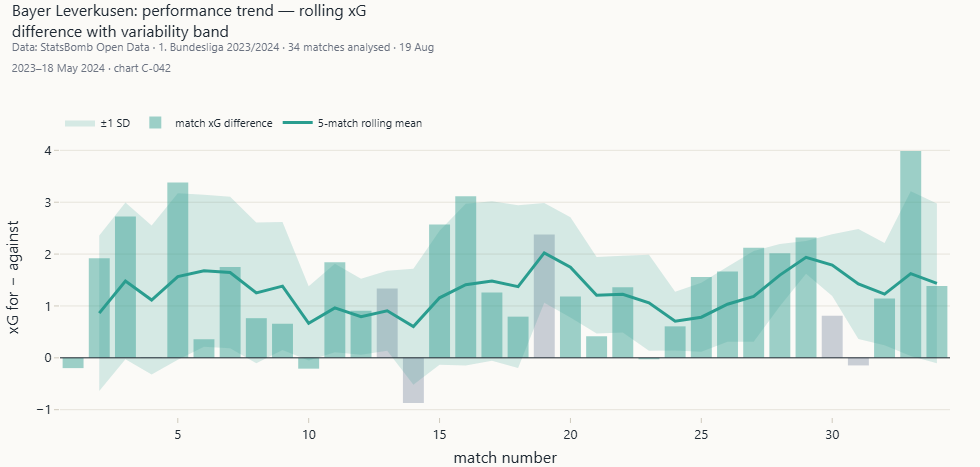

`C-042` Rolling performance form · *Method:* 5-match rolling xG difference with a ±1 SD band.

In [4]:
# Chart explorer: search the catalogue and render one chart on demand.
# With ipywidgets in a live kernel this shows controls; in a headless run it shows the table and one example.
explorer(ws, default="C-042")

## Reproducibility

- `pip install -r requirements.txt`, then run any notebook top to bottom in a fresh kernel.
- `python scripts/run_notebooks.py` executes all of them and writes an execution report.
- Seeds are explicit (`SEED = 42`); the global NumPy generator is never seeded.
- Warnings are not suppressed globally.
- The committed copies were executed with `FMA_STATIC=1`, which stores figures as static images so they are
  visible on GitHub; without it the same cells produce interactive Plotly figures.

In [5]:
from src.reporting.report_builder import environment
display(pd.DataFrame(list(environment().items()), columns=["component", "version"]))
display(timings())

,component,version
0,python,3.10.11
1,platform,Windows-10-10.0.26300-SP0
2,pandas,2.1.4
3,numpy,1.26.2
4,scipy,1.15.3
5,sklearn,1.3.2
6,plotly,6.6.0
7,matplotlib,3.10.8
8,seaborn,0.13.2
9,networkx,3.4.2


,step,seconds
0,load workspace,2.550
1,chart C-042,2.110


---
# Part 01 · Data source, provenance, quality audit and exploratory analysis

## B · Data source, provenance and quality

**Research question.** Where do the data come from, under which terms, and can the parsed tables be trusted
for the analyses built on them?

**Data and method.** The download client records the URL, byte size, SHA-256 hash and write time of every raw
file. Parsed tables are checked against sixteen domain rules and fourteen table contracts (grain, key, required
fields).

In [6]:
from src.data import provenance
from src.data.schemas import check_contracts

man = B.manifest
display(provenance.source_register()[["source", "role_in_project", "terms", "status"]])
display(man.groupby(["resource", "status"]).agg(files=("relative_path", "size"), MB=("bytes", lambda s: round(s.sum() / 1e6, 2))))
display(man[["relative_path", "bytes", "sha256", "file_written_utc"]].head(4))
print("Terms recorded from the source licence:")
for t in provenance.TERMS_SUMMARY:
    print(" -", t)
interpret(f"{len(man)} raw files ({man.bytes.sum() / 1e6:.1f} MB) were read with {int((man.status != 'ok').sum())} failures; "
          f"each has a SHA-256 hash in `data/manifest/source_manifest.json`. The user agreement allows research "
          f"use and public sharing of analysis but not redistribution of the data, so this repository contains "
          f"no raw or processed event tables.")

,source,role_in_project,terms,status
0,StatsBomb Open Data (Hudl),"PRIMARY: competitions, matches (incl. managers...",StatsBomb Public Data User Agreement (LICENSE....,used
1,API-Football v3,"OPTIONAL enrichment (coach, injuries, fixtures...",Subscription terms of the provider; coverage v...,not used by default (no key supplied)
2,Metrica Sports sample data,OPTIONAL separate tracking demo only (anonymis...,See repository licence,not used
3,football-data.co.uk,OPTIONAL supplementary team-level results only,See website notes,not used
4,User-supplied files,USER_DATA mode (StatsBomb-format JSON) and opt...,User must hold rights to use the files,optional


,,files,MB
resource,status,,
competitions,ok,1,0.030
events,ok,34,119.220
lineups,ok,34,0.730
matches,ok,1,0.060


,relative_path,bytes,sha256,file_written_utc
0,competitions.json,34887,e6cd42f5d8956d6aa30fb917ce8d4c3b3df1879a93f02f...,2026-11-01T16:47:55+00:00
1,matches/9/281.json,63079,13dff90f126d9f73da410ae3292b2773744657d3ba968a...,2026-11-01T16:47:55+00:00
2,events/3895052.json,3205861,ecc00b4e7ddd0154532329091d5d82fd7de4b9f6aa8da1...,2026-11-01T16:47:56+00:00
3,lineups/3895052.json,22124,485e5e4f06136578a5dd18648397808110978cadb36a63...,2026-11-01T16:47:56+00:00


Terms recorded from the source licence:
 - The data are provided for analysis and research; analysis and conclusions may be shared publicly (1.1).
 - The user may not edit, distort, distribute, reproduce, sell or provide the data to third parties (1.2.1).
 - No commercial exploitation of the data or of analysis derived from it (1.2.2).
 - Publications of analysis must be accredited with the StatsBomb brand logo (1.4).
 - The service is provided as is; StatsBomb may withdraw it at any time (2.1, 3.2).


**Interpretation.** 70 raw files (120.1 MB) were read with 0 failures; each has a SHA-256 hash in `data/manifest/source_manifest.json`. The user agreement allows research use and public sharing of analysis but not redistribution of the data, so this repository contains no raw or processed event tables.

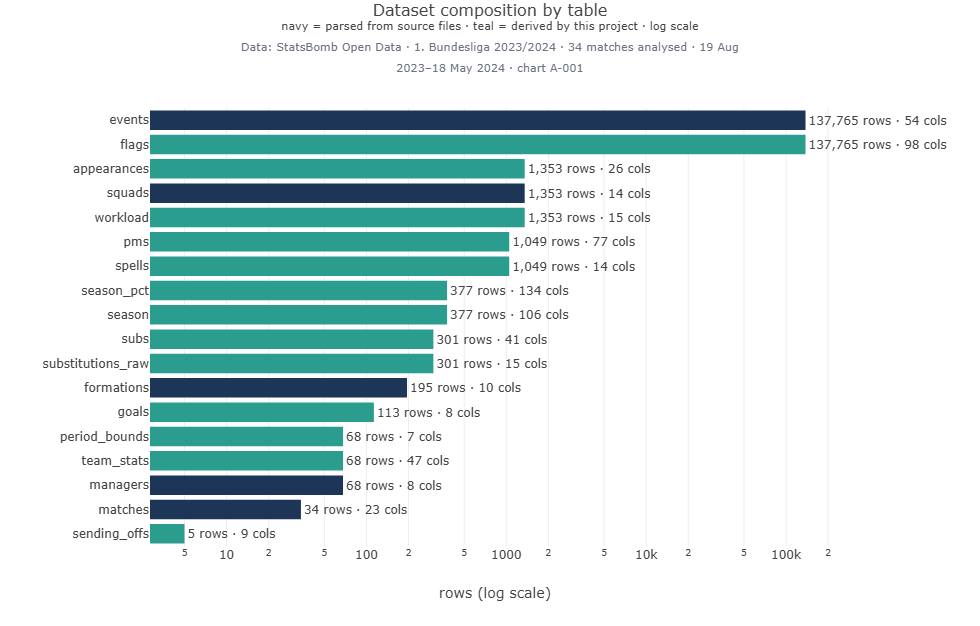

`A-001` Dataset composition by table · *Method:* Row and column counts of every canonical and derived table; log scale.

,table,origin,rows,grain,status,duplicate_keys
0,matches,source,34,one row per match,PASS,0
1,managers,source,68,one row per match and team,PASS,0
2,events,source,137765,one row per event,PASS,0
3,squads,source,1353,"one row per match, team and squad player",PASS,0
4,appearances,derived,1353,one row per match and squad player,PASS,0
5,spells,derived,1049,one row per continuous on-pitch spell,PASS,0
6,goals,derived,113,one row per goal,PASS,0
7,formations,source,195,one row per formation record,PASS,0
8,flags,derived,137765,one row per event,PASS,0
9,pms,derived,1049,one row per player and match,PASS,0


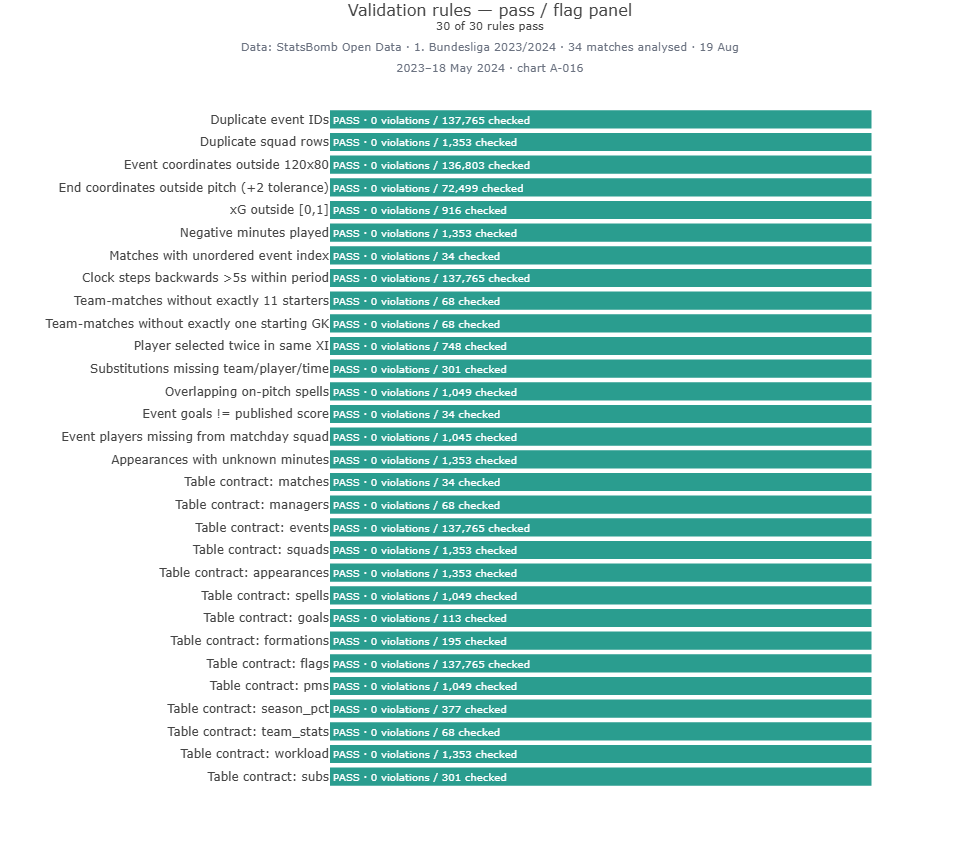

`A-016` Validation rule pass / fail panel · *Method:* Sixteen domain rules plus fourteen table contracts.

**Interpretation.** 16 of 16 domain rules and 14 of 14 table contracts pass: event IDs are unique, coordinates lie on the 120 × 80 pitch, xG is within [0, 1] and attached only to shots, every team-match has eleven starters and one goalkeeper, on-pitch spells do not overlap and the goals rebuilt from events equal the published scores.

**Limitation.** Passing validation shows internal consistency, not that the provider's event tagging is error-free.

In [7]:
show("A-001", ws)
contracts = check_contracts(B)
display(contracts[["table", "origin", "rows", "grain", "status", "duplicate_keys"]])
show("A-016", ws)
q = B.quality
interpret(f"{int((q.status == 'PASS').sum())} of {len(q)} domain rules and {int((contracts.status == 'PASS').sum())} of "
          f"{len(contracts)} table contracts pass: event IDs are unique, coordinates lie on the 120 × 80 pitch, xG is "
          f"within [0, 1] and attached only to shots, every team-match has eleven starters and one goalkeeper, "
          f"on-pitch spells do not overlap and the goals rebuilt from events equal the published scores.")
limitation("Passing validation shows internal consistency, not that the provider's event tagging is error-free.")

### Missing values, duplicates and outliers

**Question.** Which gaps are structural, and are extreme values errors or football?

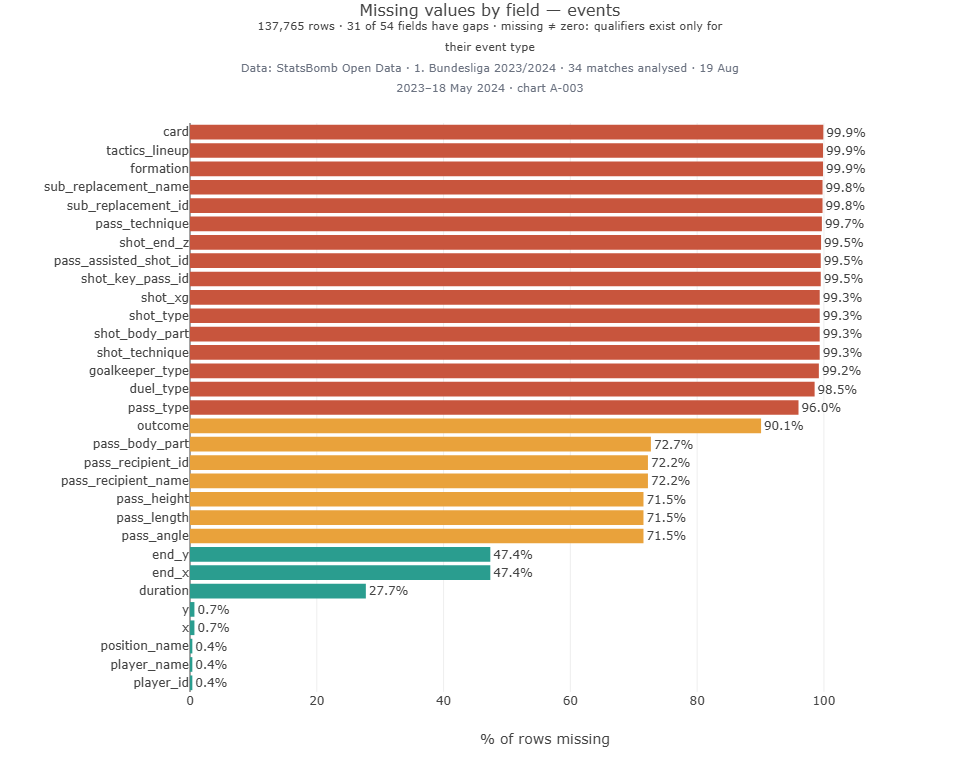

`A-003` Missingness by field · *Method:* Share of missing values per event field. · *Caveat:* Most gaps are structural: a qualifier exists only for its event type.

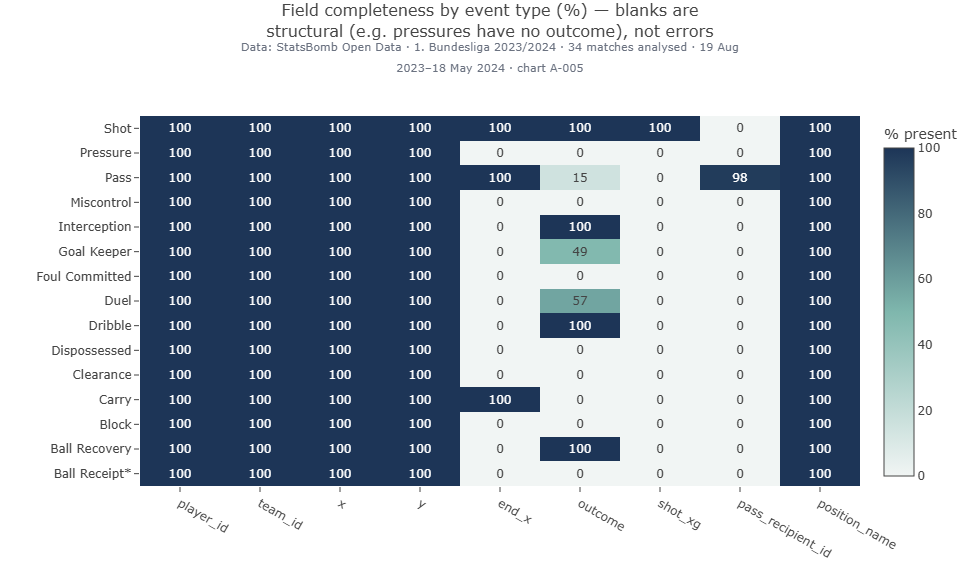

`A-005` Missingness by event type · *Method:* Completeness of each field within each event type.

**Interpretation.** Most fields are sparse by design: `shot_xg` is present on 0.7% of all events but on 100% of the 916 shots; pass end locations exist for 100% of passes. Missing values are kept as missing and are never read as zero.

In [8]:
show("A-003", ws)
show("A-005", ws)
ev = T["events"]
shots = ev[ev.type == "Shot"]
interpret(f"Most fields are sparse by design: `shot_xg` is present on {ev.shot_xg.notna().mean():.1%} of all events but on "
          f"{shots.shot_xg.notna().mean():.0%} of the {len(shots):,} shots; pass end locations exist for "
          f"{ev.loc[ev.type == 'Pass', 'end_x'].notna().mean():.0%} of passes. Missing values are kept as missing and "
          f"are never read as zero.")

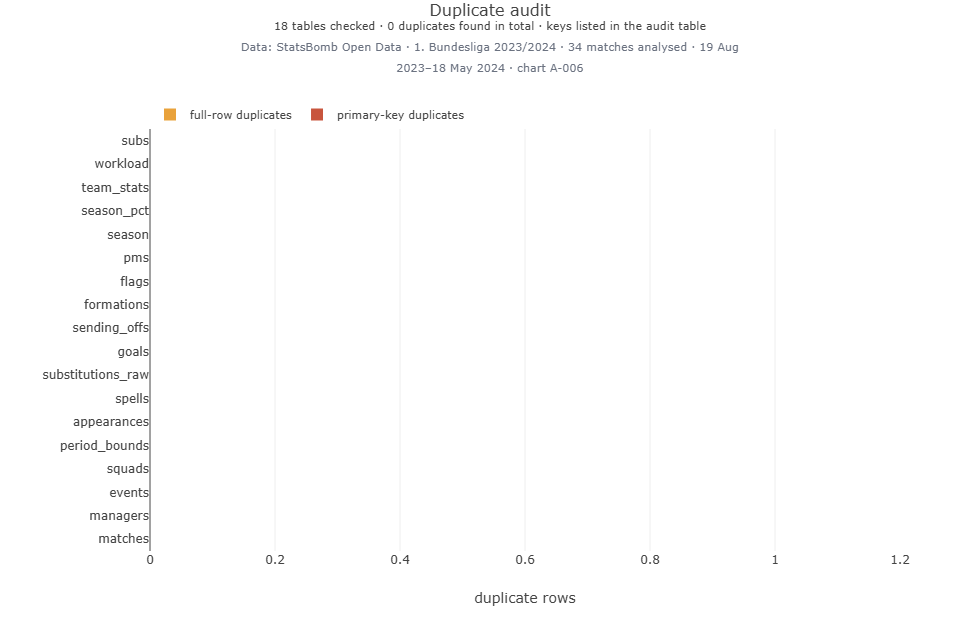

`A-006` Duplicate full-row and primary-key counts · *Method:* Counts of duplicated full rows and duplicated primary keys per table.

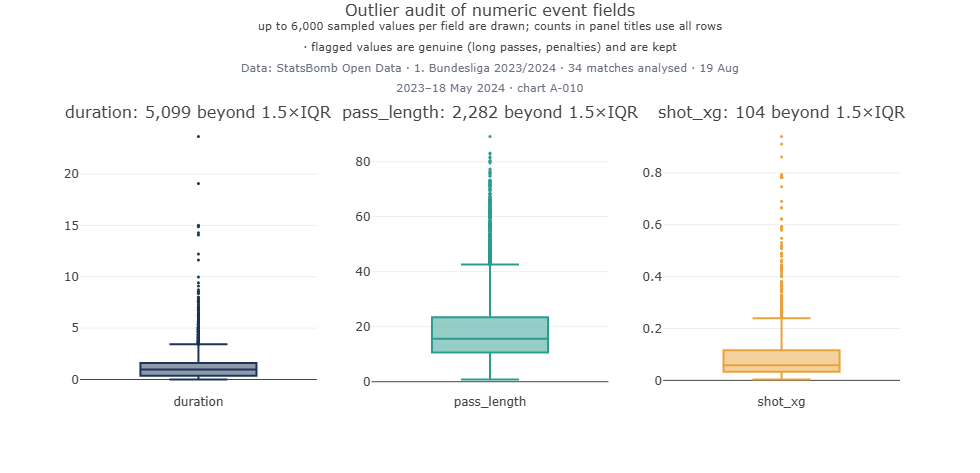

`A-010` Outlier distributions · *Method:* Box plots with the count beyond 1.5 × IQR. · *Caveat:* Flagged values are genuine events and are kept.

**Interpretation.** 0 duplicated rows and 0 duplicated keys across 18 tables. Values beyond 1.5 × IQR are real events (long passes, penalties, long stoppages) and are kept.

In [9]:
from src.visualization import audit
dups = audit.duplicate_audit_table(B)
show("A-006", ws)
show("A-010", ws)
interpret(f"{int(dups.full_row_duplicates.sum())} duplicated rows and {int(dups.key_duplicates.fillna(0).sum())} duplicated keys across "
          f"{len(dups)} tables. Values beyond 1.5 × IQR are real events (long passes, penalties, long stoppages) and are kept.")

### What the data support, and what they do not

**Question.** Which analytical inputs exist? The answer is read from the tables, not assumed.

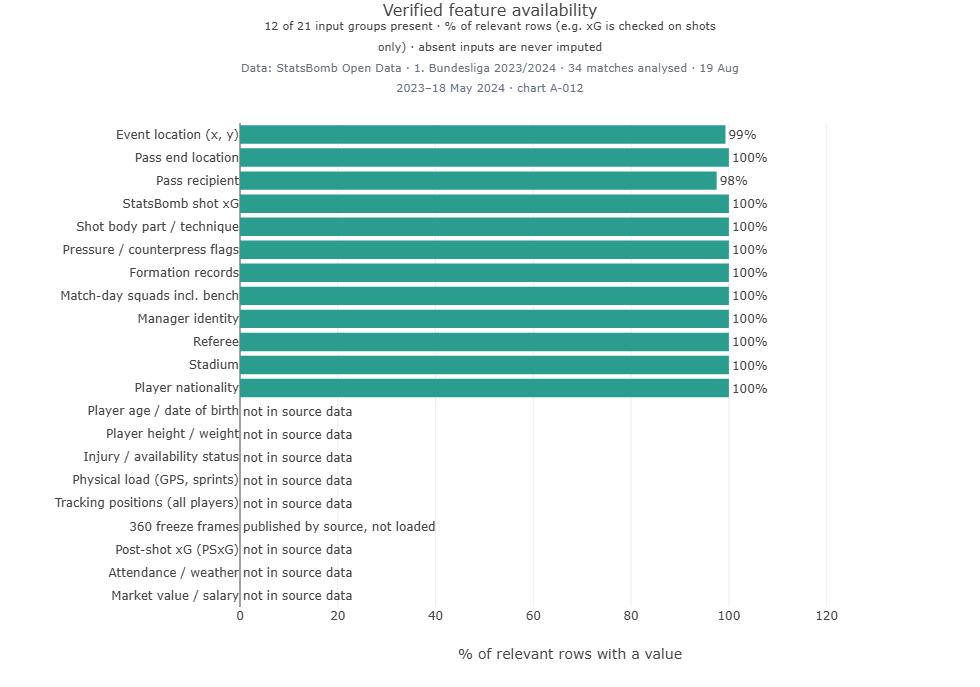

`A-012` Feature availability · *Method:* Verified from the loaded tables; absent modalities are listed, never imputed.

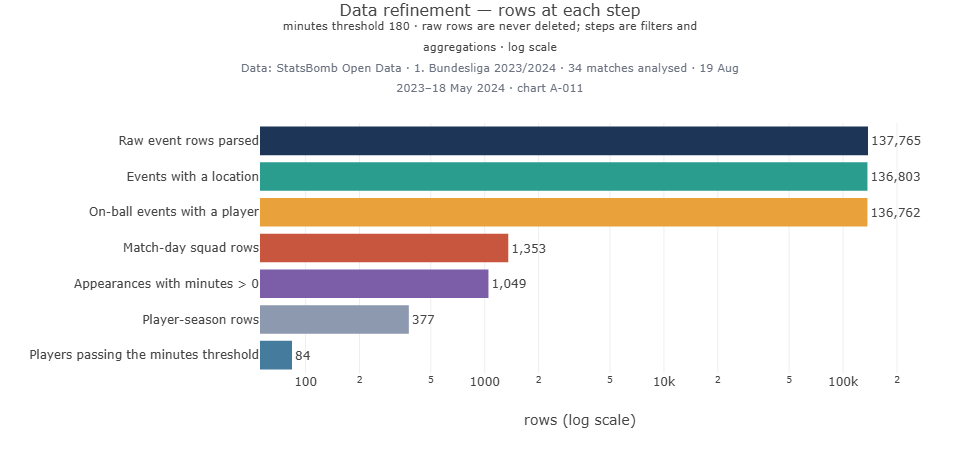

`A-011` Before / after refinement funnel · *Method:* Row counts from raw events to eligible player-seasons.

**Interpretation.** 12 of 21 input groups are present. Not available: Player age / date of birth; Player height / weight; Injury / availability status; Physical load (GPS, sprints); Tracking positions (all players); 360 freeze frames; Post-shot xG (PSxG); Attendance / weather; Market value / salary. None of these is imputed, and no chart that needs them is drawn.

**Managerial implication.** Selection and substitution tools built on this data cannot know who is injured or tired; the analyst must supply availability.

In [10]:
show("A-012", ws)
show("A-011", ws)
fa = audit.feature_availability_table(B)
absent = fa[fa.status != "available"].feature.tolist()
interpret(f"{int((fa.status == 'available').sum())} of {len(fa)} input groups are present. Not available: "
          + "; ".join(absent) + ". None of these is imputed, and no chart that needs them is drawn.")
implication("Selection and substitution tools built on this data cannot know who is injured or tired; the analyst "
            "must supply availability.")

,match_id,frames,joined_to_events
0,3895052,3181,3181
1,3895158,3318,0


**Interpretation.** 2 optional 360 file(s) are cached. 1 of them share no identifier with their event file — a source inconsistency; those frames are not used.

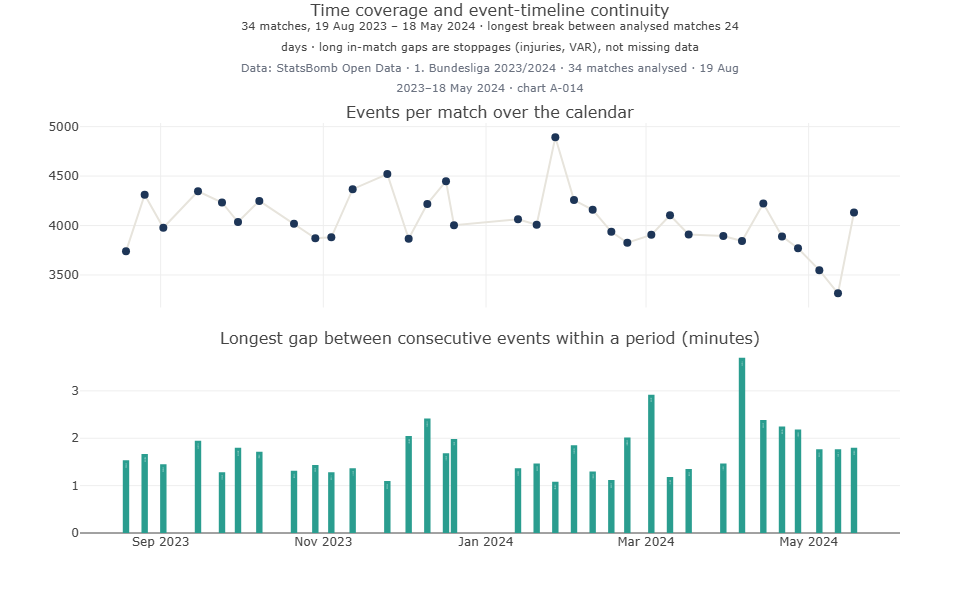

`A-014` Time coverage and event-timeline gaps · *Method:* Events per match over the calendar and the longest within-period gap.

In [11]:
# Optional 360 freeze frames: published by the source, downloaded per match only on request.
# When files are cached, check that their identifiers actually join to the event file before using them.
import json
d360 = B.config.raw_dir / "three-sixty"
rows = []
for p in sorted(d360.glob("*.json")) if d360.exists() else []:
    frames = json.loads(p.read_text(encoding="utf-8"))
    ids = set(ev.loc[ev.match_id == int(p.stem), "event_id"])
    rows.append({"match_id": int(p.stem), "frames": len(frames), "joined_to_events": len(ids & {f["event_uuid"] for f in frames})})
check360 = pd.DataFrame(rows)
if len(check360):
    display(check360)
    bad = check360[check360.joined_to_events == 0]
    interpret(f"{len(check360)} optional 360 file(s) are cached. " + (f"{len(bad)} of them share no identifier with their "
              f"event file — a source inconsistency; those frames are not used." if len(bad) else "All of them join to their events."))
else:
    print("No 360 file is cached; chart E-129 is reported as implemented_but_unavailable.")
show("A-014", ws)

## C · Feature engineering and exploratory analysis

**Question.** After normalising for playing time and role, how are player metrics distributed and how do they
relate?

**Data and method.** Minutes are rebuilt from the event stream. Per-90 values are `value / minutes × 90` and
percentiles are computed within the player's role group among players above the minutes threshold.

,metric,definition,numerator,denominator,unit,source_fields
0,minutes_played,Actual playing time on pitch incl. stoppage (p...,sum of spell lengths,-,minutes,"events: Starting XI, Substitution, Foul Commit..."
1,goals,Shots with outcome Goal in periods 1-4 (shoot-...,count,-,goals,shot.outcome
2,npxg,Sum of StatsBomb xG on non-penalty shots,sum xG,-,xG,"shot.statsbomb_xg, shot.type"
3,xg,Sum of StatsBomb xG on all shots (periods 1-4),sum xG,-,xG,shot.statsbomb_xg
4,xa,xG of shots assisted by the player's passes (p...,sum xG,-,xG,"pass.assisted_shot_id, shot.statsbomb_xg"
5,shots,Shot events (periods 1-4),count,-,shots,type=Shot
6,shots_on_target,Shots with outcome Goal / Saved / Saved To Post,count,-,shots,shot.outcome
7,assists,Passes flagged goal_assist by StatsBomb,count,-,assists,pass.goal_assist
8,key_passes,Passes flagged shot_assist or goal_assist,count,-,passes,"pass.shot_assist, pass.goal_assist"
9,passes,Pass attempts,count,-,passes,type=Pass


,metric,formula,inputs,caveat
0,per-90 rate,count or value / minutes played × 90,minutes reconstructed from events,null below the minimum-minutes threshold; neve...
1,role percentile,percentile rank of a per-90 value within the p...,eligible players of the same role group,group size is reported; groups under the minim...
2,possession_proxy_pct,team passes / (team passes + opponent passes) ...,pass attempts of both teams,"a pass-share proxy, not timed possession"
3,field_tilt_pct,team final-third touches / both teams' final-t...,touches with x ≥ 80,territory proxy from on-ball events
4,ppda,opponent passes with x ≤ 72 / team tackles + i...,defensive actions in the opponent's build-up zone,lower = more defensive actions per opponent pa...
5,xg_diff,sum of StatsBomb xG for − against in a match,—,xG is the provider's model output
6,expected points (xPts),"mean points over 5,000 simulations in which ev...",per match,assumes independent shots; ignores game state
7,progressive pass,completed pass starting at x ≥ 48 that ends at...,—,project definition; other providers use differ...


84 of 377 player-team rows have at least 180 minutes; 17 have at least 900.


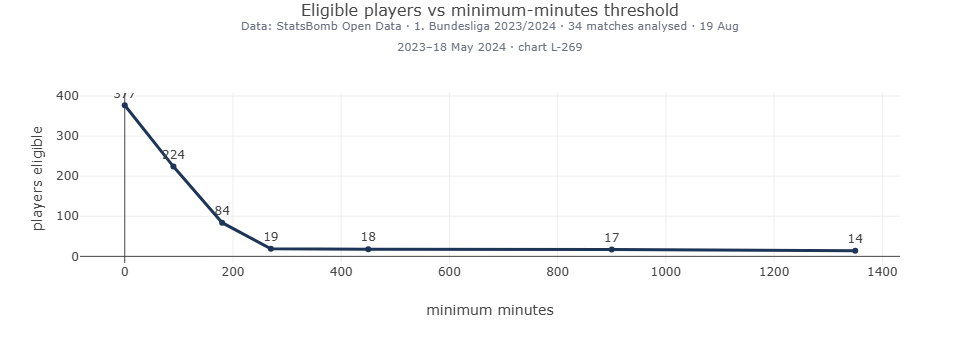

`L-269` Minimum-minutes sensitivity · *Method:* Eligible players by threshold.

In [12]:
from src.features.player_features import metric_dictionary
from src.reporting.report_builder import DERIVED_METRICS
from src.workspace import EDA_METRICS

display(metric_dictionary().head(12))
display(pd.DataFrame(DERIVED_METRICS, columns=["metric", "formula", "inputs", "caveat"]).head(8))
s = B.season
print(f"{int(s.eligible.sum())} of {len(s)} player-team rows have at least {B.config.min_minutes:.0f} minutes; "
      f"{int((s.minutes_played >= 900).sum())} have at least 900.")
show("L-269", ws)

,players,xg_p90,key_passes_p90,progressive_passes_p90,interceptions_p90,pass_completion_pct
role_family,,,,,,
Defender,38,0.020,0.278,1.832,1.396,84.443
Forward,10,0.325,0.724,0.604,0.082,74.807
Goalkeeper,14,0.000,0.000,0.000,0.000,74.776
Midfielder,22,0.034,0.478,1.394,0.976,84.826


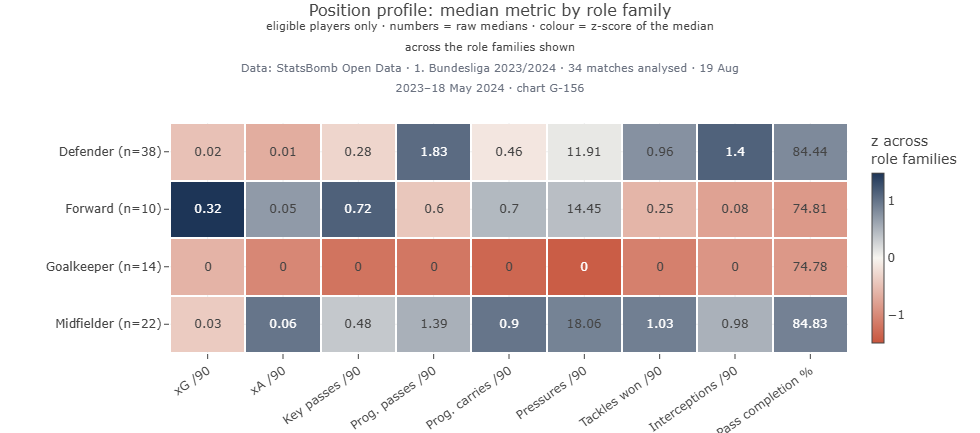

`G-156` Position / role metric profile · *Method:* Median metric by role family (z-coloured, raw values printed).

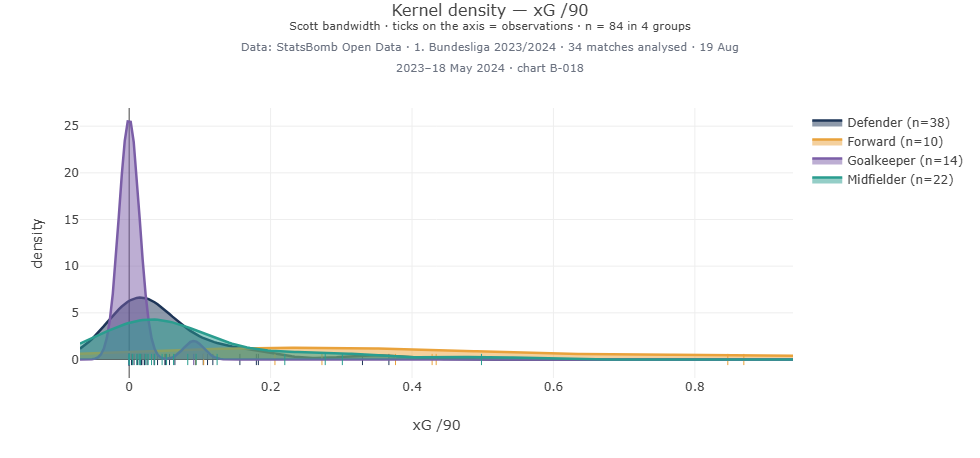

`B-018` KDE by role family · *Method:* Gaussian KDE, Scott bandwidth; rug of points. · *Caveat:* Groups under 5 values are not drawn.

**Interpretation.** Role families separate clearly on some metrics: median xG/90 is highest for Forwards (0.32) and lowest for Defenders (0.02); interceptions/90 peak for Defenders (1.40). Group sizes: Defender 38, Forward 10, Goalkeeper 14, Midfielder 22.

**Managerial implication.** Compare players inside their role group. A raw leaderboard mostly re-discovers positions.

In [13]:
from src.analytics import descriptive as desc
rm = desc.role_medians(B, ["xg_p90", "key_passes_p90", "progressive_passes_p90", "interceptions_p90", "pass_completion_pct"])
display(rm)
show("G-156", ws)
show("B-018", ws, metric="xg_p90")
fams = rm.drop(index="Goalkeeper", errors="ignore")
interpret(f"Role families separate clearly on some metrics: median xG/90 is highest for {fams.xg_p90.idxmax()}s "
          f"({fams.xg_p90.max():.2f}) and lowest for {fams.xg_p90.idxmin()}s ({fams.xg_p90.min():.2f}); interceptions/90 "
          f"peak for {fams.interceptions_p90.idxmax()}s ({fams.interceptions_p90.max():.2f}). Group sizes: "
          + ", ".join(f"{i} {int(n)}" for i, n in rm.players.items()) + ".")
implication("Compare players inside their role group. A raw leaderboard mostly re-discovers positions.")

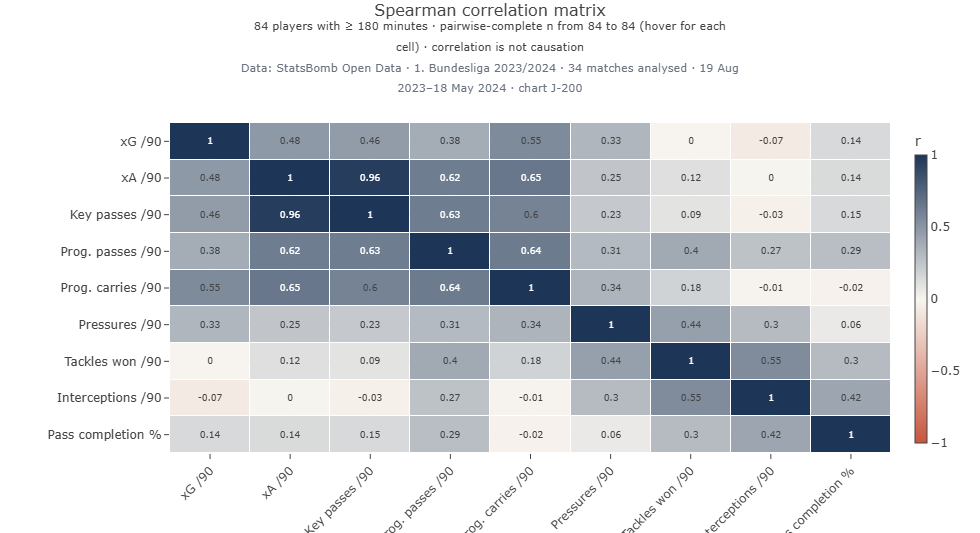

`J-200` Spearman rank correlation matrix · *Method:* Rank-based; robust to skew.

**Interpretation.** Among 84 eligible players the strongest positive rank correlation is between xa_p90 and key_passes_p90 (ρ = 0.96) and the strongest negative between xg_p90 and interceptions_p90 (ρ = -0.07). Pairwise n ranges from 84 to 84.

**Limitation.** Players are nested in teams and opponents are observed only against the focus team; these are descriptive associations.

In [14]:
from src.analytics import statistical_tests as stt
el = ws.eligible()
r, n = stt.correlation_matrix(el, EDA_METRICS, "spearman")
show("J-200", ws)
pairs = r.where(np.triu(np.ones(r.shape, bool), 1)).stack().sort_values()
lo, hi = pairs.index[0], pairs.index[-1]
interpret(f"Among {len(el)} eligible players the strongest positive rank correlation is between {hi[0]} and {hi[1]} "
          f"(ρ = {pairs.iloc[-1]:.2f}) and the strongest negative between {lo[0]} and {lo[1]} (ρ = {pairs.iloc[0]:.2f}). "
          f"Pairwise n ranges from {int(n.values.min())} to {int(n.values.max())}.")
limitation("Players are nested in teams and opponents are observed only against the focus team; these are "
           "descriptive associations.")

---
# Part 02 · Match, team and player performance

## D · Match, team and player performance

**Research question.** How did the team perform, how much of it is explained by chance quality, and which
players drive it?

**Data and method.** Team match statistics (goals, StatsBomb xG, shots, pass-share possession proxy, field
tilt, PPDA) and player season tables with per-90 rates and role percentiles. Expected points simulate each shot
as a Bernoulli trial with its xG.

,matches,W-D-L,points,expected points,goals,xG,players used
0,34,28-6-0,90.000,74.800,89-24,72.7-27.8,24


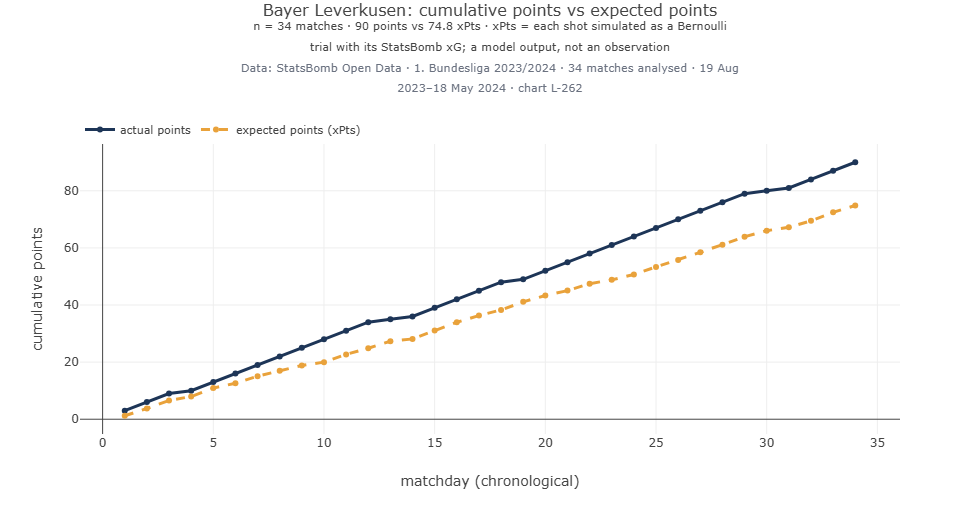

`L-262` Points versus expected points · *Method:* Shot-level Bernoulli simulation (5,000 runs per match). · *Caveat:* xPts is a model output.

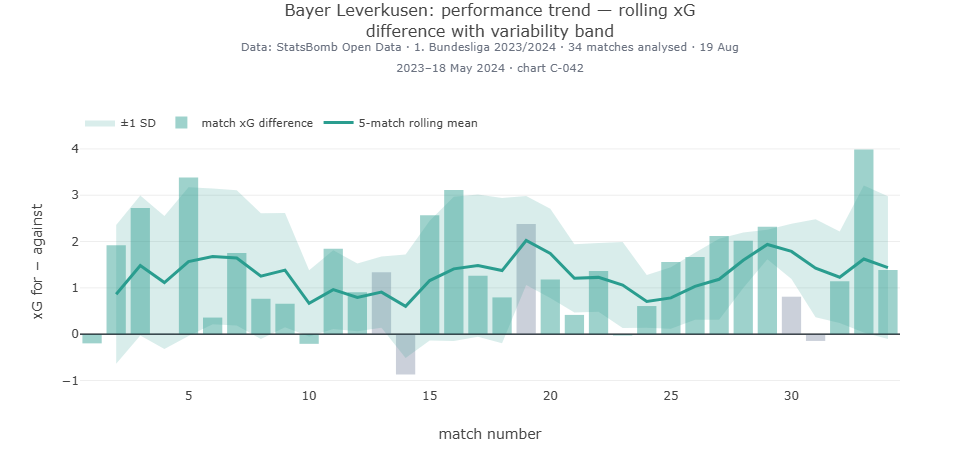

`C-042` Rolling performance form · *Method:* 5-match rolling xG difference with a ±1 SD band.

**Interpretation.** Bayer Leverkusen took 90 points from 34 matches against 74.8 expected from shot quality — 15.2 more than the simulation — and scored 89 goals from 72.7 xG. Mean xG difference per match: +1.32.

**Managerial implication.** Judge performances on chances created and conceded; the points total alone flatters or punishes a team for finishing and goalkeeping variance.

**Limitation.** Expected points are a model output: shots are treated as independent and game state is ignored.

In [15]:
from src.analytics import descriptive as desc
k = desc.season_kpis(B, FOCUS)
xp = ws.xpts(); xp = xp[xp.team_name == FOCUS]
display(pd.DataFrame([{"matches": k["matches"], "W-D-L": f"{k['wins']}-{k['draws']}-{k['losses']}", "points": k["points"],
                       "expected points": round(xp.xpts.sum(), 1), "goals": f"{k['goals_for']}-{k['goals_against']}",
                       "xG": f"{k['xg_for']:.1f}-{k['xg_against']:.1f}", "players used": k["players_used"]}]))
show("L-262", ws)
show("C-042", ws)
gap = k["points"] - xp.xpts.sum()
interpret(f"{FOCUS} took {k['points']:.0f} points from {k['matches']} matches against {xp.xpts.sum():.1f} expected from shot "
          f"quality — {abs(gap):.1f} {'more' if gap > 0 else 'fewer'} than the simulation — and scored {k['goals_for']} "
          f"goals from {k['xg_for']:.1f} xG. Mean xG difference per match: {tm.xg_diff.mean():+.2f}.")
implication("Judge performances on chances created and conceded; the points total alone flatters or punishes a "
            "team for finishing and goalkeeping variance.")
limitation("Expected points are a model output: shots are treated as independent and game state is ignored.")

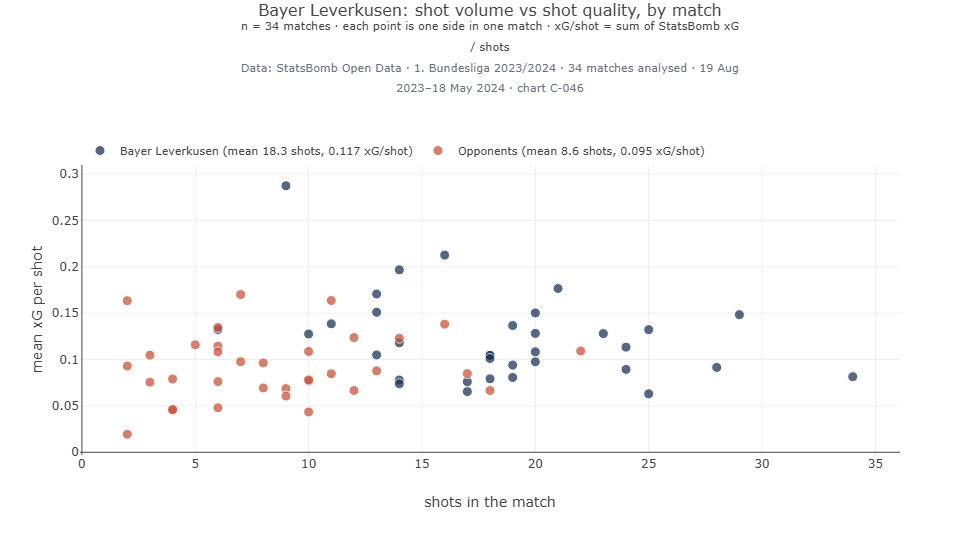

`C-046` Shot volume versus shot quality · *Method:* Shots vs mean xG per shot, team and opponents.

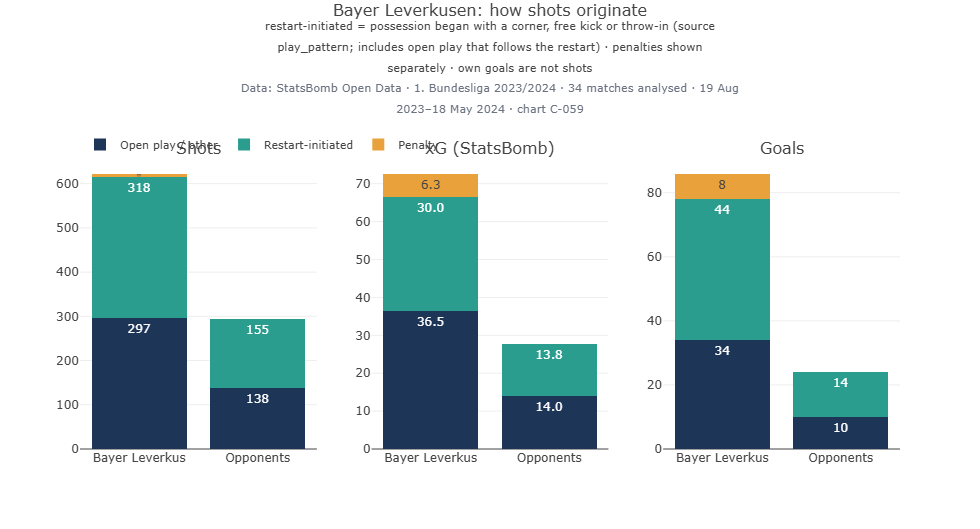

`C-059` Set-piece versus open-play contribution · *Method:* Shots, xG and goals by how the possession started.

**Interpretation.** Bayer Leverkusen took 623 shots against 293 for opponents; xG per shot was 0.117 against 0.095. The gap in **volume** is far larger than the gap in **quality**. Possessions that began with a corner, free kick or throw-in produced 44 of the team's goals from shots.

In [16]:
show("C-046", ws)
show("C-059", ws)
split = desc.shot_origin_split(B, FOCUS).set_index(["side", "origin"])
f = split.loc["for"]; a = split.loc["against"]
interpret(f"{FOCUS} took {int(f.shots.sum())} shots against {int(a.shots.sum())} for opponents; xG per shot was "
          f"{f.xg.sum() / f.shots.sum():.3f} against {a.xg.sum() / a.shots.sum():.3f}. The gap in **volume** is far larger than "
          f"the gap in **quality**. Possessions that began with a corner, free kick or throw-in produced "
          f"{int(f.loc['Restart-initiated', 'goals'])} of the team's goals from shots.")

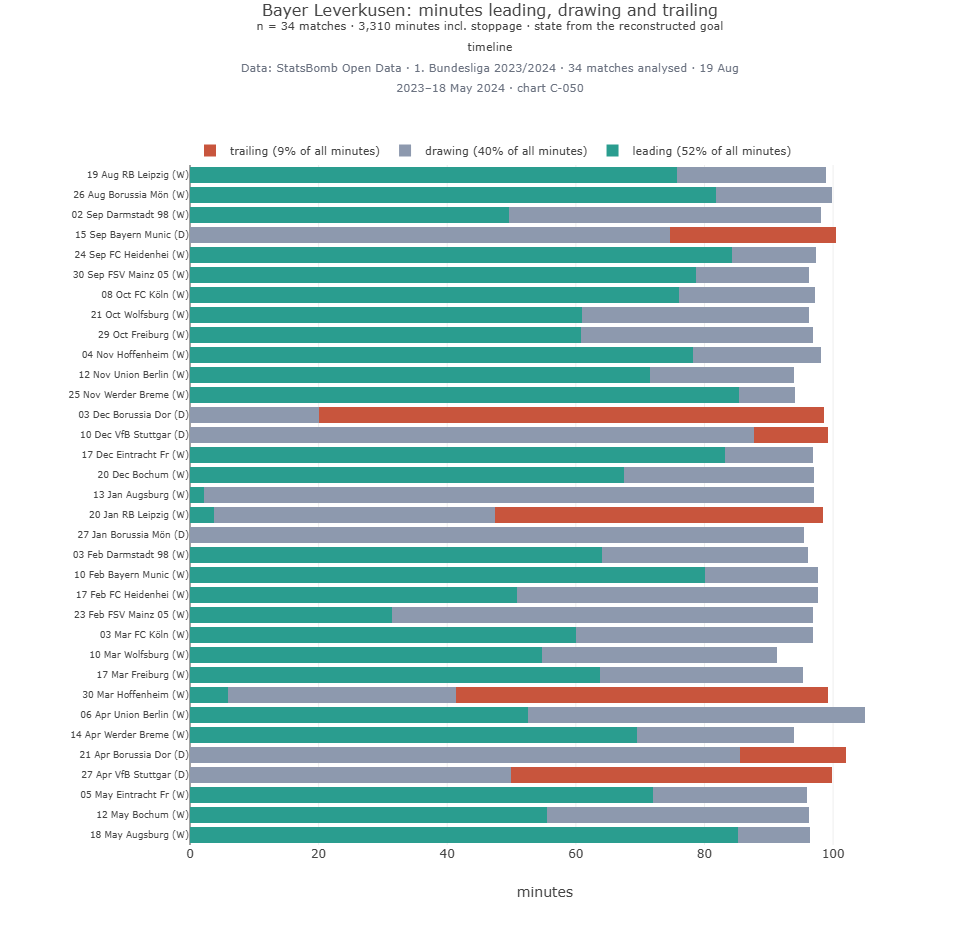

`C-050` Score-state time share · *Method:* Minutes per state from the reconstructed goal timeline.

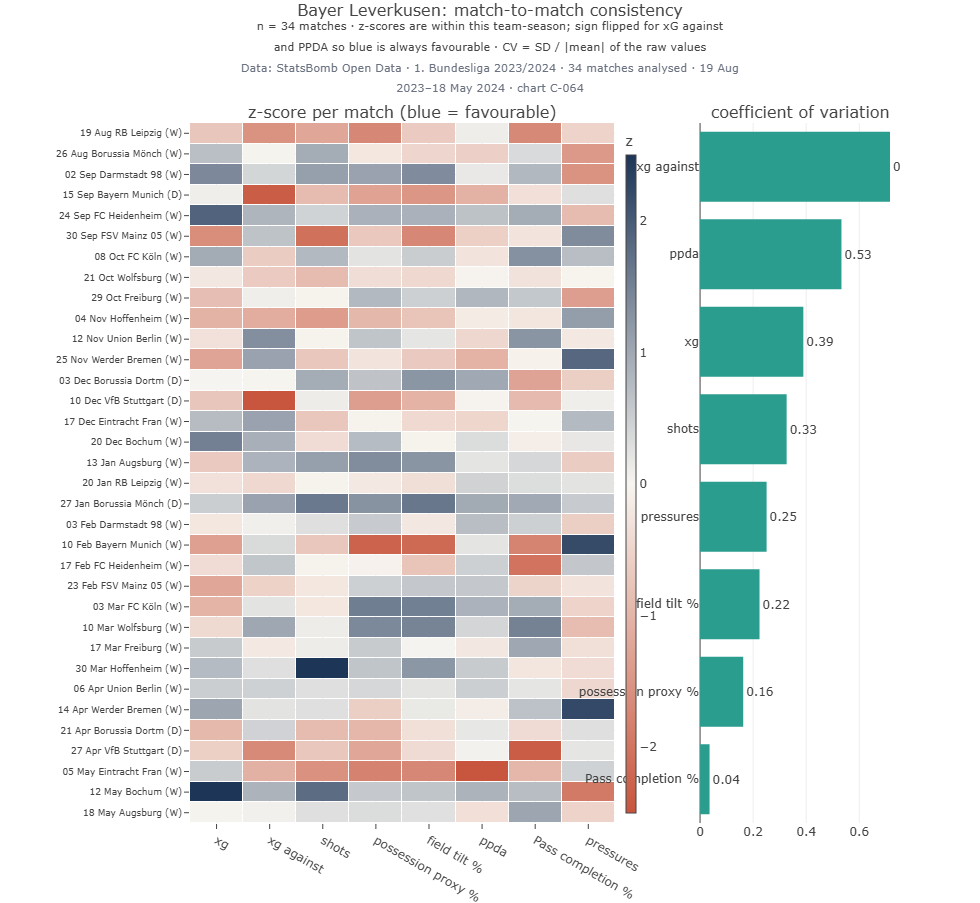

`C-064` Team consistency heatmap · *Method:* Within-season z-scores and coefficient of variation.

**Interpretation.** The team spent 52% of its minutes leading, 40% level and 9% behind. The most stable match metrics are pass_completion_pct (CV 0.04) and possession_proxy_pct (0.16); the most volatile are xg_against (0.72) and ppda (0.53).

**Managerial implication.** Swings in the volatile metrics are normal match-to-match noise; persistent change in the stable ones is the earlier warning sign.

In [17]:
show("C-050", ws)
show("C-064", ws)
st_time = ws.state_time()
tot = st_time[["leading", "drawing", "trailing"]].sum()
z, cv = desc.team_consistency(B, FOCUS)
interpret(f"The team spent {tot.leading / tot.sum():.0%} of its minutes leading, {tot.drawing / tot.sum():.0%} level and "
          f"{tot.trailing / tot.sum():.0%} behind. The most stable match metrics are {cv.index[0]} (CV {cv.iloc[0]:.2f}) and "
          f"{cv.index[1]} ({cv.iloc[1]:.2f}); the most volatile are {cv.index[-1]} ({cv.iloc[-1]:.2f}) and {cv.index[-2]} ({cv.iloc[-2]:.2f}).")
implication("Swings in the volatile metrics are normal match-to-match noise; persistent change in the stable "
            "ones is the earlier warning sign.")

### One match in detail

**Question.** What happened, in order, in a representative match? The default is the match with the median xG
difference — neither the best nor the worst.

03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund


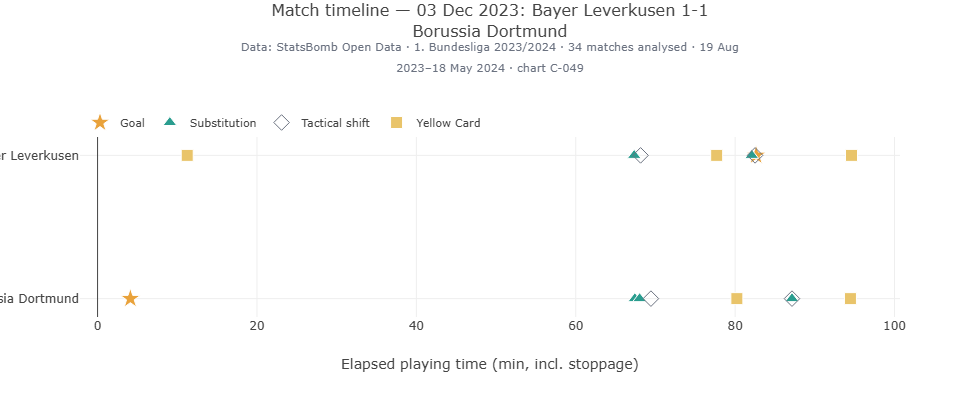

`C-049` Goal and event timeline of a match · *Method:* Goals, cards and substitutions on the elapsed clock.

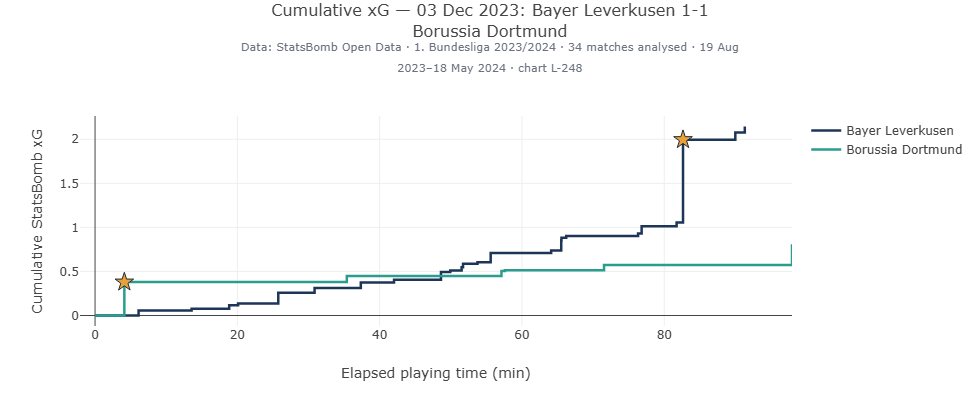

`L-248` Cumulative xG of a match · *Method:* Step chart of StatsBomb xG by team.

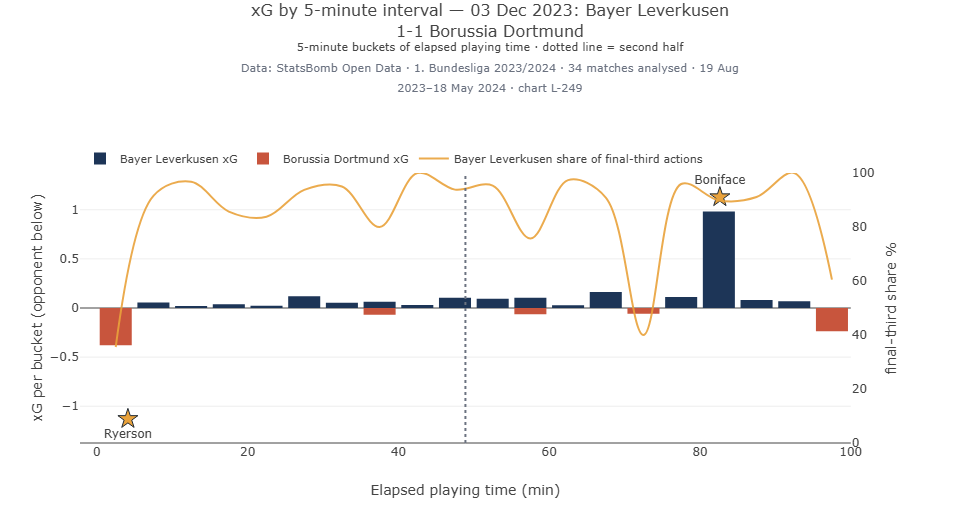

`L-249` Match xG-by-interval chart · *Method:* xG per 5-minute bucket for each side, with final-third touch share. · *Caveat:* This is xG per interval, not a validated momentum measure.

**Limitation.** The interval chart is xG per five minutes — a description of when chances occurred, not a validated momentum measure.

In [18]:
mid = ws.default_match()
print(ws.match_label(mid))
show("C-049", ws, match_id=mid)
show("L-248", ws, match_id=mid)
show("L-249", ws, match_id=mid)
limitation("The interval chart is xG per five minutes — a description of when chances occurred, not a validated "
           "momentum measure.")

### Players

**Question.** Who contributes what, relative to players of the same role, and how certain is it?

,player_name,primary_position,minutes_played,starts,goals,xg,assists,xa,xg_p90,xa_p90,progressive_passes_p90,benchmark_group,benchmark_n,coverage_label
0,Lukáš Hrádecký,Goalkeeper,3214.600,33,0.000,0.000,0.000,0.000,0.000,0.000,0.000,GK,14.000,high data coverage
1,Granit Xhaka,Right Defensive Midfield,3034.767,32,3.000,1.571,0.000,2.606,0.047,0.077,4.893,DM,14.000,high data coverage
2,Álex Grimaldo,Left Wing Back,2994.683,31,10.000,5.209,13.000,9.148,0.157,0.275,4.268,Defender,38.000,high data coverage
3,Jonathan Tah,Center Back,2848.117,30,4.000,1.806,1.000,0.326,0.057,0.010,2.022,CB,22.000,high data coverage
4,Florian Wirtz,Left Attacking Midfield,2528.867,26,11.000,8.471,10.000,7.733,0.301,0.275,7.153,Midfielder,22.000,high data coverage
5,Jeremie Frimpong,Right Wing Back,2378.467,27,9.000,8.720,7.000,4.543,0.330,0.172,2.762,Defender,38.000,high data coverage
6,Jonas Hofmann,Right Attacking Midfield,2334.683,26,4.000,5.709,7.000,7.839,0.220,0.302,3.392,Midfielder,22.000,high data coverage
7,Edmond Fayçal Tapsoba,Left Center Back,2262.517,23,0.000,1.009,1.000,0.652,0.040,0.026,4.057,CB,22.000,high data coverage
8,Odilon Kossonou,Right Center Back,1962.233,21,1.000,0.388,0.000,0.875,0.018,0.040,2.935,CB,22.000,high data coverage
9,Exequiel Palacios,Left Defensive Midfield,1949.783,21,4.000,2.694,4.000,3.334,0.124,0.154,4.616,DM,14.000,high data coverage


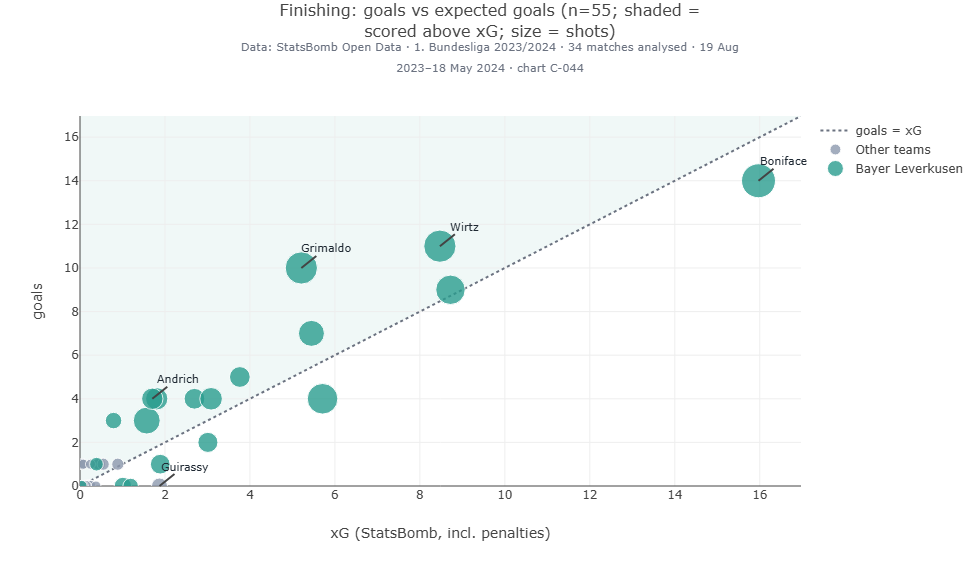

`C-044` Goals versus xG · *Method:* Goals against xG per player. · *Caveat:* Finishing over- or under-performance regresses strongly.

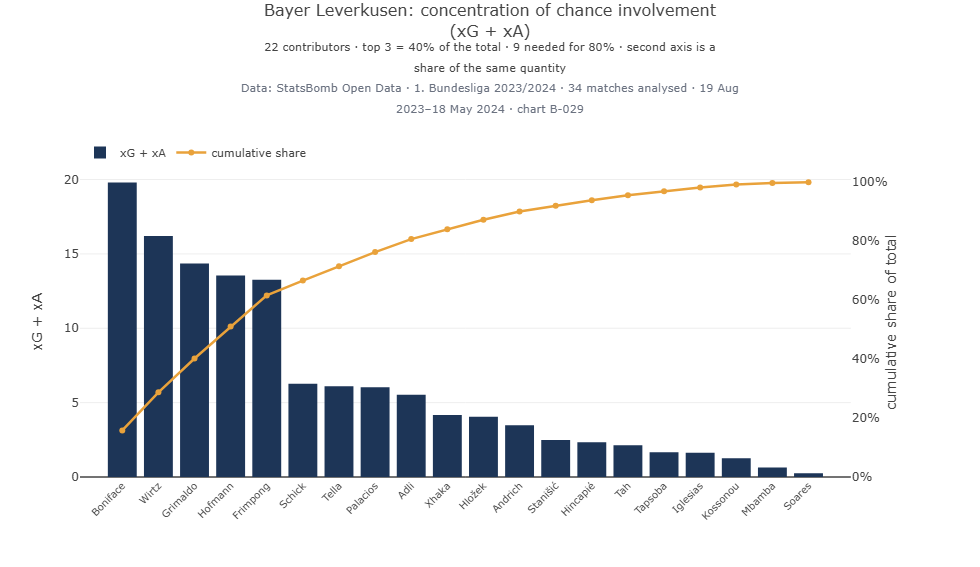

`B-029` Pareto / concentration chart · *Method:* Sorted xG + xA with cumulative share. · *Caveat:* xA is credited to the passer of a shot assist.

**Interpretation.** The top three contributors (Victor Boniface, Florian Wirtz, Álex Grimaldo) account for 40% of the squad's xG + xA; 9 players are needed to reach 80%. Gini coefficient 0.52.

**Managerial implication.** Like-for-like cover and minutes management matter most for the few players who create the chances.

In [19]:
sq = ws.squad()
display(sq[["player_name", "primary_position", "minutes_played", "starts", "goals", "xg", "assists", "xa", "xg_p90", "xa_p90",
            "progressive_passes_p90", "benchmark_group", "benchmark_n", "coverage_label"]].head(14))
show("C-044", ws)
show("B-029", ws)
conc = desc.concentration(sq.set_index("player_name").eval("xg + xa"))
interpret(f"The top three contributors ({', '.join(conc.label.head(3))}) account for {conc.share.head(3).sum():.0%} of the "
          f"squad's xG + xA; {int((conc.cumulative_share < 0.8).sum() + 1)} players are needed to reach 80%. "
          f"Gini coefficient {desc.gini(conc.value):.2f}.")
implication("Like-for-like cover and minutes management matter most for the few players who create the chances.")

Example player: Granit Xhaka


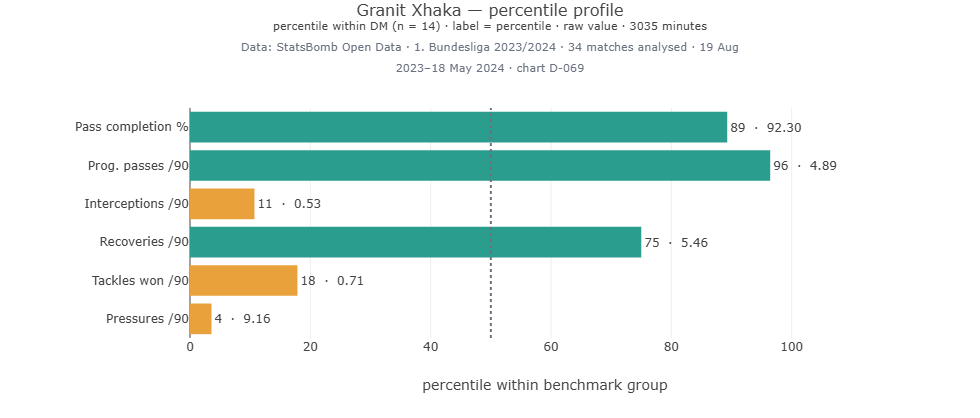

`D-069` Percentile chart by role group · *Method:* Percentile within the benchmark group, with group size.

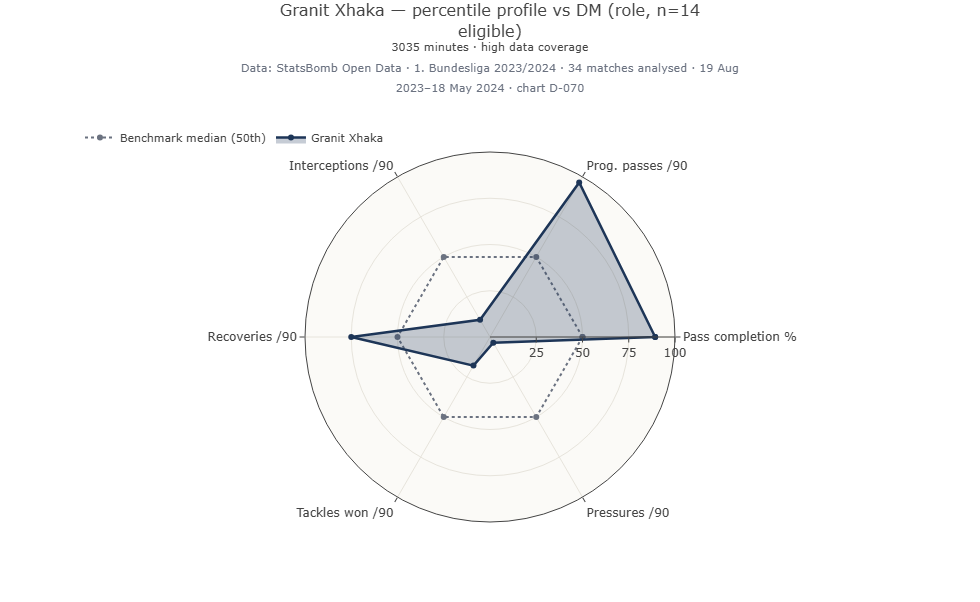

`D-070` Player radar · *Method:* Role metrics as percentiles; all axes higher = higher percentile.

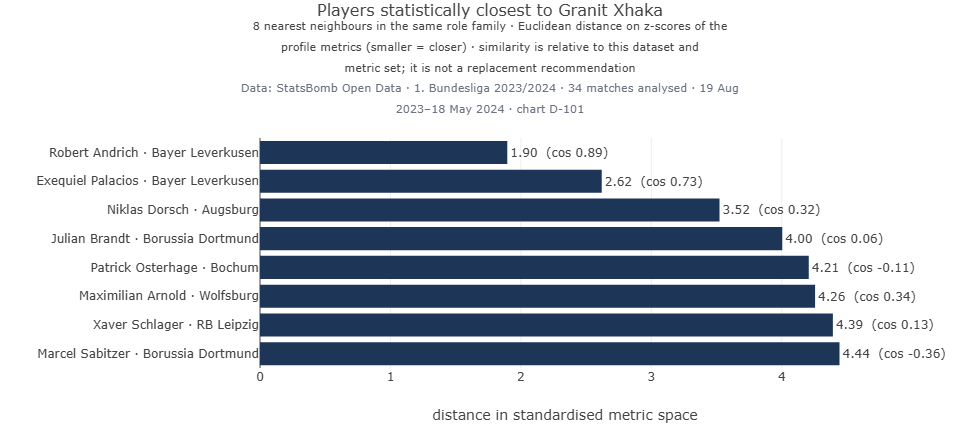

`D-101` Player similarity map · *Method:* Euclidean distance on z-scores within the role family. · *Caveat:* Depends on the metric set and the standardisation sample.

**Limitation.** Similarity is distance in standardised per-90 space within this dataset; it is not a replacement recommendation.

In [20]:
pid = ws.default_player()
print("Example player:", ws.player_name(pid))
show("D-069", ws, player_id=pid)
show("D-070", ws, player_id=pid)
show("D-101", ws, player_id=pid)
limitation("Similarity is distance in standardised per-90 space within this dataset; it is not a replacement "
           "recommendation.")

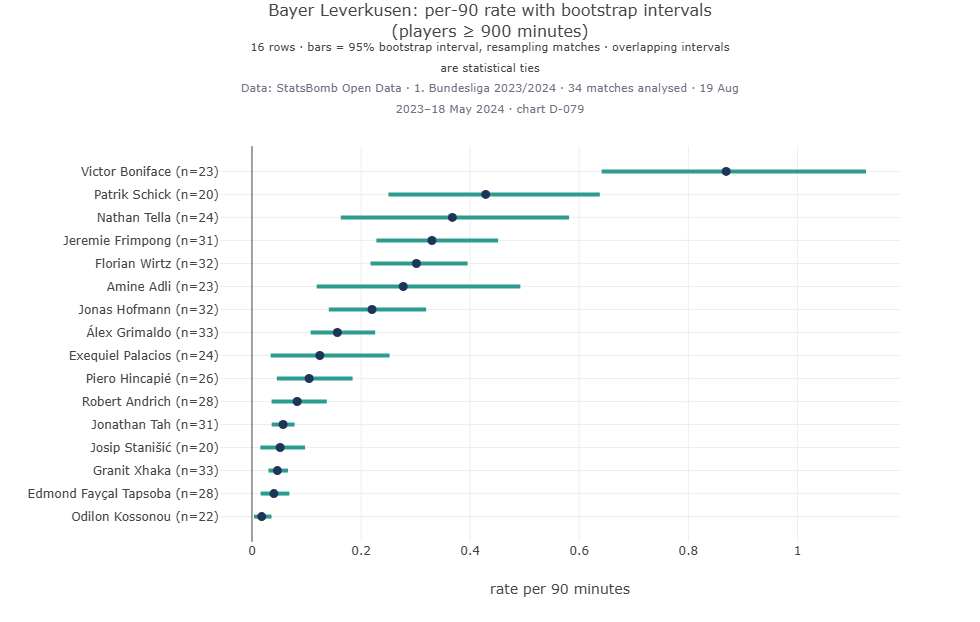

`D-079` Bootstrap confidence intervals per player · *Method:* 2,000 bootstrap resamples of each player's matches.

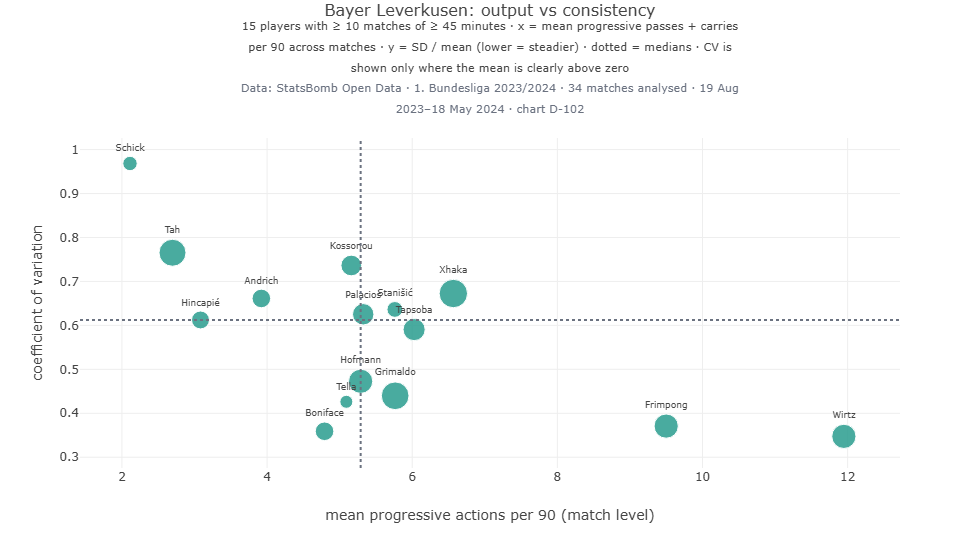

`D-102` Consistency versus output quadrant · *Method:* Mean progressive actions/90 vs coefficient of variation.

**Interpretation.** Victor Boniface leads on xG per 90 (0.87, 95% bootstrap interval 0.64–1.13), which is clearly separated from Patrik Schick (0.25–0.64). Among above-median progressors Florian Wirtz is the steadiest (CV 0.35 at 11.9 progressive actions per 90).

**Managerial implication.** Rank attackers in tiers. Inside overlapping intervals the order is not established by one season.

In [21]:
from src.analytics import uncertainty as unc
reg = sq[(sq.minutes_played >= 900) & (sq.primary_role != "GK")]
ci = unc.bootstrap_rate_intervals(B.pms, reg, "xg", seed=SEED)
show("D-079", ws, metric="xg_p90")
show("D-102", ws)
top, second = ci.iloc[-1], ci.iloc[-2]
sep = "is clearly separated from" if second.hi < top.lo else "overlaps with"
cons = ws.consistency()
steady = cons[cons.prog_mean > cons.prog_mean.median()].sort_values("prog_cv").iloc[0]
interpret(f"{top.player} leads on xG per 90 ({top.rate_p90:.2f}, 95% bootstrap interval {top.lo:.2f}–{top.hi:.2f}), which {sep} "
          f"{second.player} ({second.lo:.2f}–{second.hi:.2f}). Among above-median progressors {steady.player_name} is the "
          f"steadiest (CV {steady.prog_cv:.2f} at {steady.prog_mean:.1f} progressive actions per 90).")
implication("Rank attackers in tiers. Inside overlapping intervals the order is not established by one season.")

---
# Part 03 · Pitch, spatial and tactical analysis

## E · Pitch, spatial and tactical analysis

**Research question.** Where does the team play, how does it move the ball forward, and through whom?

**Data and method.** StatsBomb coordinates: a 120 × 80 pitch with the origin at the top-left corner, and
**every team recorded attacking left to right in both halves**. No per-half flip is applied. Maps that draw
more than 4,000 points or 500 arrows show a seeded random sample and say so.

In [22]:
from src.features.event_features import EVENT_KINDS, select_events
from src.visualization import spatial

fl = ws.flags
tid = ws.team_id()
# Orientation check on the data: shots must cluster near x = 120 for both teams and in both halves
sh = fl[fl.type == "Shot"]
display(sh.assign(side=np.where(sh.team_id == tid, FOCUS, "opponents")).groupby(["side", "period"]).x.agg(["size", "median", "min"]).round(1))
m2 = spatial.mirror(sh.head(3)[["x", "y"]])
print("mirror() flips both axes:", sh.head(3)[["x", "y"]].round(1).values.tolist(), "→", m2.round(1).values.tolist())
interpret(f"Median shot location is x = {sh.x.median():.0f} for every team and half, confirming that the source records "
          f"each team attacking towards x = 120 throughout. The coordinate transform is covered by `tests/test_chart_renderers.py`.")

size  median    min
side             period                     
Bayer Leverkusen 1        294 105.000 86.600
                 2        329 105.900 57.700
opponents        1        145 105.900 73.700
                 2        148 104.700 79.400

mirror() flips both axes: [[92.2, 27.1], [107.0, 23.2], [96.2, 44.8]] → [[27.8, 52.9], [13.0, 56.8], [23.8, 35.2]]


**Interpretation.** Median shot location is x = 105 for every team and half, confirming that the source records each team attacking towards x = 120 throughout. The coordinate transform is covered by `tests/test_chart_renderers.py`.

03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund


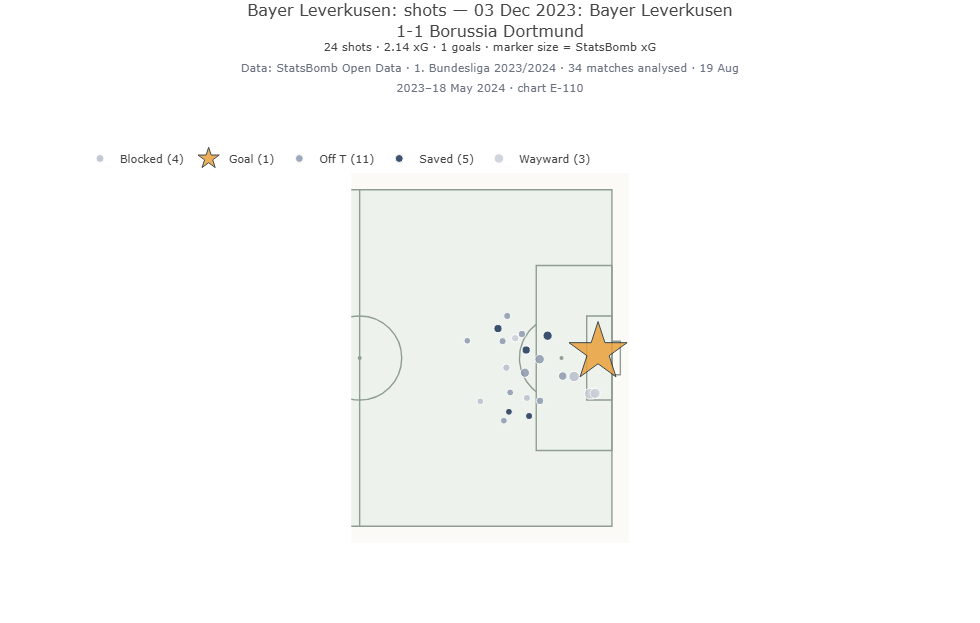

`E-110` Team shot map · *Method:* Marker size = StatsBomb xG; star = goal.

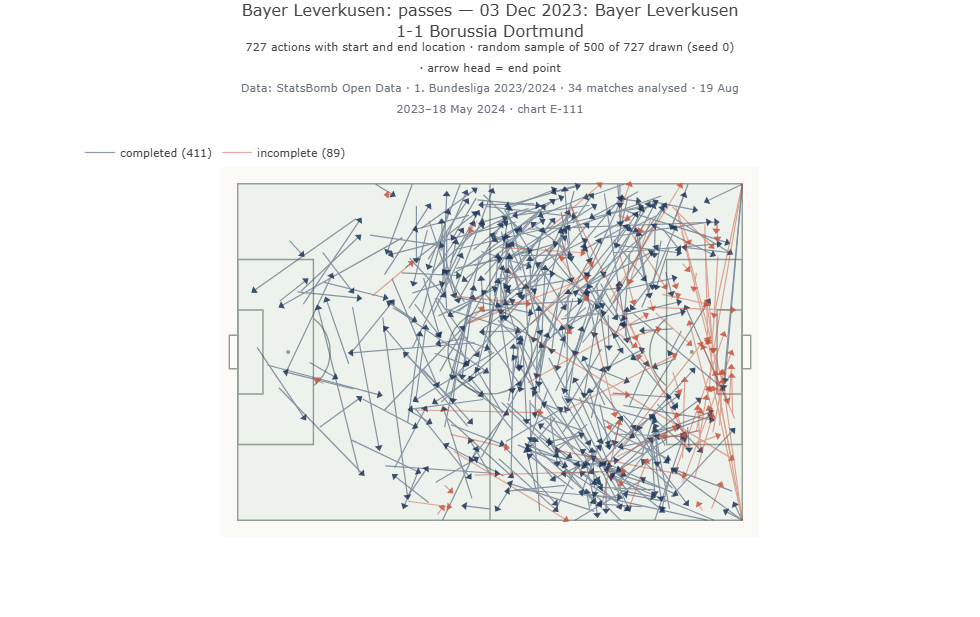

`E-111` Pass map with arrows · *Method:* Arrow heads at the end point; failed passes in red. · *Caveat:* Random sample of 500 arrows when larger.

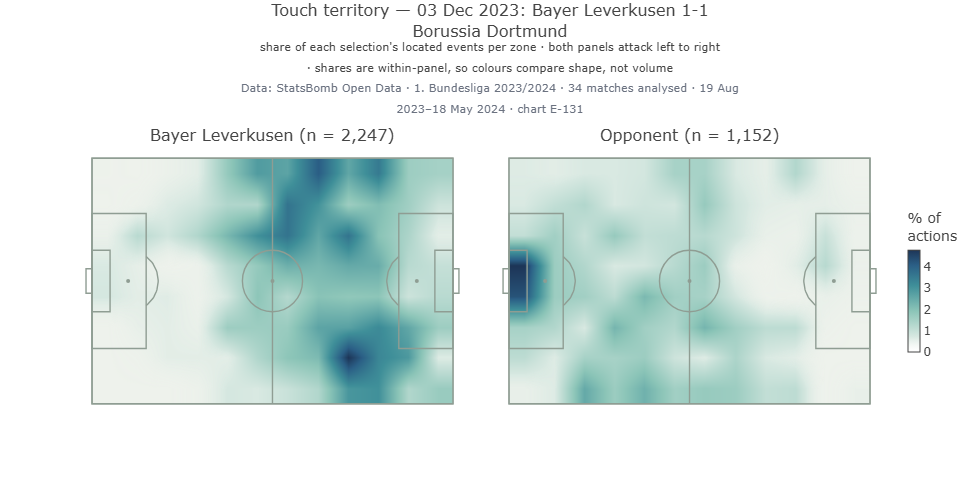

`E-131` Spatial comparison team versus opponent · *Method:* Zone shares side by side. · *Caveat:* Shares are within-panel.

In [23]:
mid = ws.default_match()
print(ws.match_label(mid))
show("E-110", ws, match_id=mid)
show("E-111", ws, match_id=mid)
show("E-131", ws, match_id=mid)

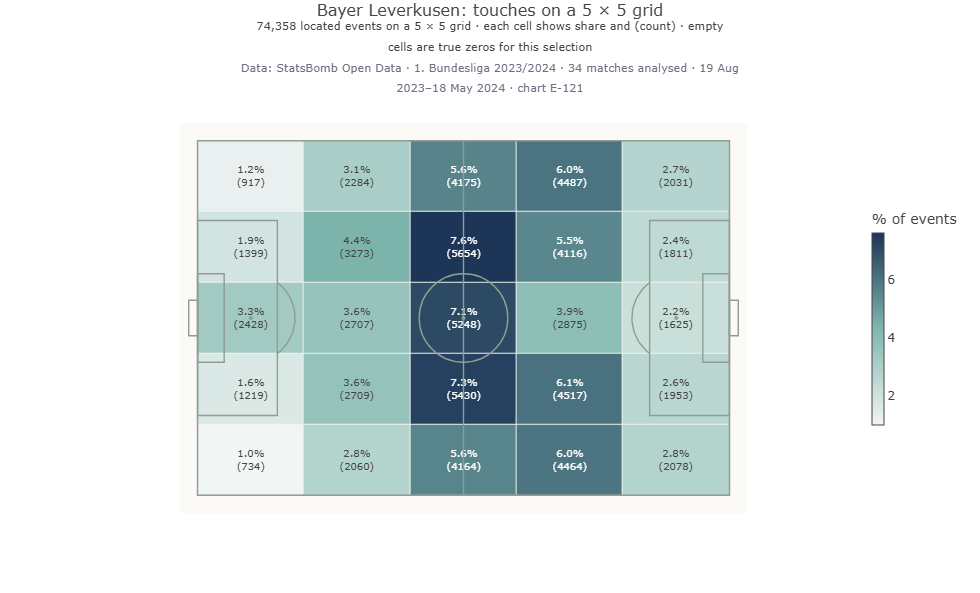

`E-121` Zone heatmaps (3×3, 5×5, tactical) · *Method:* Counts and shares per cell.

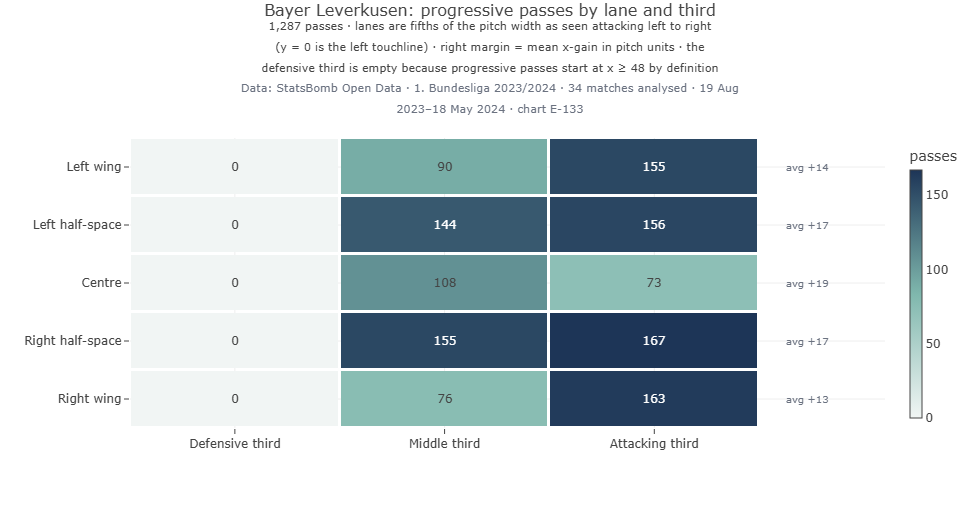

`E-133` Pass progression lanes · *Method:* Five lanes × three thirds by pass origin.

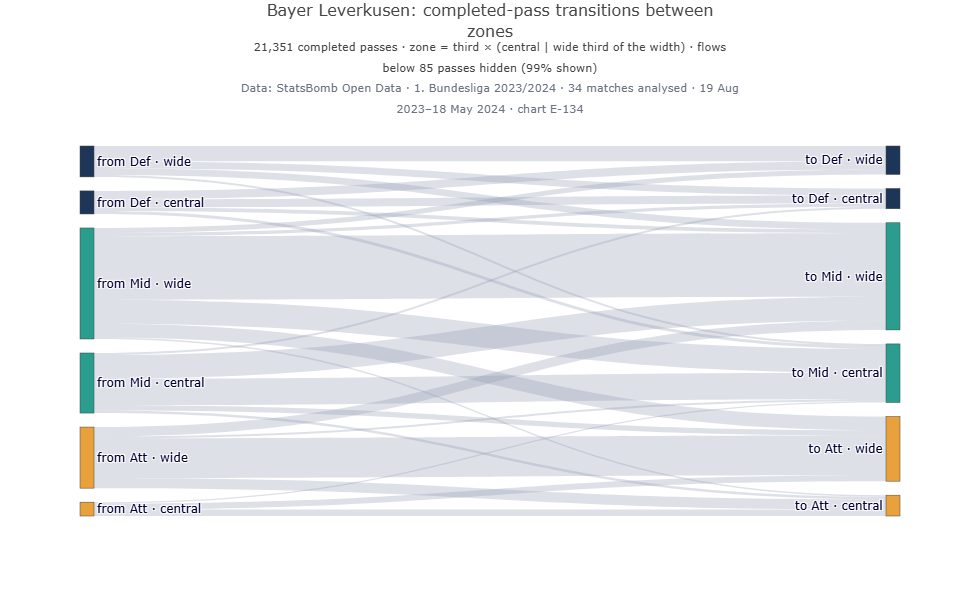

`E-134` Event transition Sankey · *Method:* Zone = third × (central | wide). · *Caveat:* Small flows hidden; share shown stated.

**Interpretation.** 30% of the team's 74,358 touches are in the attacking third and 19% in its own third. Of 1,287 progressive passes, 25% start in the right half-space and 14% in the centre.

**Managerial implication.** The lanes used for progression show where an opponent's block is most often played through — and where the team's own access would suffer if that side were closed.

**Limitation.** Event locations are where the ball was; off-ball positioning is not in event data.

In [24]:
from src.analytics import descriptive as desc
touches = select_events(fl, "Touches", team_id=tid)
zt = desc.zone_table(touches, 3, 1)
show("E-121", ws, kind="Touches")
show("E-133", ws)
show("E-134", ws)
share = (zt.iloc[0] / zt.values.sum())
prog = select_events(fl, "Progressive passes", team_id=tid)
lane = pd.Series(np.clip((prog.y / 80 * 5).astype(int), 0, 4)).map(dict(enumerate(spatial.LANES))).value_counts(normalize=True)
interpret(f"{share.iloc[2]:.0%} of the team's {len(touches):,} touches are in the attacking third and {share.iloc[0]:.0%} in "
          f"its own third. Of {len(prog):,} progressive passes, {lane.iloc[0]:.0%} start in the {lane.index[0].lower()} "
          f"and {lane.iloc[-1]:.0%} in the {lane.index[-1].lower()}.")
implication("The lanes used for progression show where an opponent's block is most often played through — and "
            "where the team's own access would suffer if that side were closed.")
limitation("Event locations are where the ball was; off-ball positioning is not in event data.")

### Expected Threat (project-computed)

**Question.** Which areas carry the most threat in these matches, and who moves the ball into them?

**Method.** A 16 × 12 grid; moves are passes and carries; a failed pass passes on no value; the value of a shot
from a cell is the mean StatsBomb xG of shots taken there; the surface is the fixed point of
`xT(c) = P(shot|c)·value(c) + P(move|c)·Σ T(c→c')·xT(c')`. It is **fitted on the analysed matches themselves**
and is a derived project value, not a StatsBomb field.

,check,passed,detail
0,Value iteration converged,True,79 iterations
1,"All values within [0, 1]",True,"min 0.0029, max 0.2927"
2,Final third more valuable than own third,True,0.0490 vs 0.0075
3,Highest-value cell lies in the attacking penal...,True,"cell row 6, col 15 of 12 x 16"


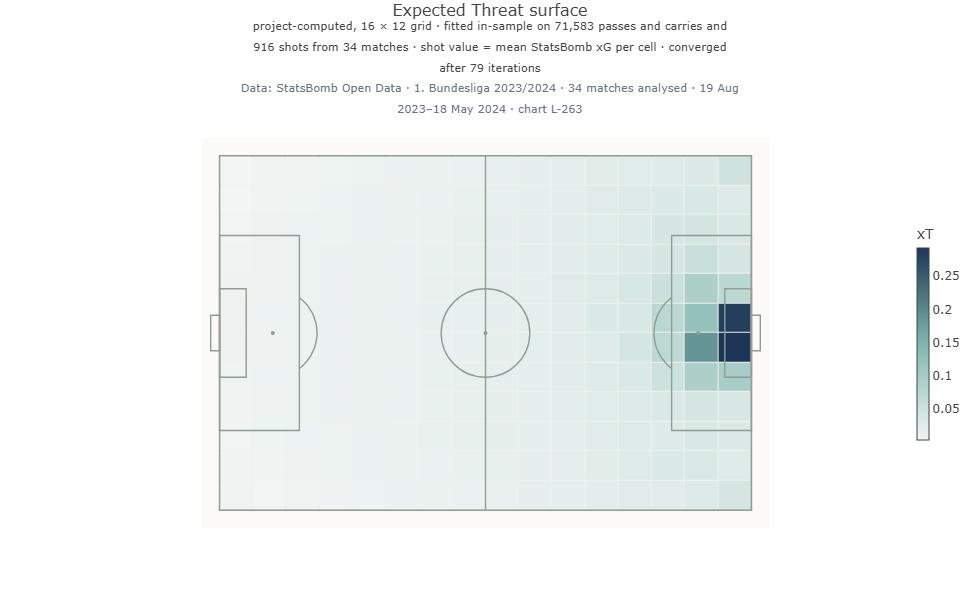

`L-263` Expected Threat surface · *Method:* Project-computed xT, 16 × 12 grid, value iteration. · *Caveat:* Fitted in-sample on the analysed matches; not a StatsBomb field.

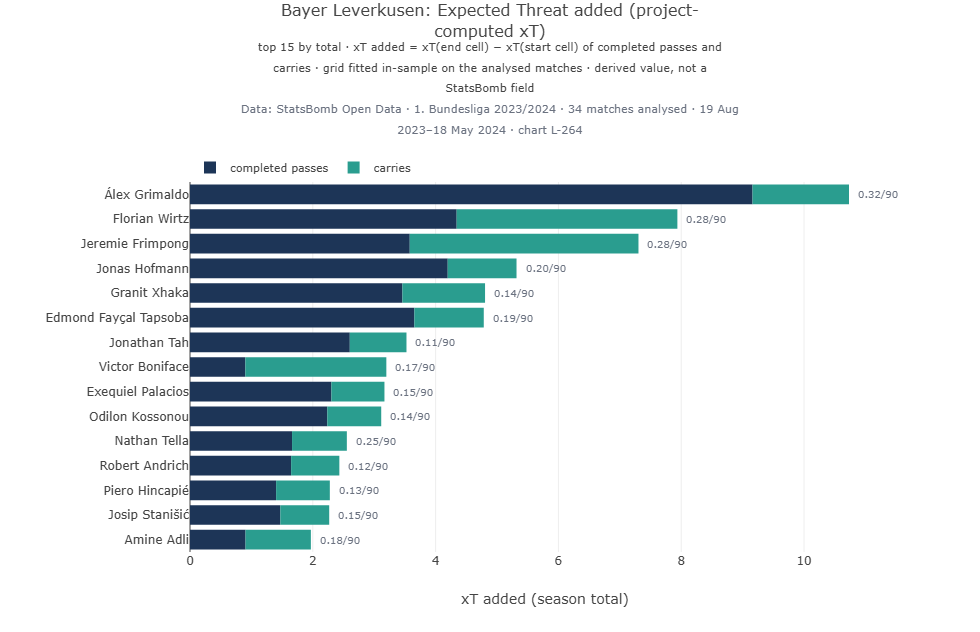

`L-264` xT added by player · *Method:* xT(end) − xT(start) of completed passes and carries. · *Caveat:* Derived project value on an in-sample grid.

**Interpretation.** The grid was fitted on 71,583 passes and carries and 916 shots and converged in 79 iterations; the highest cell is worth 0.293. Álex Grimaldo added the most threat (10.7; 9.2 by passing, 1.6 by carrying).

**Limitation.** In-sample and descriptive: with 34 matches the surface is noisy cell by cell, and it credits only the player who moved the ball.

In [25]:
from src.features import values
g = ws.xt_grid()
display(values.xt_sanity(g))
show("L-263", ws)
show("L-264", ws)
px = ws.player_xt(); mine = px[px.team_name == FOCUS].head(3)
interpret(f"The grid was fitted on {g.n_moves:,} passes and carries and {g.n_shots:,} shots and converged in {g.iterations} "
          f"iterations; the highest cell is worth {g.grid.max():.3f}. {mine.player_name.iloc[0]} added the most threat "
          f"({mine.xt_total.iloc[0]:.1f}; {mine.xt_pass.iloc[0]:.1f} by passing, {mine.xt_carry.iloc[0]:.1f} by carrying).")
limitation("In-sample and descriptive: with 34 matches the surface is noisy cell by cell, and it credits only the "
           "player who moved the ball.")

## F · Passing networks

**Question.** Who connects the team, and how dependent is the structure on individual players?

**Method.** One directed graph per match from completed passes before the first substitution, so every node
shared the pitch. Node position = mean pass origin; PageRank is weighted by pass count; betweenness uses
1 / passes as distance.

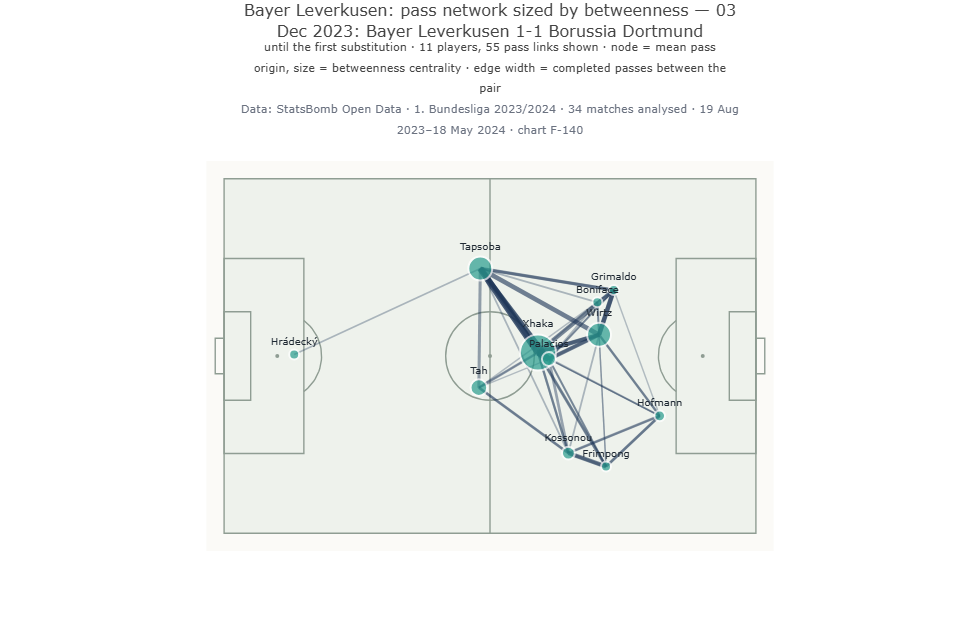

`F-140` Network with centrality-sized nodes · *Method:* Node size and edge width defined in the subtitle.

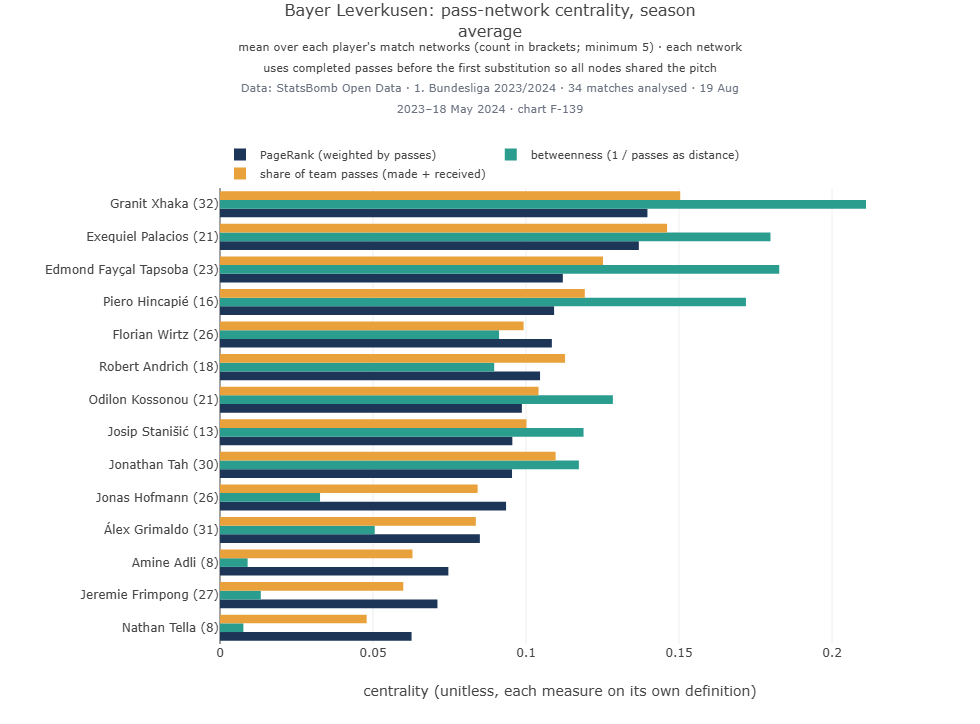

`F-139` Network node centrality · *Method:* PageRank, betweenness and pass share averaged over match networks.

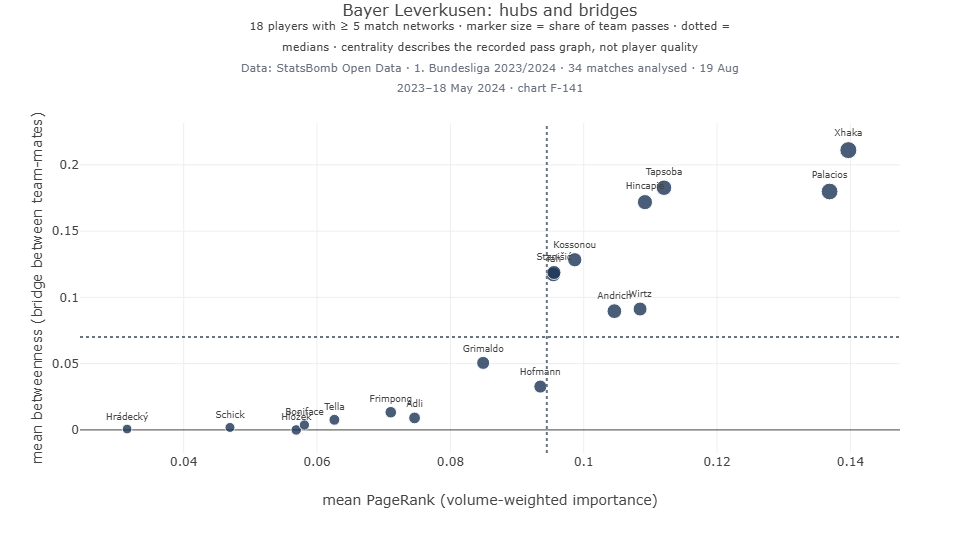

`F-141` Network centrality comparison · *Method:* PageRank vs betweenness, size = pass share.

**Interpretation.** Across 34 match networks Granit Xhaka has both the highest mean PageRank (0.140) and the highest mean betweenness (0.211). The four highest-PageRank players are Granit Xhaka, Exequiel Palacios, Edmond Fayçal Tapsoba, Piero Hincapié.

**Managerial implication.** A structure that runs through one or two players is efficient and exposed: plan the build-up for matches in which the hub is pressed or absent.

**Limitation.** Centrality describes the recorded pass graph; it is not a measure of player quality.

In [26]:
show("F-140", ws, match_id=mid)
show("F-139", ws)
show("F-141", ws)
cs = ws.centrality_summary()
hub, bridge = cs.iloc[-1], cs.sort_values("betweenness").iloc[-1]
who = (f"{hub.player} has both the highest mean PageRank ({hub.pagerank:.3f}) and the highest mean betweenness "
       f"({bridge.betweenness:.3f})" if hub.player == bridge.player else
       f"{hub.player} has the highest mean PageRank ({hub.pagerank:.3f}) and {bridge.player} the highest mean "
       f"betweenness ({bridge.betweenness:.3f})")
interpret(f"Across {ws.centrality().match_id.nunique()} match networks {who}. "
          f"The four highest-PageRank players are {', '.join(cs.player.tail(4)[::-1])}.")
implication("A structure that runs through one or two players is efficient and exposed: plan the build-up for "
            "matches in which the hub is pressed or absent.")
limitation("Centrality describes the recorded pass graph; it is not a measure of player quality.")

### Formations and what cannot be drawn

A formation here is the label recorded on the Starting XI or Tactical Shift event — a nominal description, not
the team's shape in and out of possession.

,starting_formation,matches,wins,draws,losses,points_per_match,xg_for,xg_against,goals_for,goals_against,possession_proxy_pct,field_tilt_pct,sample_warning
0,3-4-2-1,25,23,2,0,2.840,2.050,0.740,2.680,0.640,62.780,68.290,
1,3-4-3,8,4,4,0,2.000,2.440,1.100,2.500,0.880,58.400,66.920,
2,3-4-1-2,1,1,0,0,3.000,1.820,0.460,2.000,1.000,61.070,56.020,n<3: descriptive only


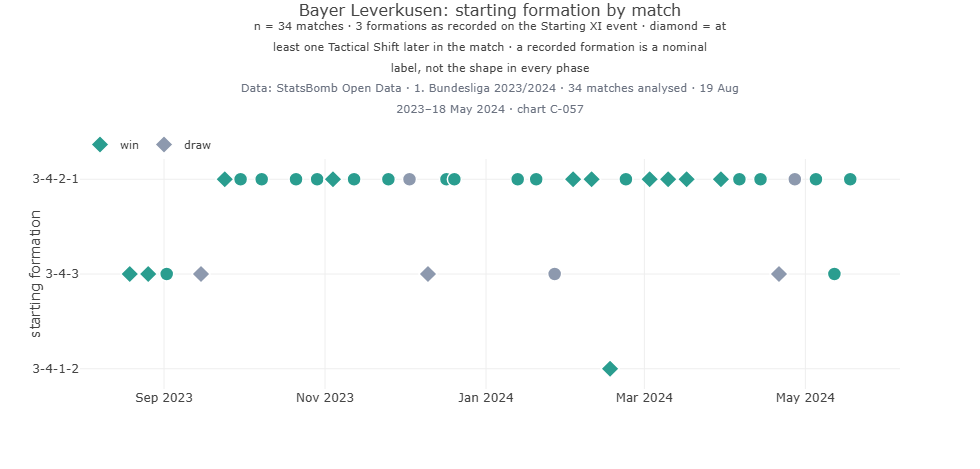

`C-057` Formation usage timeline · *Method:* Recorded Starting XI formation by date. · *Caveat:* A nominal label, not the shape in every phase.

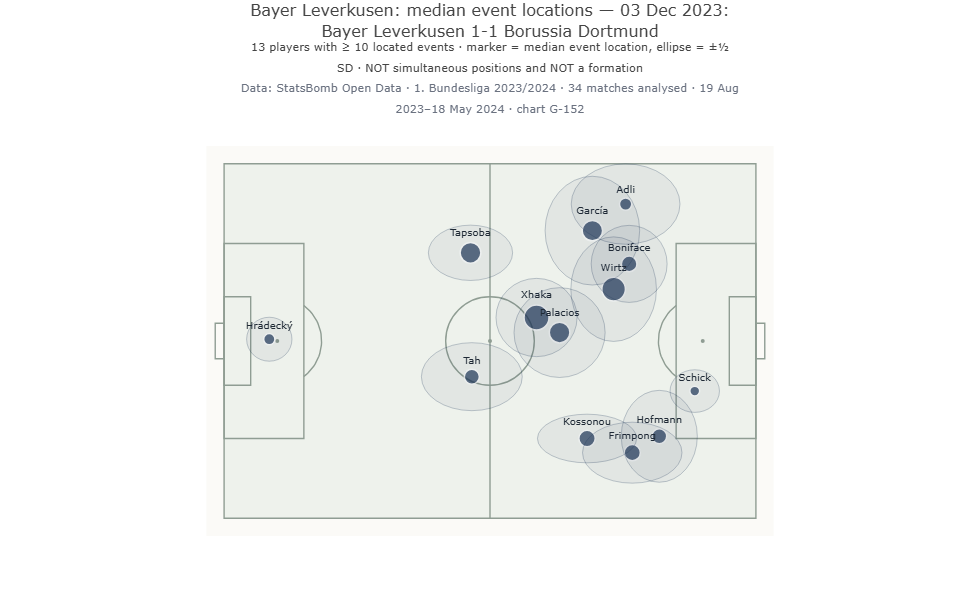

`G-152` Team shape from event locations · *Method:* Median touch location per player. · *Caveat:* Not simultaneous positions and not a formation.

**Interpretation.** Bayer Leverkusen started in 3 formations; 3-4-2-1 in 25 of 34 matches. Differences in results between formations are confounded by opponent and availability.

E-126 Voronoi diagram: not implemented — Needs every player's position at the same instant. Event data give one actor per event, and 360 freeze frames show only players inside the camera view, so a Voronoi partition would be invented space.
E-127 Delaunay triangulation: not implemented — Needs simultaneous positions of all team-mates (tracking data); not derivable from event locations.
E-128 Pitch-control / space-control map: not implemented — Needs positions and velocities of all 22 players (tracking). Never approximated from event x/y.


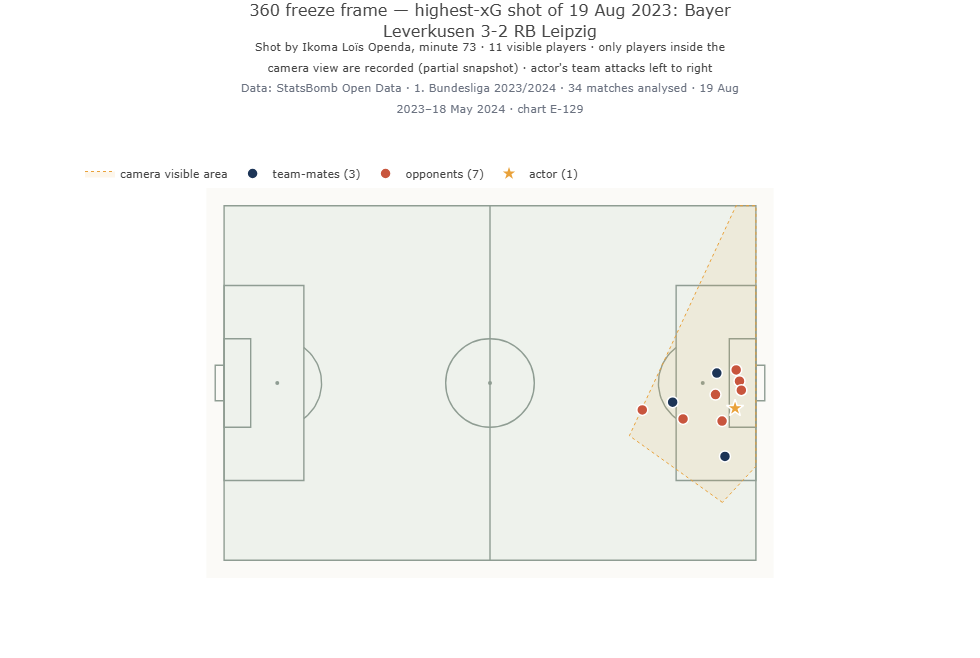

`E-129` 360 freeze-frame plot · *Method:* StatsBomb 360 frame of the match's highest-xG shot. · *Caveat:* Only players in the camera view are recorded.

In [27]:
from src.features.team_features import formation_summary
from src.visualization import registry
fs = formation_summary(B.team_stats, FOCUS)
display(fs)
show("C-057", ws)
show("G-152", ws, match_id=mid)
interpret(f"{FOCUS} started in {len(fs)} formations; {fs.starting_formation.iloc[0]} in {int(fs.matches.iloc[0])} of {len(tm)} "
          f"matches. Differences in results between formations are confounded by opponent and availability.")
for cid in ("E-126", "E-127", "E-128"):
    s = registry.get(cid)
    print(f"{cid} {s.name}: not implemented — {s.unavailable_reason}")
show("E-129", ws, match_id=int(tm.match_id.iloc[0]))

---
# Part 04 · Starting XI and substitution decision support

## F · Starting XI decision support

**Research question.** Which eleven does the evidence available *before* a match shortlist for a formation, why
is each player in it, and how sensitive is that to the weights?

**Data and method.** Candidates are players seen in recent match-day squads before the decision point. Each
candidate–slot score is

`(0.40·role fit + 0.20·recent form + 0.15·evidence volume + 0.15·minutes-based exposure + 0.10·continuity) × position compatibility`

with components on 0–100. Players are assigned to slots with the Hungarian algorithm under hard constraints
(eleven distinct players, one goalkeeper, eligibility, squad membership). **It is a transparent heuristic:
"best" means best under these weights and constraints.**

Decision point: before 03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund · formation 3-4-2-1
Pool: matchday squad of match 3895158 (2023-12-03)


,role_fit,recent_form,sample_reliability,workload_suitability,lineup_continuity
0,0.400,0.200,0.150,0.150,0.100


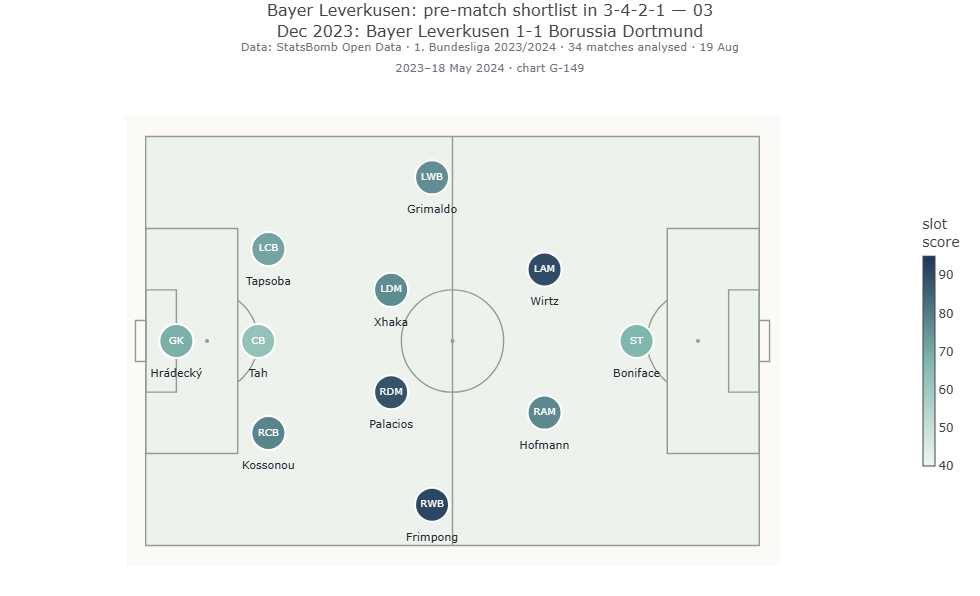

`G-149` Starting XI pitch diagram · *Method:* Hungarian assignment of candidates to formation slots. · *Caveat:* Best under the stated scoring model and constraints — a shortlist, not the optimal XI.

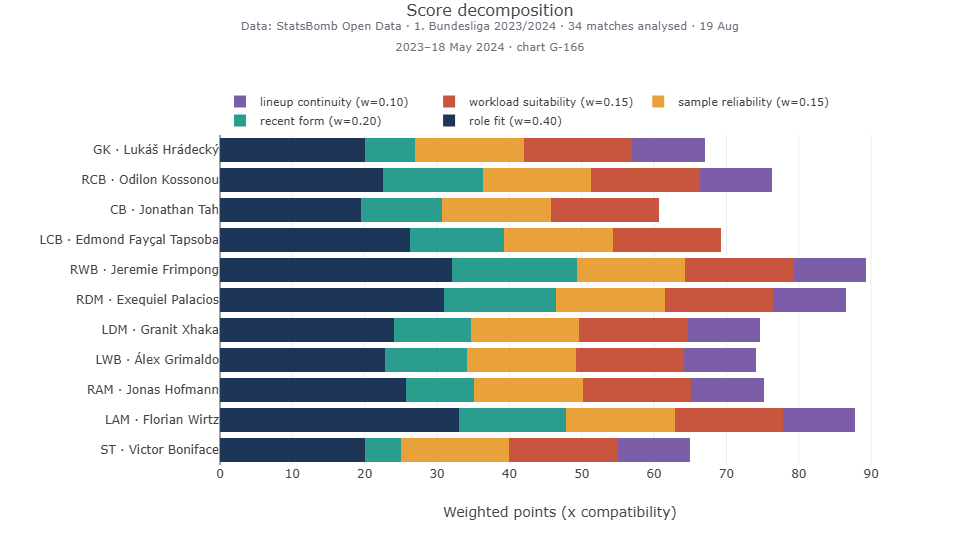

`G-166` Starting XI score component breakdown · *Method:* Weighted components per pick.

,slot,player_name,primary_role,compatibility,role_fit,recent_form,sample_reliability,workload_suitability,lineup_continuity,score,coverage_label
0,GK,Lukáš Hrádecký,GK,1.000,50.000,35.000,100.000,100.000,100.000,69.000,high data coverage
1,RCB,Odilon Kossonou,CB,1.000,56.400,68.600,100.000,100.000,100.000,78.300,high data coverage
2,CB,Jonathan Tah,CB,1.000,48.600,56.400,100.000,100.000,0.000,62.700,high data coverage
3,LCB,Edmond Fayçal Tapsoba,CB,1.000,65.700,65.000,100.000,100.000,0.000,71.300,high data coverage
4,RWB,Jeremie Frimpong,WB,1.000,80.000,86.400,100.000,100.000,100.000,91.300,high data coverage
5,RDM,Exequiel Palacios,DM,1.000,77.500,77.500,100.000,100.000,100.000,88.500,high data coverage
6,LDM,Granit Xhaka,DM,1.000,60.000,53.300,100.000,100.000,100.000,76.700,high data coverage
7,LWB,Álex Grimaldo,WB,1.000,57.100,56.400,100.000,100.000,100.000,76.100,high data coverage
8,RAM,Jonas Hofmann,AM,1.000,64.200,47.500,100.000,100.000,100.000,77.200,high data coverage
9,LAM,Florian Wirtz,AM,1.000,82.500,74.200,100.000,100.000,100.000,89.800,high data coverage


Optimiser warnings: ['Thin depth at GK: 1 natural candidate(s).']


In [28]:
from src.analytics import lineup_optimizer as xi
mid = ws.default_match()
p = ws.params()
ctx = ws.xi_context(FOCUS, mid)
res = ws.xi_result(FOCUS, mid, p.formation)
print(f"Decision point: before {ws.match_label(mid)} · formation {p.formation}")
print("Pool:", ctx.pool_description)
display(pd.DataFrame([B.config.xi_score_weights]))
show("G-149", ws, match_id=mid)
show("G-166", ws, match_id=mid)
display(res.lineup[["slot", "player_name", "primary_role", "compatibility", "role_fit", "recent_form", "sample_reliability",
                    "workload_suitability", "lineup_continuity", "score", "coverage_label"]].round(1))
print("Optimiser warnings:", res.warnings or "none")

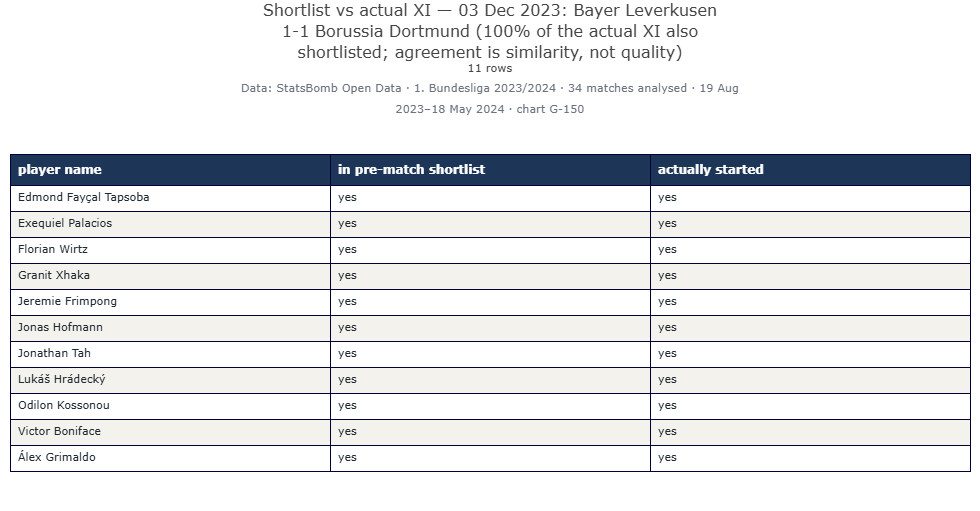

`G-150` Actual XI versus shortlisted XI · *Method:* Overlap table with the share of the actual XI also shortlisted. · *Caveat:* Agreement measures similarity, not which choice was better.

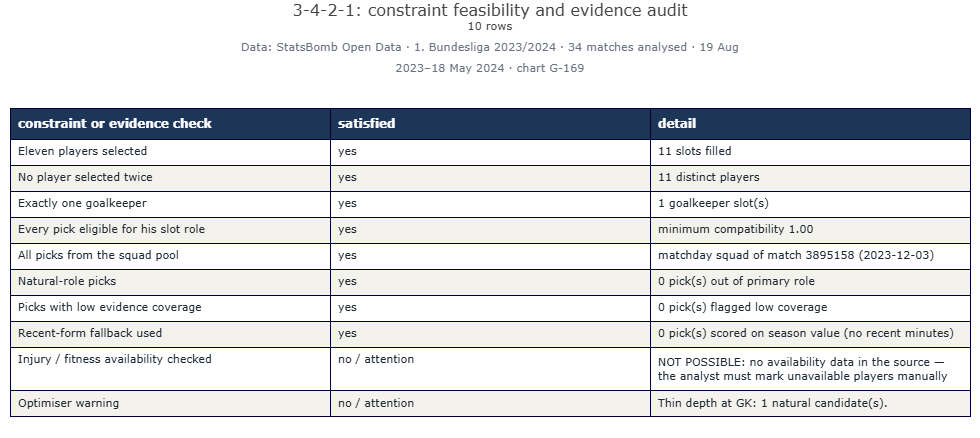

`G-169` Constraint feasibility audit · *Method:* Checklist of constraints and evidence gaps.

**Interpretation.** 100% of the players who actually started are in the shortlist. Shortlisted but not selected: none; selected but not shortlisted: none.

**Limitation.** Agreement measures similarity to the manager's choice, not whether either was better. The source has no injury, fitness or training information, so a player the manager could not pick may still be shortlisted.

In [29]:
cmp_, share = xi.compare_with_actual(res, T["appearances"], mid, ws.team_id())
show("G-150", ws, match_id=mid)
show("G-169", ws, match_id=mid)
only_model = cmp_[cmp_.in_recommended & ~cmp_.in_actual].player_name.tolist()
only_actual = cmp_[~cmp_.in_recommended & cmp_.in_actual].player_name.tolist()
interpret(f"{share:.0%} of the players who actually started are in the shortlist. Shortlisted but not selected: "
          f"{', '.join(only_model) or 'none'}; selected but not shortlisted: {', '.join(only_actual) or 'none'}.")
limitation("Agreement measures similarity to the manager's choice, not whether either was better. The source has "
           "no injury, fitness or training information, so a player the manager could not pick may still be shortlisted.")

,weighting,players kept from configured XI,total score,new players
0,configured,11,847.900,—
1,role fit only,9,730.600,"Josip Stanišić, Amine Adli"
2,form-led,10,793.300,Piero Hincapié
3,continuity-led,9,936.200,"Robert Andrich, Piero Hincapié"
4,rotation-led,11,954.100,—


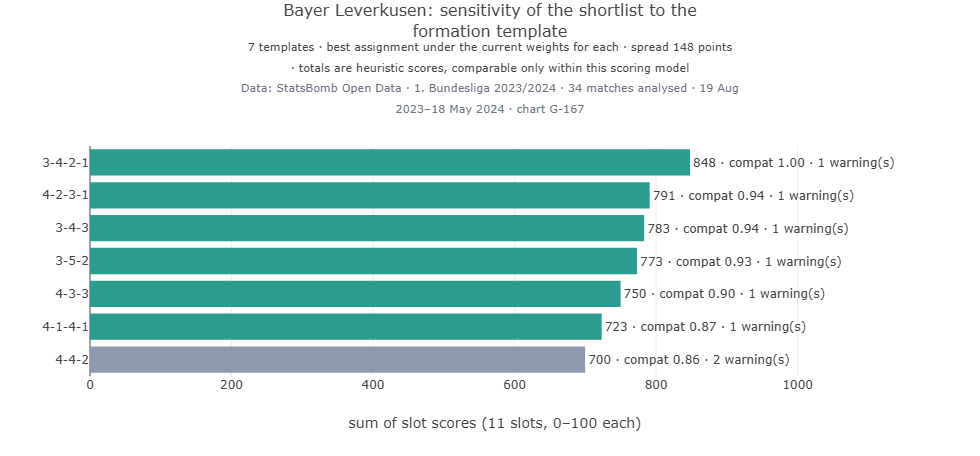

`G-167` Formation sensitivity chart · *Method:* Best total score under each template. · *Caveat:* Heuristic totals, comparable only within this model.

**Interpretation.** Across five weightings between 9 and 11 players stay the same. The slots that change are the ones where the evidence does not separate the candidates.

**Managerial implication.** The tool is most useful as a way to see which slots are genuinely open and what each weighting assumes — not as a single answer.

In [30]:
# Sensitivity: does the shortlist change when the weights change?
import dataclasses
base_ids = set(res.lineup.player_id)
rows = []
for name, w in {"configured": B.config.xi_score_weights,
                "role fit only": {"role_fit": 1, "recent_form": 0, "sample_reliability": 0, "workload_suitability": 0, "lineup_continuity": 0},
                "form-led": {"role_fit": .2, "recent_form": .5, "sample_reliability": .1, "workload_suitability": .1, "lineup_continuity": .1},
                "continuity-led": {"role_fit": .2, "recent_form": .1, "sample_reliability": .1, "workload_suitability": .1, "lineup_continuity": .5},
                "rotation-led": {"role_fit": .3, "recent_form": .1, "sample_reliability": .1, "workload_suitability": .5, "lineup_continuity": 0}}.items():
    r2 = xi.optimize_xi(ctx, p.formation, dataclasses.replace(B.config, xi_score_weights=w))
    ids = set(r2.lineup.player_id)
    rows.append({"weighting": name, "players kept from configured XI": len(ids & base_ids), "total score": round(r2.total_score, 1),
                 "new players": ", ".join(r2.lineup[~r2.lineup.player_id.isin(base_ids)].player_name) or "—"})
sens = pd.DataFrame(rows)
display(sens)
show("G-167", ws, match_id=mid)
interpret(f"Across five weightings between {sens['players kept from configured XI'].min()} and 11 players stay the same. "
          f"The slots that change are the ones where the evidence does not separate the candidates.")
implication("The tool is most useful as a way to see which slots are genuinely open and what each weighting "
            "assumes — not as a single answer.")

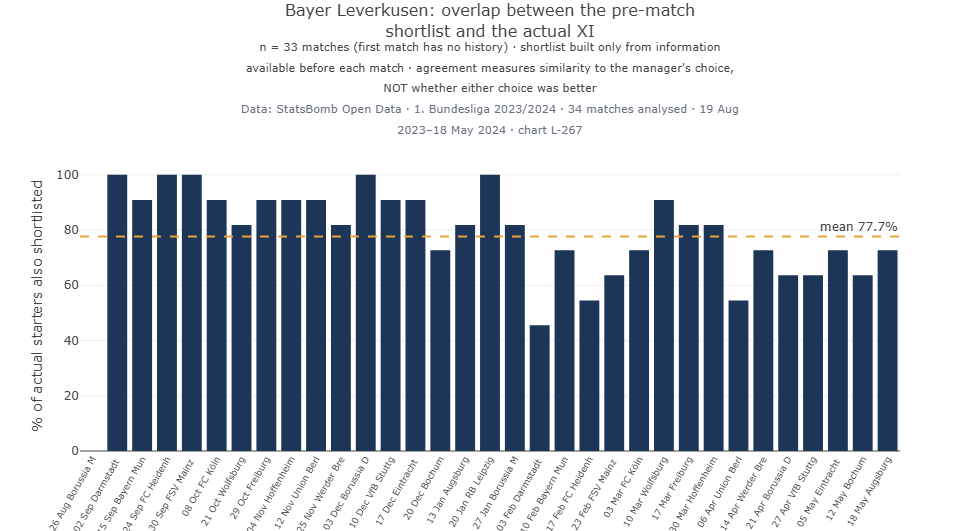

`L-267` Shortlist versus actual XI over the season · *Method:* Share of the actual XI also shortlisted, per match. · *Caveat:* Agreement is similarity, not quality.

**Interpretation.** Over 33 matches the shortlist shares 77.7% of the actual XI on average (minimum 0%, maximum 100%).

**Limitation.** High agreement reflects a stable core that any sensible rule would pick; it is not evidence of decision quality.

In [31]:
# Backtest: rebuild the shortlist before every match from earlier matches only, compare with the actual XI
with timed("XI backtest"):
    ag = ws.xi_agreement()
show("L-267", ws)
interpret(f"Over {len(ag)} matches the shortlist shares {ag.agreement_pct.mean():.1f}% of the actual XI on average "
          f"(minimum {ag.agreement_pct.min():.0f}%, maximum {ag.agreement_pct.max():.0f}%).")
limitation("High agreement reflects a stable core that any sensible rule would pick; it is not evidence of "
           "decision quality.")

## Substitution intelligence

**Research question.** When and in which situations are changes made, who replaces whom, and which bench
options does the evidence shortlist at a given moment?

**Method.** Each substitution is enriched with the score state from the reconstructed goal timeline, the
manpower state from sending-offs, a timing band, the roles of both players and the substitution window under a
configured five-substitutes / three-windows rule. Historical patterns are **descriptive**; scenario shortlists
are **counterfactual simulations**.

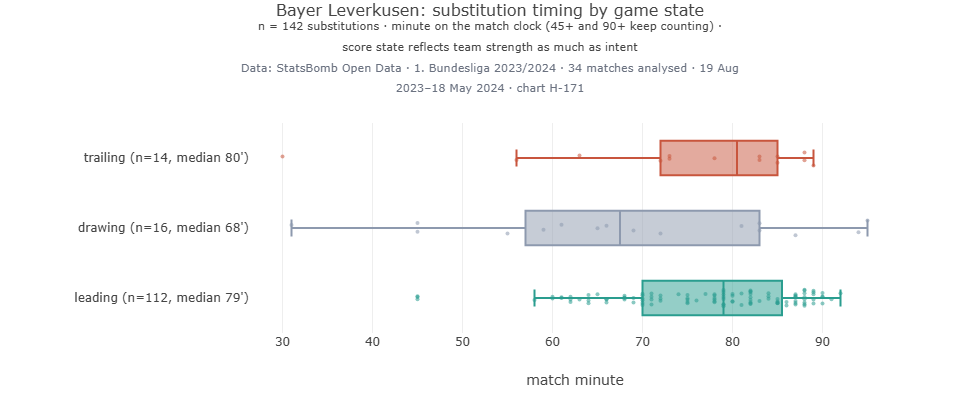

`H-171` Substitution timing by score state · *Method:* Minute distribution per score state. · *Caveat:* Score state reflects team strength as much as intent.

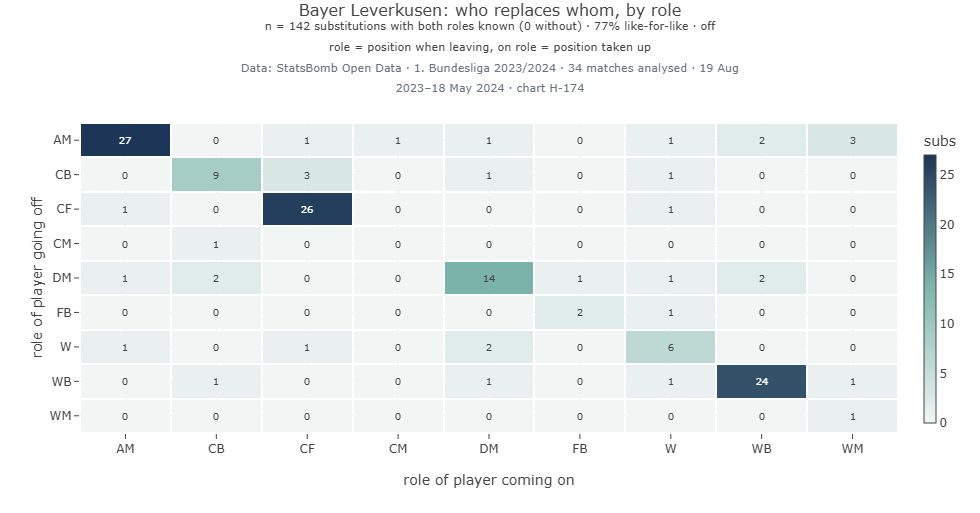

`H-174` Substitution role-matching matrix · *Method:* Off role × on role counts.

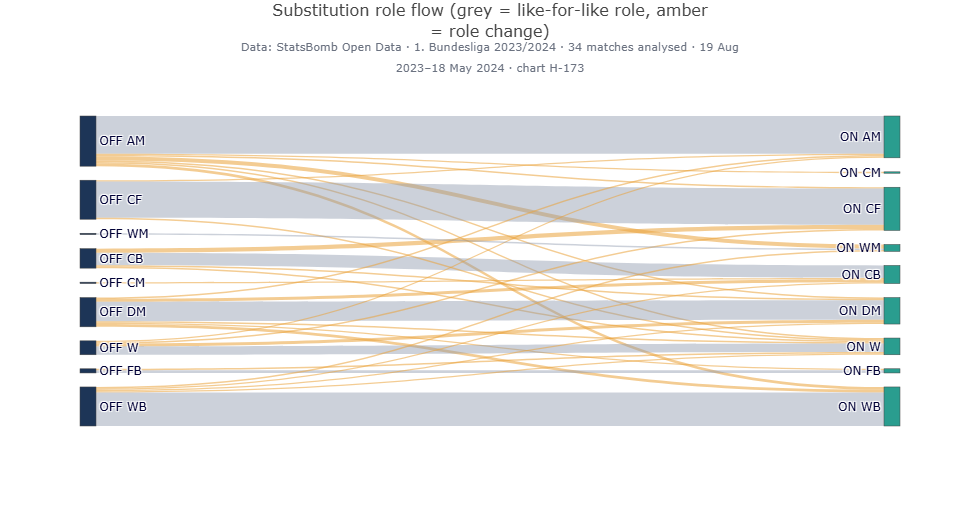

`H-173` Incoming / outgoing role Sankey · *Method:* Role going off → role coming on.

**Interpretation.** Bayer Leverkusen made 142 substitutions (4.18 per match) at a median minute of 79; 79% came while leading and 77% were like-for-like by role. Opponents: median minute 72, 70% while trailing.

**Limitation.** Score state is driven by team strength: a team that usually leads makes most changes while leading whatever its intent. A substitution alone says nothing about injury or fatigue.

In [32]:
S = B.subs; mine = S[S.team_name == FOCUS]; others = S[S.team_name != FOCUS]
show("H-171", ws)
show("H-174", ws)
show("H-173", ws)
interpret(f"{FOCUS} made {len(mine)} substitutions ({len(mine) / len(tm):.2f} per match) at a median minute of {mine.minute.median():.0f}; "
          f"{(mine.game_state == 'leading').mean():.0%} came while leading and {mine.like_for_like.astype(bool).mean():.0%} were "
          f"like-for-like by role. Opponents: median minute {others.minute.median():.0f}, {(others.game_state == 'trailing').mean():.0%} while trailing.")
limitation("Score state is driven by team strength: a team that usually leads makes most changes while leading "
           "whatever its intent. A substitution alone says nothing about injury or fatigue.")

03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund at 65': 0-1 (trailing), 0 substitutions used, 5 remaining · intent 'attack' (Trailing: consider attacking / progression-focused options.)
Rule source: User-configured default (IFAB Law 3 five-substitute option). Verify against the competition's regulations.


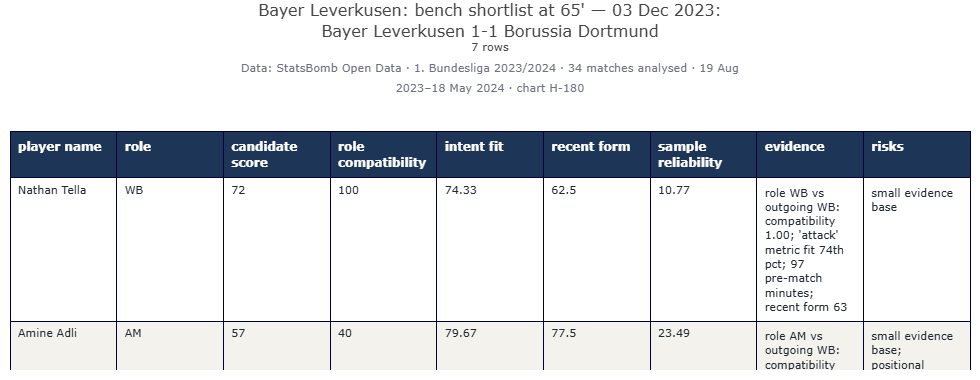

`H-180` Candidate substitute comparison · *Method:* Ranked bench candidates with evidence and risks. · *Caveat:* Candidates are restricted to the match-day bench not yet used at that minute.

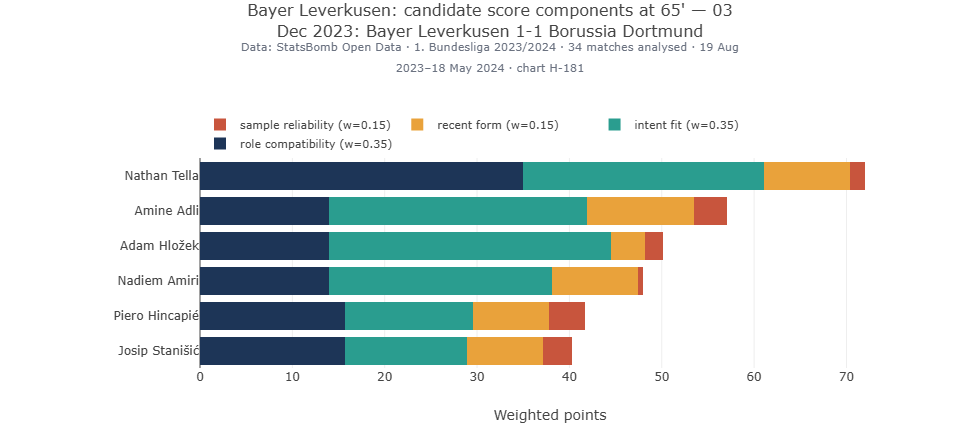

`H-181` Substitution candidate score decomposition · *Method:* Role compatibility, intent fit, recent form, sample reliability.

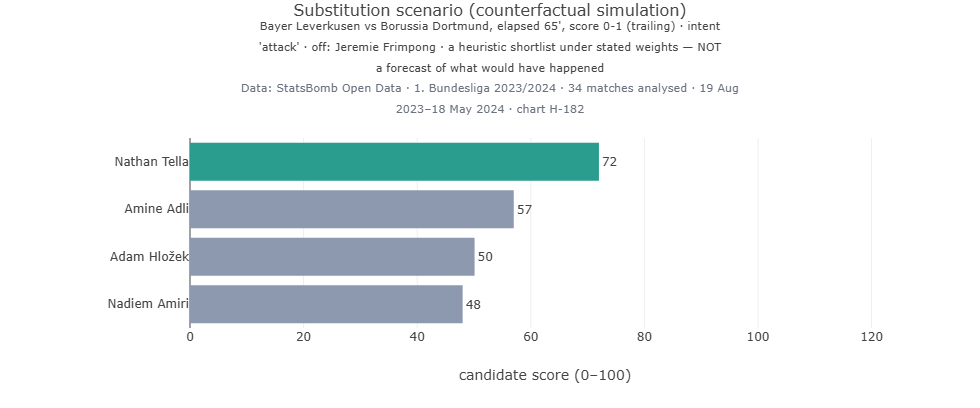

`H-182` Alternative substitution scenario · *Method:* Counterfactual simulation at the selected minute. · *Caveat:* A heuristic shortlist — never a claim about what would have happened.

**Interpretation.** The heuristic would take off Jeremie Frimpong (65 min played this match; role-action rate at 86% of own pre-match baseline (8 role metrics); booked (second-yellow risk)) and shortlist Nathan Tella (score 72; role WB vs outgoing WB: compatibility 1.00; 'attack' metric fit 74th pct; 97 pre-match minutes; recent form 63). Availability: unknown (no injury data in source — not assumed fit).

**Limitation.** A counterfactual shortlist under stated weights. It is not a forecast and cannot say a different change would have altered the result.

In [33]:
from src.analytics import substitution_analysis as sa
minute = 65.0
rec = ws.sub_scenario(FOCUS, mid, minute)
cx = rec["context"]
print(f"{ws.match_label(mid)} at {minute:.0f}': {cx['team_score']}-{cx['opponent_score']} ({cx['game_state']}), "
      f"{cx['subs_used']} substitutions used, {cx['subs_remaining']} remaining · intent '{rec['intent']}' ({rec.get('intent_reason', '')})")
print("Rule source:", cx["rule_source"])
show("H-180", ws, match_id=mid, minute=minute)
show("H-181", ws, match_id=mid, minute=minute)
show("H-182", ws, match_id=mid, minute=minute)
if rec["status"] == "ok":
    on = rec["recommended_on"]
    interpret(f"The heuristic would take off {rec['recommended_off']['player_name']} ({rec['recommended_off']['reasons']}) and shortlist "
              f"{on['player_name']} (score {on['candidate_score']:.0f}; {on['evidence']}). Availability: {on['injury_status']}.")
limitation("A counterfactual shortlist under stated weights. It is not a forecast and cannot say a different "
           "change would have altered the result.")

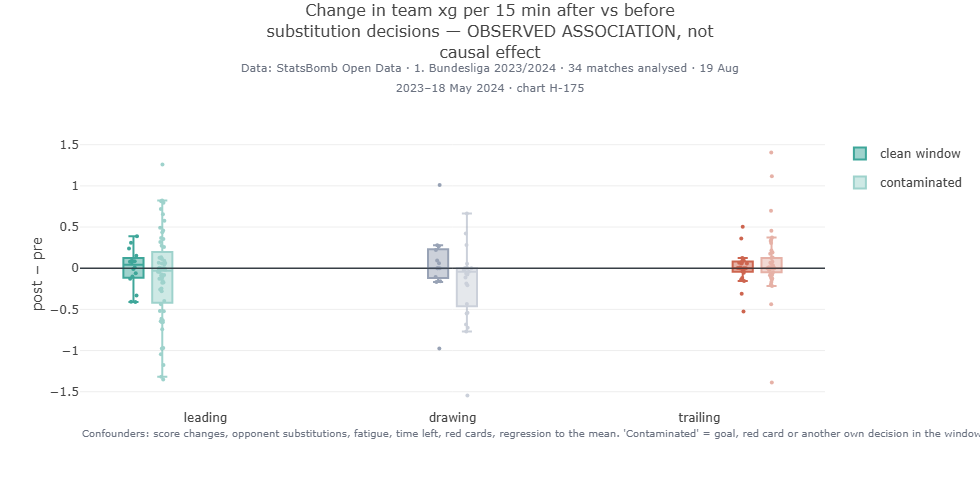

`H-175` Before / after substitution metrics · *Method:* Team xG per 15 minutes in the windows before and after substitution decisions. · *Caveat:* Descriptive only: confounded by score, opponent changes, injuries and regression to the mean.

,game_state,n_decisions,opponent_also_changed_pct,delta_team_shots,delta_team_xg,delta_team_final_third_touches,delta_team_progressive_passes,delta_team_pressures
0,drawing,15,67.000,0.000,-0.067,-3.000,0.000,4.500
1,leading,68,88.000,0.000,-0.007,0.043,0.246,3.000
2,trailing,10,90.000,-0.000,0.191,-10.500,0.000,-0.750


**Interpretation.** Of 93 substitution decisions, 71% have a goal, a red card or another own change inside the before/after window and the opponent also changed in 85%. The median change in team xG per window is -0.010.

**Limitation.** Before/after differences are confounded by score, opponent changes, fatigue and regression to the mean. They are not effects of the substitution.

In [34]:
imp = ws.impact(); imp_t = imp[imp.team_name == FOCUS]
show("H-175", ws)
display(sa.impact_summary(imp_t))
interpret(f"Of {len(imp_t)} substitution decisions, {imp_t.contaminated.mean():.0%} have a goal, a red card or another own "
          f"change inside the before/after window and the opponent also changed in {imp_t.opponent_changed_in_window.mean():.0%}. "
          f"The median change in team xG per window is {imp_t.delta_team_xg.median():+.3f}.")
limitation("Before/after differences are confounded by score, opponent changes, fatigue and regression to the "
           "mean. They are not effects of the substitution.")

,match_id,minute,game_state,actual_off,actual_on,bench_size,rank_actual_on,on_in_top_k,rank_actual_off,off_in_top_k
0,3895052,74,leading,Florian Wirtz,Robert Andrich,9,4.000,False,2,True
1,3895052,88,leading,Jonas Hofmann,Adam Hložek,7,2.000,True,2,True
2,3895052,88,leading,Victor Okoh Boniface,Nadiem Amiri,6,1.000,True,1,True
3,3895060,68,leading,Jeremie Frimpong,Arthur Augusto de Matos Soares,9,1.000,True,3,True
4,3895060,69,leading,Exequiel Alejandro Palacios,Robert Andrich,8,1.000,True,8,False
5,3895060,80,leading,Odilon Kossonou,Josip Stanišić,7,1.000,True,6,False
6,3895060,80,leading,Jonas Hofmann,Adam Hložek,6,3.000,True,5,False
7,3895060,88,leading,Victor Okoh Boniface,Gustavo Adolfo Puerta Molano,5,2.000,True,1,True


**Interpretation.** For 137 non-injury substitutions the player who actually came on was in the heuristic's top three 82.5% of the time; picking three bench players at random would manage about 43%.

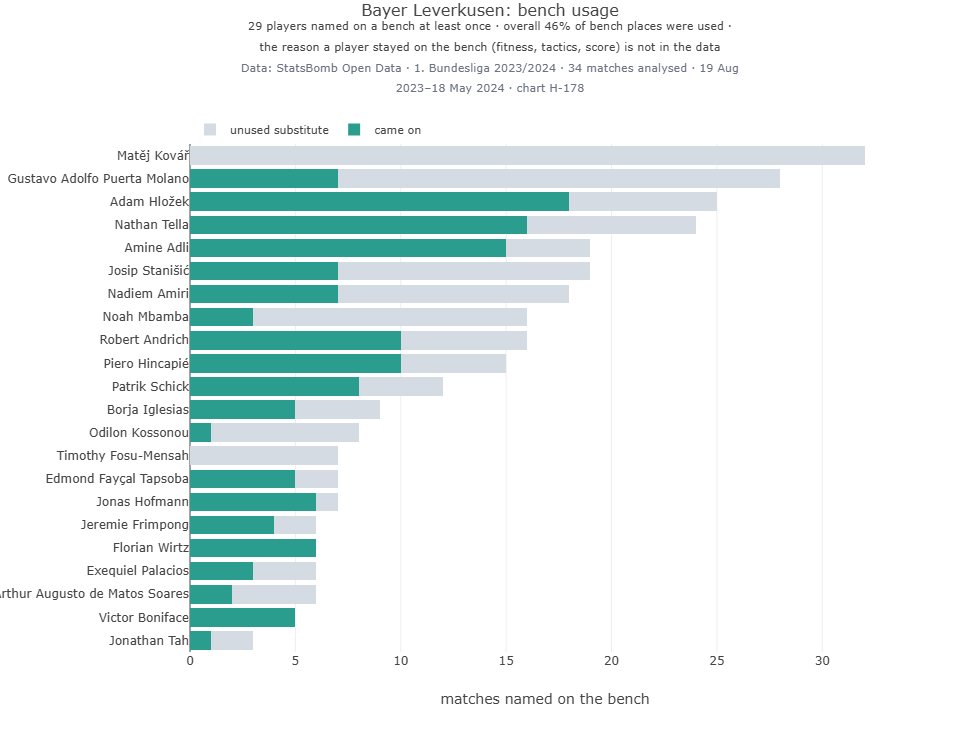

`H-178` Bench usage · *Method:* Times named on the bench, split into used and unused.

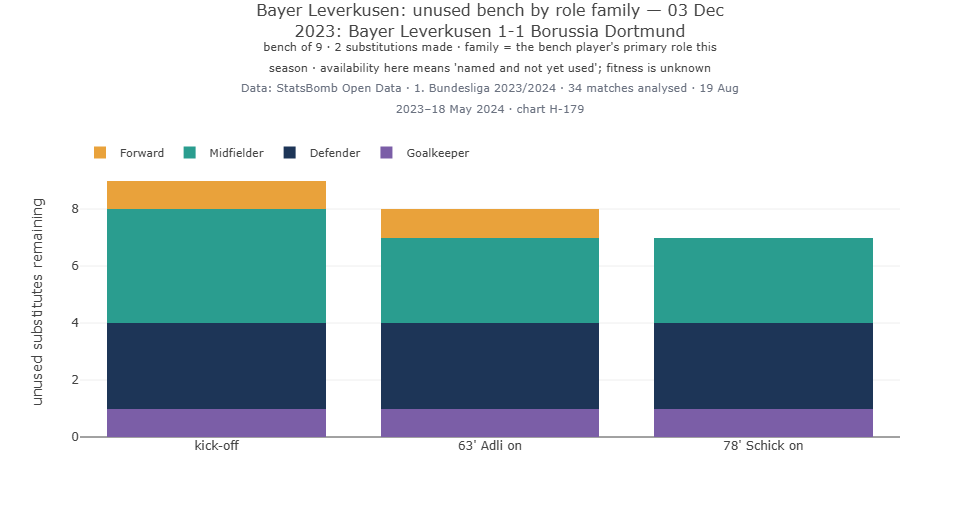

`H-179` Remaining bench availability through a match · *Method:* Unused substitutes after each change. · *Caveat:* Availability = named and not yet used; fitness is unknown.

In [35]:
with timed("substitution backtest"):
    sb = ws.sub_agreement()
rnd = (3 / sb.bench_size.clip(lower=3)).mean()
display(sb.head(8))
interpret(f"For {len(sb)} non-injury substitutions the player who actually came on was in the heuristic's top three "
          f"{sb.on_in_top_k.mean():.1%} of the time; picking three bench players at random would manage about {rnd:.0%}.")
show("H-178", ws)
show("H-179", ws, match_id=mid)

---
# Part 05 · Statistical inference, uncertainty, clustering and models

## G · Statistical inference and uncertainty

**Research question.** Which relationships are in the data, how large are they, and how much could be chance?

**Method.** Rank-based statistics by default (the metrics are skewed), effect sizes and bootstrap intervals
next to every p-value, Benjamini–Hochberg control across a family of tests, and resampling at the level of the
independent unit — matches for team questions, players for player questions. Events are never treated as
independent observations.

,variable,n,pearson_r,pearson_p,spearman_rho,spearman_p,rho_ci_low,rho_ci_high,kendall_tau,kendall_p,spearman_q_BH
0,xg_against,34,-0.445,0.008,-0.428,0.012,-0.722,-0.054,-0.341,0.009,0.093
1,shots_against,34,-0.385,0.024,-0.396,0.020,-0.678,-0.062,-0.311,0.019,0.093
2,xg,34,0.480,0.004,0.374,0.029,-0.032,0.655,0.257,0.048,0.093
3,pass_completion_pct,34,0.333,0.055,0.365,0.034,0.011,0.652,0.269,0.038,0.093
4,ppda,34,0.290,0.096,0.233,0.184,-0.141,0.577,0.173,0.182,0.405
5,possession_proxy_pct,34,0.069,0.697,0.120,0.499,-0.234,0.492,0.094,0.471,0.900
6,set_piece_shots,34,-0.077,0.665,-0.069,0.699,-0.416,0.276,-0.060,0.654,0.900
7,shots,34,0.030,0.867,0.065,0.714,-0.305,0.427,0.053,0.689,0.900
8,progressive_passes,34,-0.131,0.459,-0.060,0.737,-0.420,0.338,-0.024,0.854,0.900
9,pressures,34,0.086,0.630,0.007,0.969,-0.386,0.369,-0.036,0.782,1.000


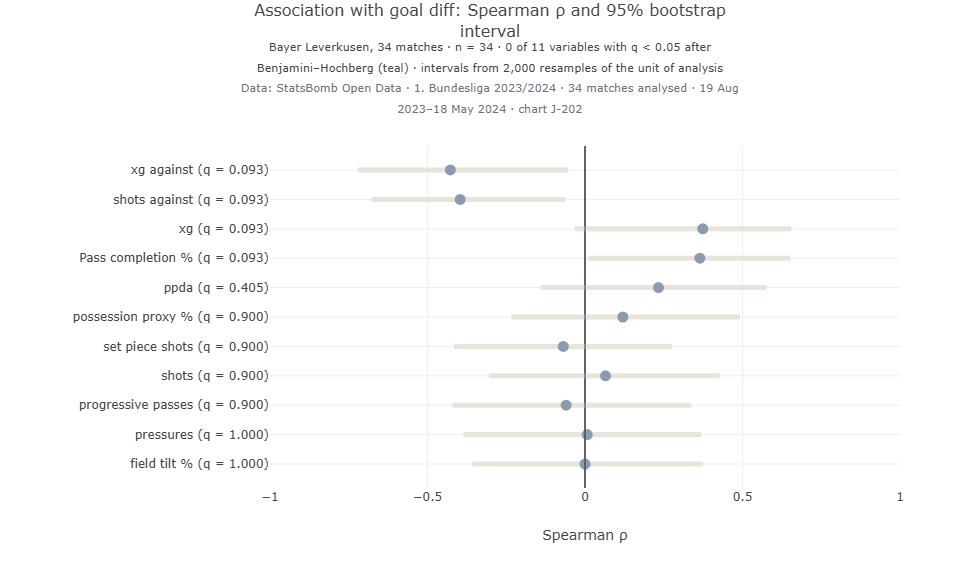

`J-202` Correlation forest plot with confidence intervals · *Method:* Spearman ρ, 2,000 match-level bootstrap resamples, Benjamini–Hochberg. · *Caveat:* One team-season: low power; association only.

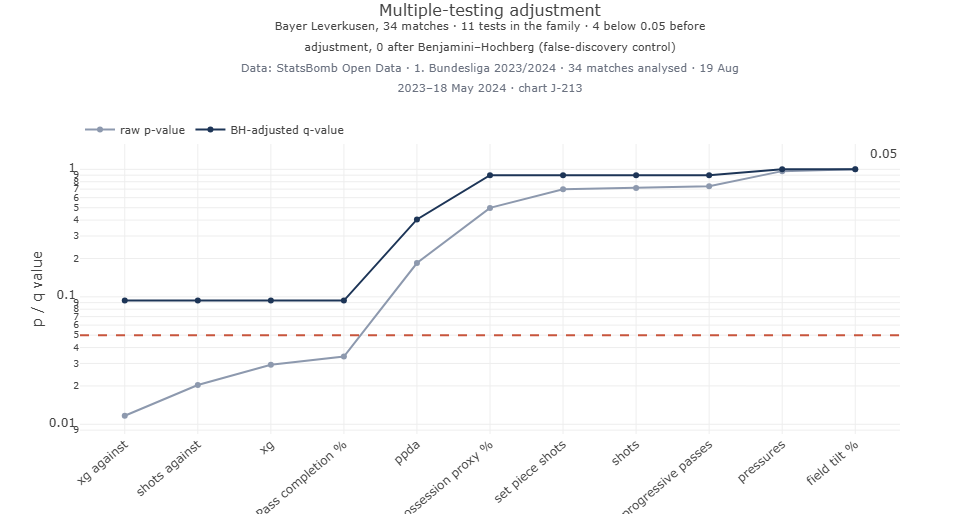

`J-213` Multiple-testing adjusted p-values · *Method:* Raw p vs Benjamini–Hochberg q.

**Interpretation.** Of 11 match variables, 0 remain associated with goal difference after false-discovery control (n = 34 matches). The strongest is xg_against (ρ = -0.43, 95% CI -0.72 to -0.05, q = 0.093); possession proxy shows ρ = 0.12 (q = 0.900).

In [36]:
from src.analytics import statistical_tests as stt
corr = ws.correlations()
display(corr.round(3))
show("J-202", ws)
show("J-213", ws)
top = corr.iloc[0]; poss = corr.set_index("variable").loc["possession_proxy_pct"]
n_sig = int((corr.spearman_q_BH < 0.05).sum())
interpret(f"Of {len(corr)} match variables, {n_sig} remain associated with goal difference after false-discovery control "
          f"(n = {int(top.n)} matches). The strongest is {top.variable} (ρ = {top.spearman_rho:.2f}, 95% CI {top.rho_ci_low:.2f} to "
          f"{top.rho_ci_high:.2f}, q = {top.spearman_q_BH:.3f}); possession proxy shows ρ = {poss.spearman_rho:.2f} (q = {poss.spearman_q_BH:.3f}).")

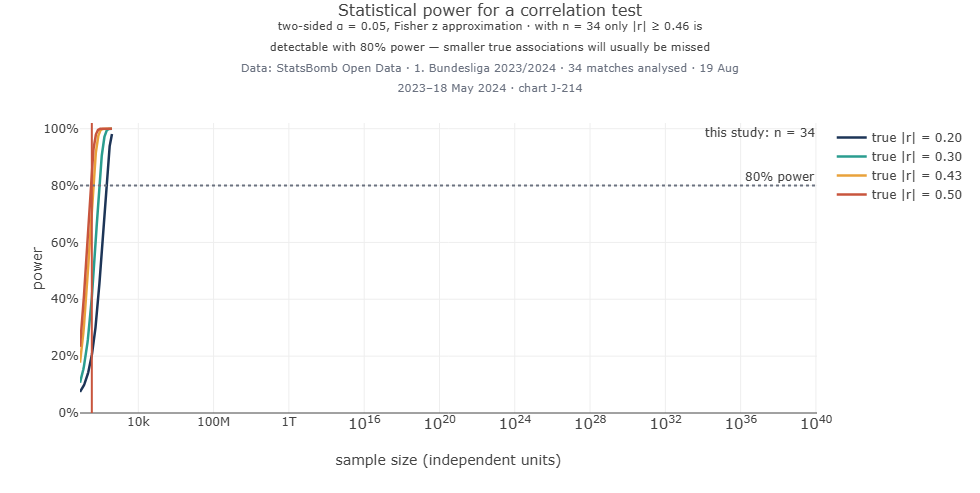

`J-214` Power / sensitivity curve · *Method:* Power of a two-sided correlation test by n. · *Caveat:* Fisher z approximation.

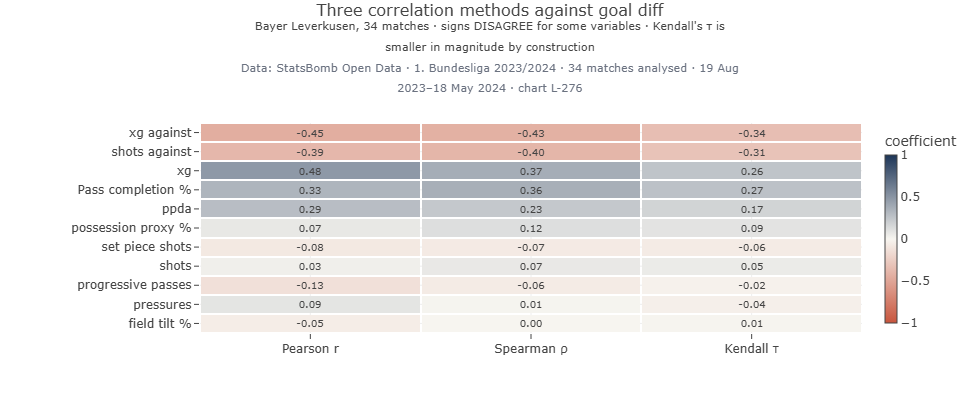

`L-276` Three correlation methods compared · *Method:* Three coefficients per variable.

**Interpretation.** With n = 34 a two-sided test at α = 0.05 has 80% power only for |r| ≥ 0.46. Weaker real associations will usually be missed, so a non-significant result here is not evidence of no relationship. H1 (chance quality matters more than possession) is supported in direction and undecided in significance at this sample size.

**Limitation.** One team-season: opponents and venues are not randomised, and nothing here is a causal estimate.

In [37]:
show("J-214", ws)
show("L-276", ws)
mdr = float(stt.min_detectable_correlation(len(tm)))
interpret(f"With n = {len(tm)} a two-sided test at α = 0.05 has 80% power only for |r| ≥ {mdr:.2f}. Weaker real "
          f"associations will usually be missed, so a non-significant result here is not evidence of no relationship. "
          f"H1 (chance quality matters more than possession) is supported in direction and "
          + ("in significance." if n_sig else "undecided in significance at this sample size."))
limitation("One team-season: opponents and venues are not randomised, and nothing here is a causal estimate.")

,comparison,n_a,n_b,mean_a,mean_b,mean_diff,diff_ci_low,diff_ci_high,p_value,effect_size,magnitude
0,home vs away,17,17,1.599,1.041,0.558,-0.178,1.228,0.098,0.336,medium
1,first half of season vs second half,17,17,1.254,1.387,-0.133,-0.915,0.632,0.731,-0.073,negligible
2,Bayer Leverkusen shot xG vs opponent shot xG,623,293,0.117,0.095,0.022,0.003,0.040,0.079,0.072,negligible


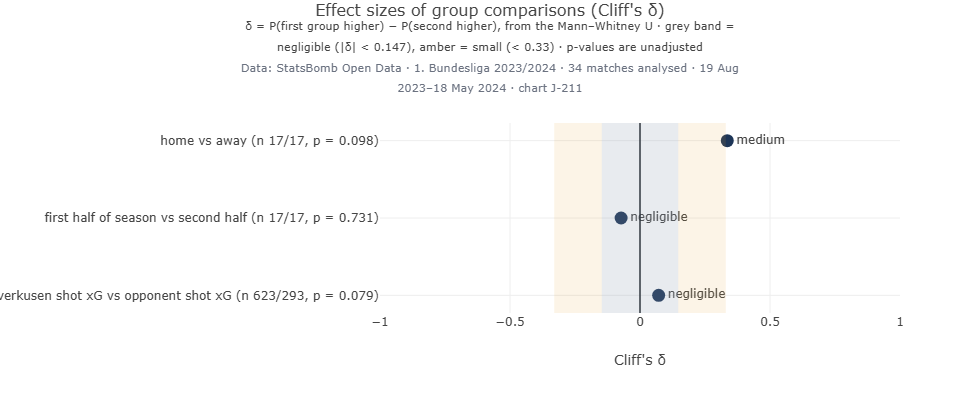

`J-211` Effect-size plot · *Method:* Cliff's δ with magnitude bands. · *Caveat:* p-values shown are unadjusted.

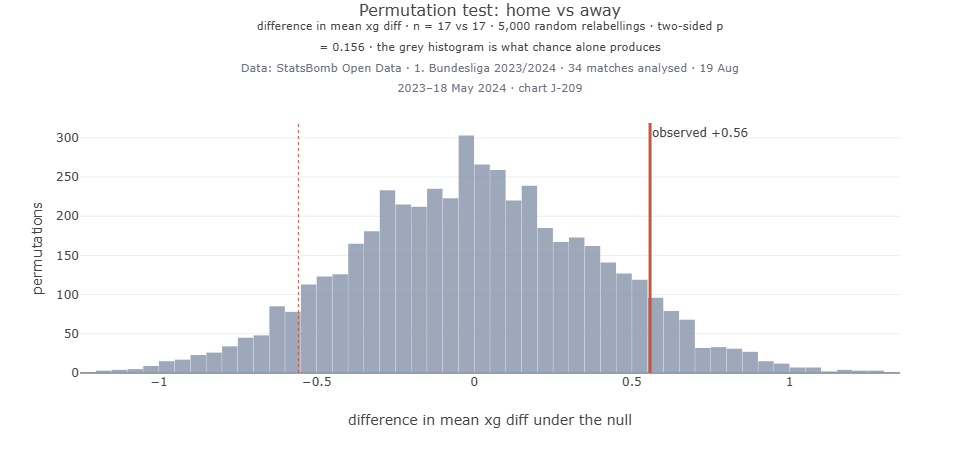

`J-209` Permutation test null distribution · *Method:* 5,000 label permutations.

**Interpretation.** Home minus away xG difference is +0.56 (95% CI -0.18 to +1.23), Cliff's δ = 0.34 (medium), p = 0.098 — suggestive but not established; the interval includes zero.

**Managerial implication.** Not strong enough to justify a different game model by venue on this evidence.

In [38]:
tests = ws.group_tests()
display(pd.DataFrame(tests)[["comparison", "n_a", "n_b", "mean_a", "mean_b", "mean_diff", "diff_ci_low", "diff_ci_high",
                             "p_value", "effect_size", "magnitude"]].round(3))
show("J-211", ws)
show("J-209", ws, team_metric="xg_diff")
v = tests[0]
interpret(f"Home minus away xG difference is {v['mean_diff']:+.2f} (95% CI {v['diff_ci_low']:+.2f} to {v['diff_ci_high']:+.2f}), "
          f"Cliff's δ = {v['effect_size']:.2f} ({v['magnitude']}), p = {v['p_value']:.3f} — "
          + ("statistically significant." if v['p_value'] < 0.05 else "suggestive but not established; the interval includes zero."))
implication("Not strong enough to justify a different game model by venue on this evidence.")

## H · Unsupervised structure: PCA and clustering

**Question.** Do player profiles form distinct types, or a continuum?

**Method.** Fourteen per-90 metrics, standardised, for outfield players above the minutes threshold. Four
algorithms (K-Means, Ward, Gaussian mixture, DBSCAN) and four selection criteria, plus a bootstrap stability
check — so the conclusion does not rest on one method.

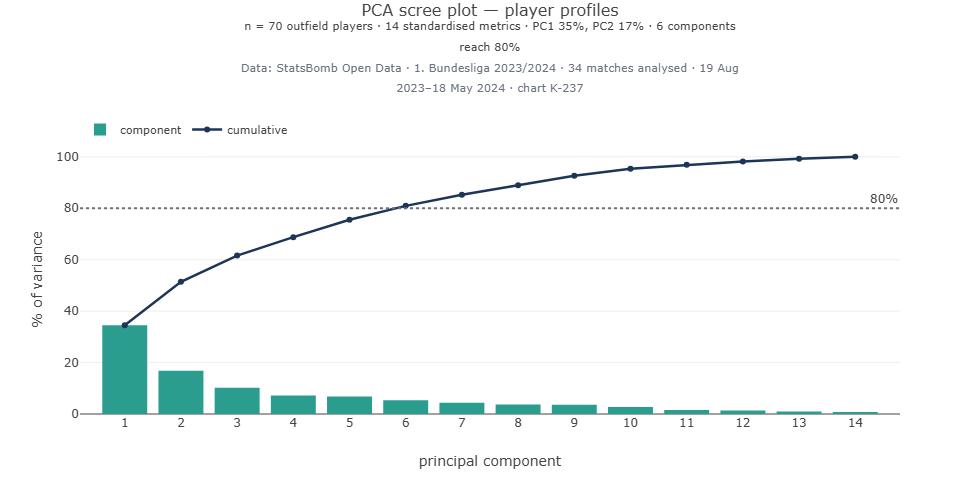

`K-237` PCA scree plot · *Method:* Explained variance with cumulative curve.

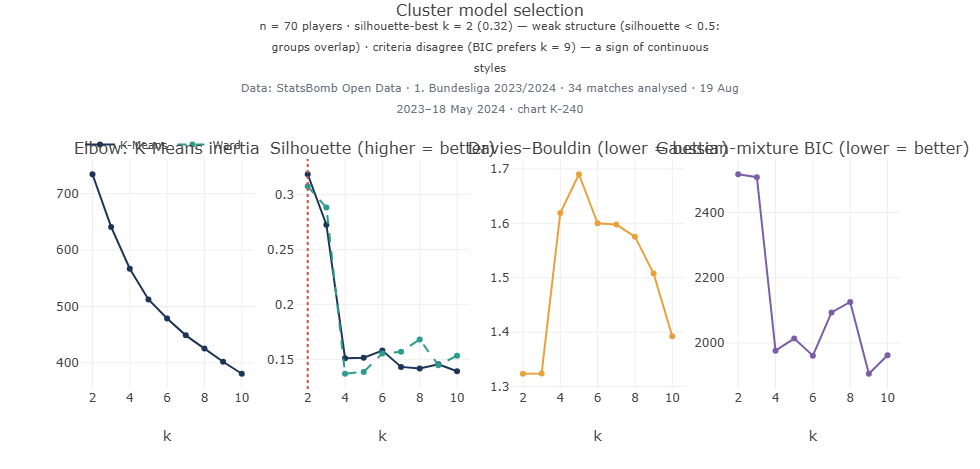

`K-240` Cluster model selection · *Method:* Elbow, silhouette, Davies–Bouldin, GMM BIC.

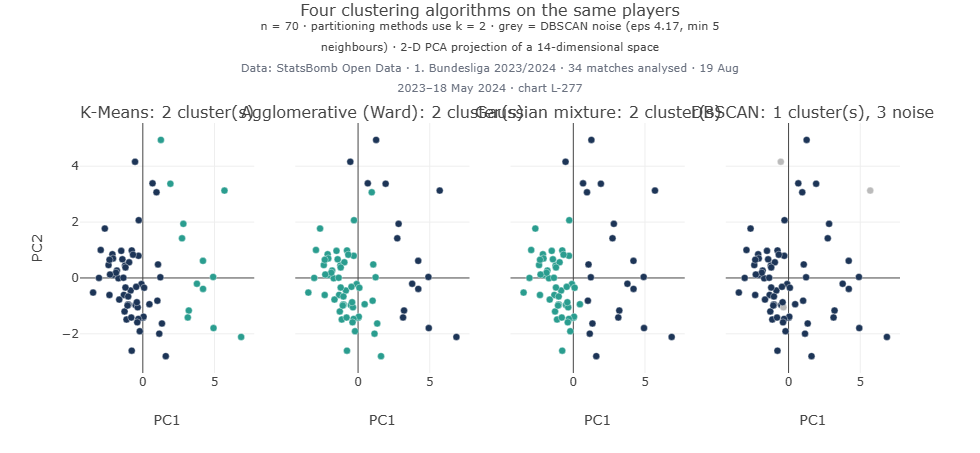

`L-277` Four clustering algorithms projected · *Method:* K-Means, Ward, GMM and DBSCAN labels in PCA space.

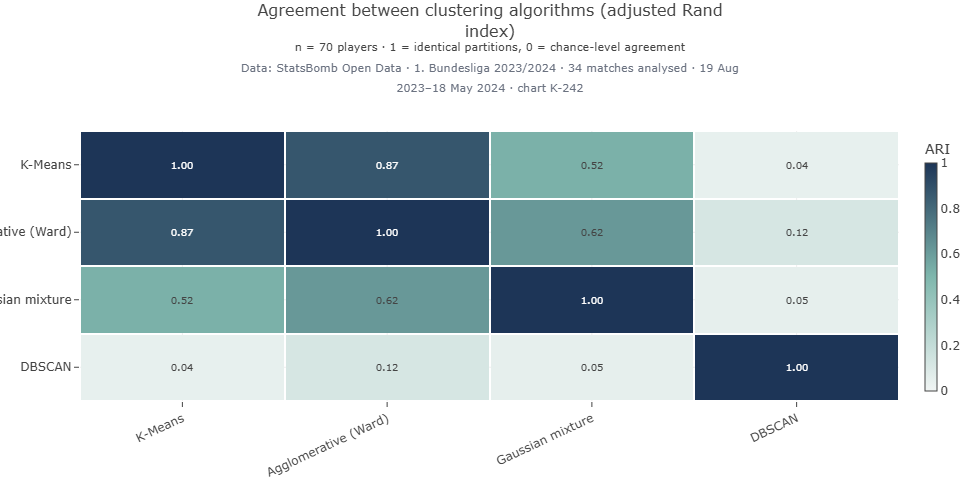

`K-242` Cluster stability / ARI comparison · *Method:* Adjusted Rand index between four algorithms.

**Interpretation.** PC1 and PC2 explain 35% and 17% of the variance across 70 players; 6 components are needed for 80%. Silhouette is best at k = 2 (0.32) while the mixture-model BIC prefers k = 9; DBSCAN finds 1 dense group(s) and 3 outlying players. Bootstrap stability of the K-Means partition: mean ARI 0.75.

**Managerial implication.** Use role-specific metric profiles for squad planning; cluster labels are a vocabulary, not fixed player types.

**Limitation.** Opponent players are observed only in their two matches against the focus team.

In [39]:
pca = ws.pca(); cl = ws.clusters()
show("K-237", ws)
show("K-240", ws)
show("L-277", ws)
show("K-242", ws)
stab = ws.cluster_stability()
interpret(f"PC1 and PC2 explain {pca['explained'][0]:.0%} and {pca['explained'][1]:.0%} of the variance across {pca['n_players']} "
          f"players; {pca['components_for_80pct']} components are needed for 80%. Silhouette is best at k = {cl['k_best']} "
          f"({cl['silhouette_best']:.2f}) while the mixture-model BIC prefers k = {cl['k_bic']}; DBSCAN finds "
          f"{cl['dbscan_clusters']} dense group(s) and {cl['dbscan_noise']} outlying players. Bootstrap stability of the "
          f"K-Means partition: mean ARI {stab.ari.mean():.2f}.")
implication("Use role-specific metric profiles for squad planning; cluster labels are a vocabulary, not fixed "
            "player types.")
limitation("Opponent players are observed only in their two matches against the focus team.")

## Supervised modelling — only where the data support it

**Question.** Can the starting decision be predicted from information available before kick-off, and does a
model beat a simple rule?

**Target.** One row per match-day squad member of the focus team; y = 1 if he started. **Baseline:** he started
the previous match. **Split:** by match in date order (expanding-window cross-validation and a final
chronological hold-out) so no future information reaches a prediction.

**Not modelled:** match results (34 matches, no losses), goals, injuries, fitness, market value — the data do
not support them.

,rows,matches,min_rows,min_matches,class_balance_starter_pct
0,660,33,300,15,55.000


,target not modelled,why
0,Match result (win / draw / loss),34 matches of one team with no losses; the cla...
1,Goals or xG per match (regression),34 observations for a model with several predi...
2,"Injury risk, fitness or fatigue","No injury, medical, GPS or physical-load data ..."
3,Player market value,No valuation or contract data exist in the sou...


,feature,computed from,availability
0,started_prev_match,team's previous match lineup,known before kick-off
1,consecutive_starts_before,previous matches,known before kick-off
2,start_share_before,starts / team matches before this match,known before kick-off
3,minutes_share_before,minutes / (team matches x 95) before this match,known before kick-off
4,minutes_prev_7d / 14d,minutes in earlier matches within 7/14 days,known before kick-off
5,rest_days_filled,days since last appearance (60 if none),known before kick-off
6,is_gk,role from squad match position (event-derived),position played in this match — mild contempor...
7,"EXCLUDED: minutes_played, events, goals in the...",same-match outcomes,would leak — not used


accuracy       precision       recall          f1       roc_auc       pr_auc       brier      
                                     mean   std      mean   std   mean   std  mean   std    mean   std   mean   std  mean   std
model                                                                                                                          
Baseline: started previous match    0.760 0.094     0.796 0.083  0.756 0.097 0.775 0.090     NaN   NaN    NaN   NaN   NaN   NaN
Gradient boosting                   0.760 0.110     0.782 0.100  0.782 0.100 0.782 0.100   0.816 0.099  0.835 0.085 0.194 0.065
Logistic regression                 0.792 0.088     0.811 0.080  0.811 0.080 0.811 0.080   0.838 0.079  0.853 0.071 0.162 0.058
Random forest                       0.768 0.117     0.789 0.106  0.789 0.106 0.789 0.106   0.829 0.102  0.844 0.091 0.164 0.060

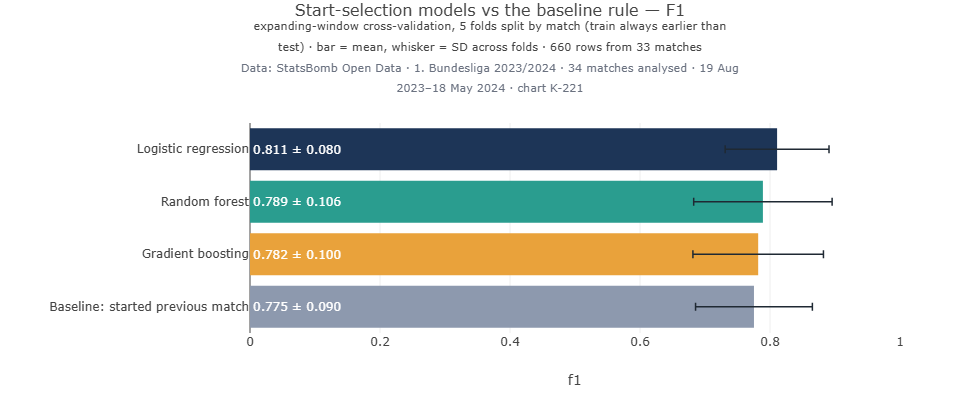

`K-221` Baseline model comparison · *Method:* Expanding-window CV split by match; baseline = started previous match. · *Caveat:* Target = start selection of the focus team; nothing generalises beyond this team-season.

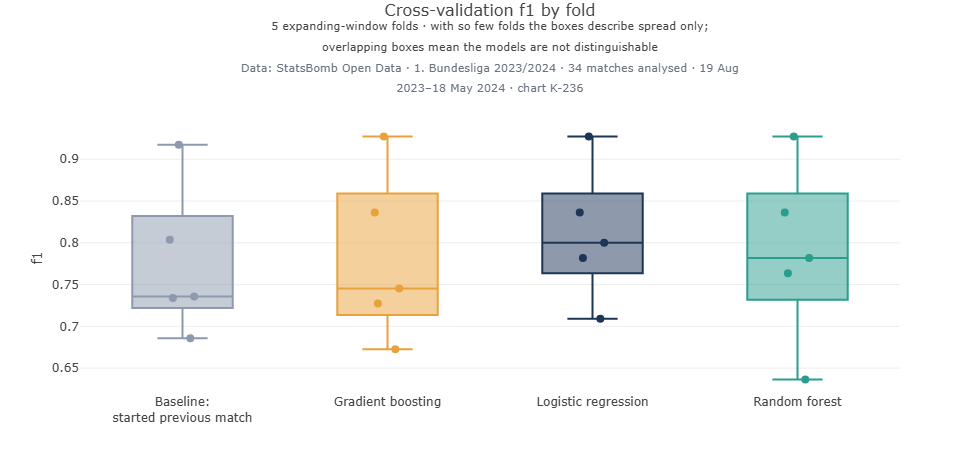

`K-236` Cross-validation score distribution · *Method:* One point per time-ordered fold.

**Interpretation.** Time-ordered cross-validation on 660 rows from 33 matches: F1 Baseline: started previous match 0.775, Gradient boosting 0.782, Logistic regression 0.811, Random forest 0.789. ROC-AUC ranges from 0.816 to 0.838. The best model improves on the baseline rule by 0.036 F1.

In [40]:
from src.analytics import models
with timed("model comparison"):
    res = ws.models()
display(pd.DataFrame([res["gate"]]))
display(pd.DataFrame(models.UNSUPPORTED_TARGETS, columns=["target not modelled", "why"]))
if res["fitted"]:
    display(res["leakage_audit"])
    cs = res["cv_summary"]; display(cs.round(3))
    show("K-221", ws); show("K-236", ws)
    f1 = cs[("f1", "mean")]; auc = cs[("roc_auc", "mean")].dropna()
    interpret(f"Time-ordered cross-validation on {res['gate']['rows']} rows from {res['gate']['matches']} matches: F1 "
              + ", ".join(f"{m} {v:.3f}" for m, v in f1.items())
              + f". ROC-AUC ranges from {auc.min():.3f} to {auc.max():.3f}. The best model improves on the baseline rule by "
              f"{f1.drop(models.BASELINE_NAME).max() - f1[models.BASELINE_NAME]:.3f} F1.")
else:
    interpret(f"No model is fitted: {res['reason']}")

Hold-out: train 23 matches to 03 Mar 2024, test 10 matches from 10 Mar 2024


,model,precision,recall,f1,brier,roc_auc,pr_auc
0,Baseline: started previous match,0.743,0.682,0.711,0.305,NaN,NaN
1,Logistic regression,0.745,0.745,0.745,0.197,0.775,0.797
2,Random forest,0.718,0.718,0.718,0.201,0.753,0.776
3,Gradient boosting,0.700,0.700,0.700,0.237,0.737,0.777


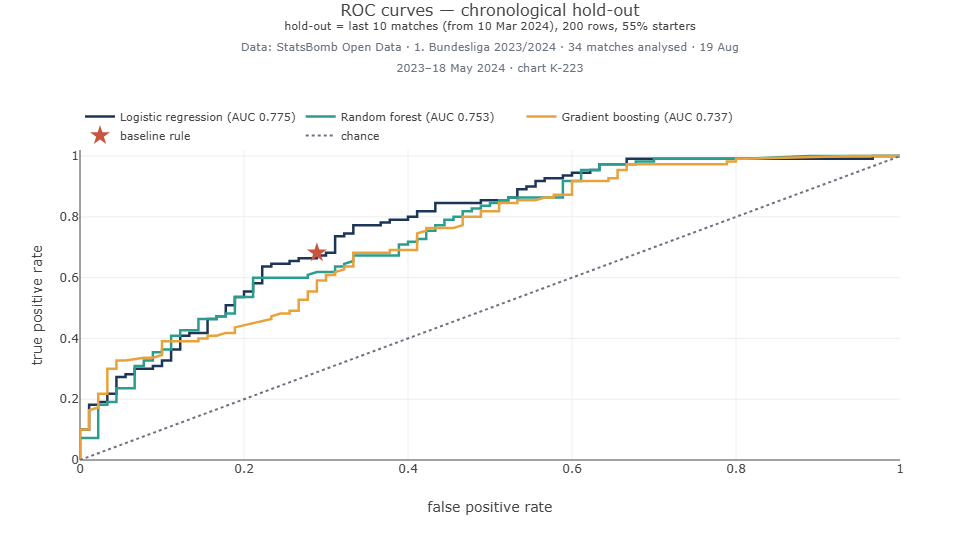

`K-223` ROC curve · *Method:* Chronological hold-out; baseline as a point.

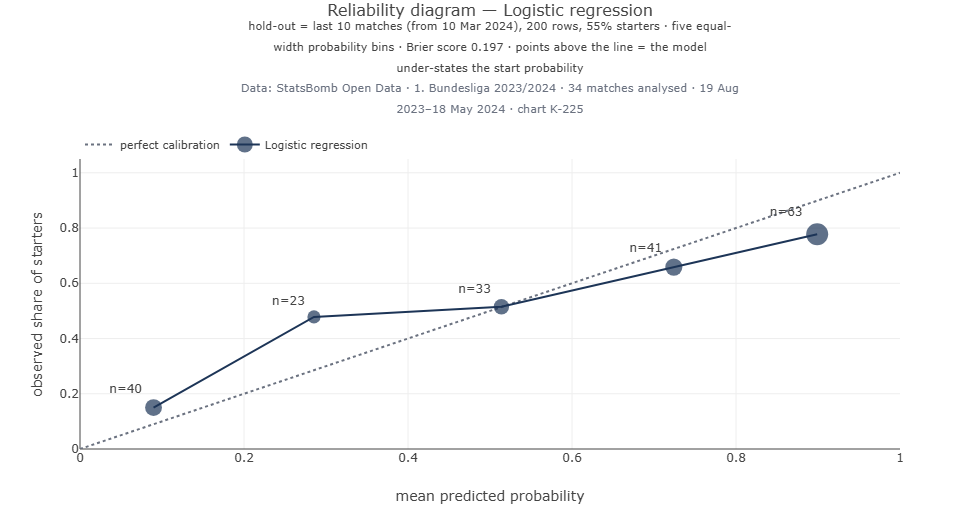

`K-225` Calibration curve · *Method:* Five probability bins with n.

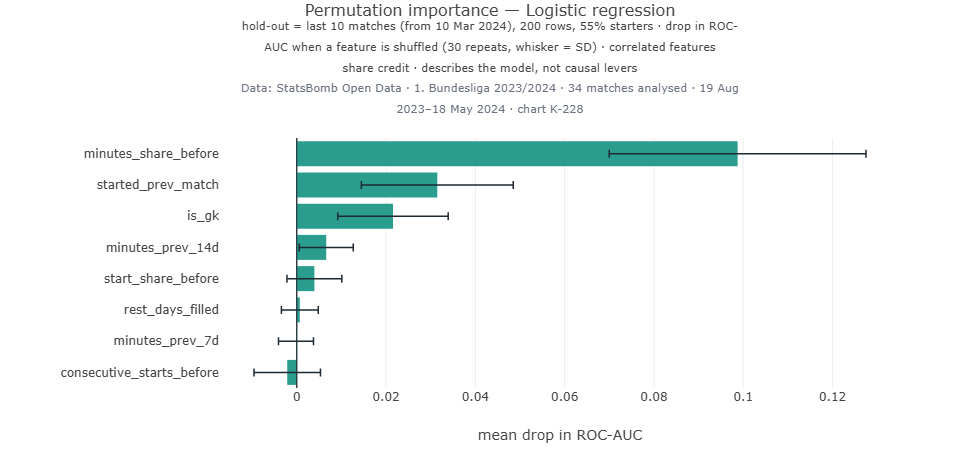

`K-228` Permutation feature importance · *Method:* Drop in hold-out ROC-AUC, 30 repeats. · *Caveat:* Describes the model, not causal levers.

**Interpretation.** On the chronological hold-out Logistic regression ranks starters best (ROC-AUC 0.775, Brier 0.197). Shuffling minutes_share_before costs 0.099 AUC and started_prev_match 0.031: selection follows past selection.

**Managerial implication.** A rule plus season minutes share explains most selections. Analytics adds value in the rotation margin — where the missing availability data matter most.

**Limitation.** Describes this team-season only; importance is conditional on correlated features and is not a causal lever.

In [41]:
if res["fitted"]:
    s = res["split"]; hold = res["holdout"].set_index("model")
    print(f"Hold-out: train {s['train_matches']} matches to {s['train_until']:%d %b %Y}, test {s['test_matches']} matches from {s['test_from']:%d %b %Y}")
    display(res["holdout"].round(3))
    show("K-223", ws); show("K-225", ws); show("K-228", ws)
    perm = ws.permutation()
    interpret(f"On the chronological hold-out {res['best']} ranks starters best (ROC-AUC {hold.loc[res['best'], 'roc_auc']:.3f}, "
              f"Brier {hold.loc[res['best'], 'brier']:.3f}). Shuffling {perm.feature.iloc[-1]} costs {perm.importance_mean.iloc[-1]:.3f} AUC "
              f"and {perm.feature.iloc[-2]} {perm.importance_mean.iloc[-2]:.3f}: selection follows past selection.")
    implication("A rule plus season minutes share explains most selections. Analytics adds value in the rotation "
                "margin — where the missing availability data matter most.")
    limitation("Describes this team-season only; importance is conditional on correlated features and is not a "
               "causal lever.")

---
# Part 06 · Managerial patterns, evidence cards and conclusions

## I · Managerial patterns

**Research question.** What do the recorded decisions show about selection, formation and substitution habits,
and how much of it is certain?

**Scope note.** This describes **observable decisions**. It does not measure a manager's ability or intentions
and cannot separate the manager from the squad he has. Every other manager in the data has two matches,
all against the focus team.

Manager identity source: StatsBomb matches.json (managers field)


,0
manager,Xabi Alonso
team,Bayer Leverkusen
matches,34
sample_status,comparable sample
points_per_match,2.650
xg_diff_per_match,1.320
formations_used,3
most_used_formation,3-4-2-1
most_used_share_pct,73.500
formation_diversity_index,0.610


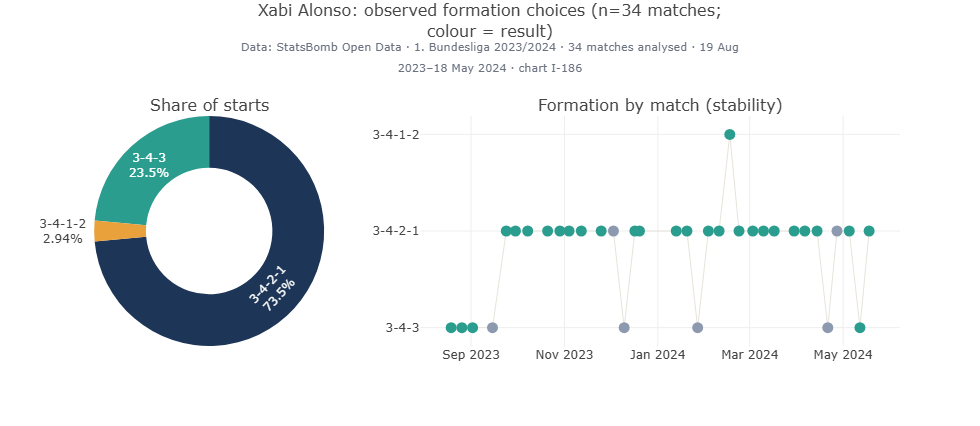

`I-186` Formation usage by manager · *Method:* Observed starting formations and results. · *Caveat:* Observable choices, not managerial ability.

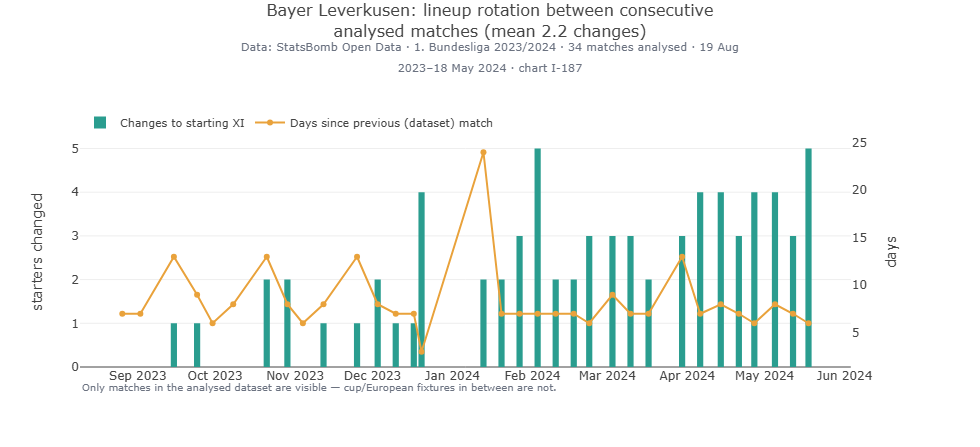

`I-187` Starting XI continuity and rotation trend · *Method:* Lineup changes between consecutive analysed matches. · *Caveat:* Cup and European matches between league games are not in the data.

**Interpretation.** Xabi Alonso (34 matches): 3 starting formations, 3-4-2-1 in 74% of matches; 2.21 changes to the XI between consecutive analysed matches; 4.18 substitutions per match with the first at a median of minute 64.

**Limitation.** Rotation is measured between league matches only; cup and European fixtures in between are missing.

In [42]:
prof = ws.manager_profiles()
mgr = ws.focus_manager()
print("Manager identity source:", B.manager_source)
display(prof[prof.manager == mgr].T)
show("I-186", ws)
show("I-187", ws)
r = prof[prof.manager == mgr].iloc[0]
interpret(f"{mgr} ({int(r.matches)} matches): {int(r.formations_used)} starting formations, {r.most_used_formation} in "
          f"{r.most_used_share_pct:.0f}% of matches; {r.mean_lineup_changes:.2f} changes to the XI between consecutive "
          f"analysed matches; {r.subs_per_match:.2f} substitutions per match with the first at a median of minute "
          f"{r.median_first_sub_minute:.0f}.")
limitation("Rotation is measured between league matches only; cup and European fixtures in between are missing.")

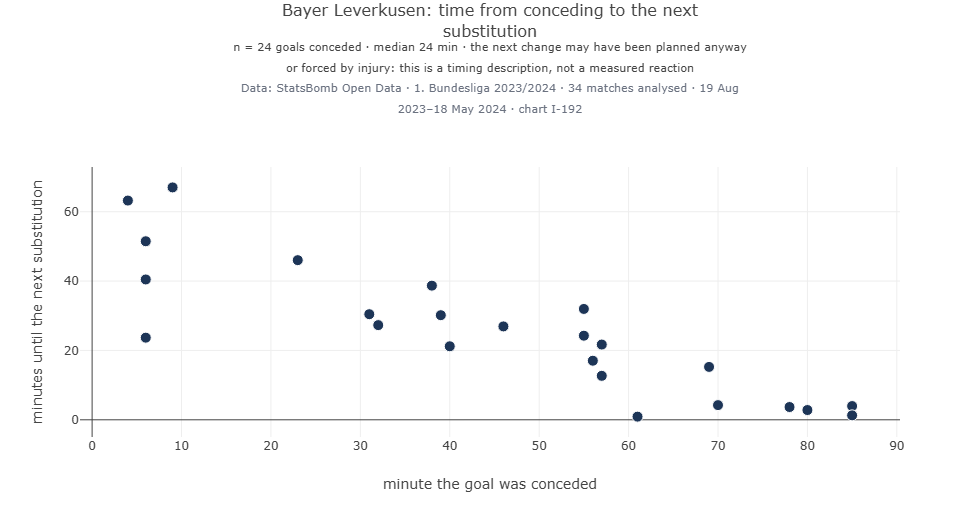

`I-192` Response timeline after conceding · *Method:* Minutes from a goal conceded to the next substitution. · *Caveat:* Timing description, not a measured reaction.

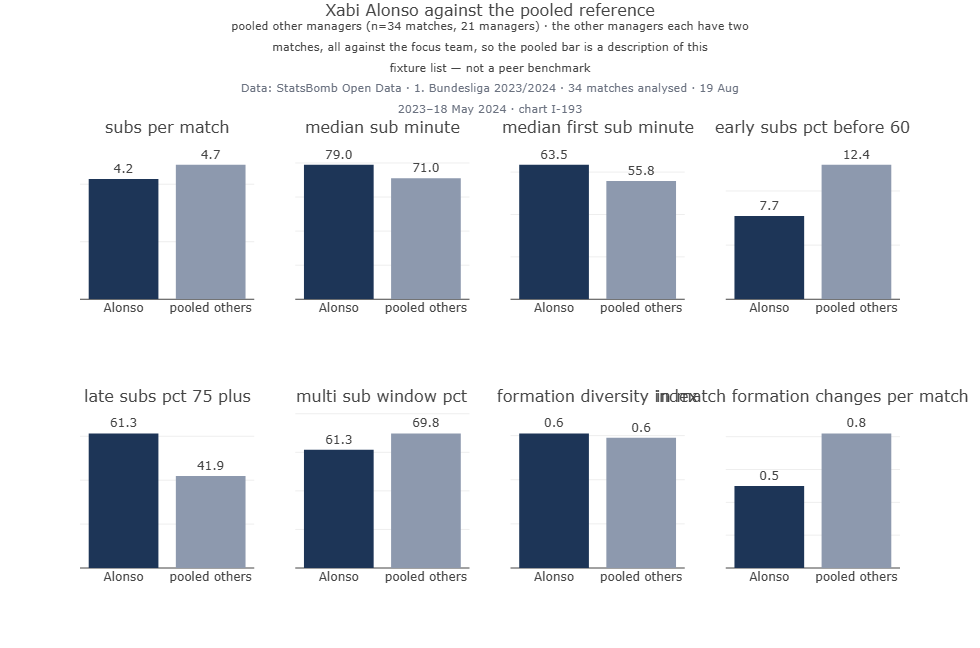

`I-193` Manager comparison small multiples · *Method:* Indicators next to the pooled value of all other managers. · *Caveat:* Other managers have two matches each, all against the focus team.

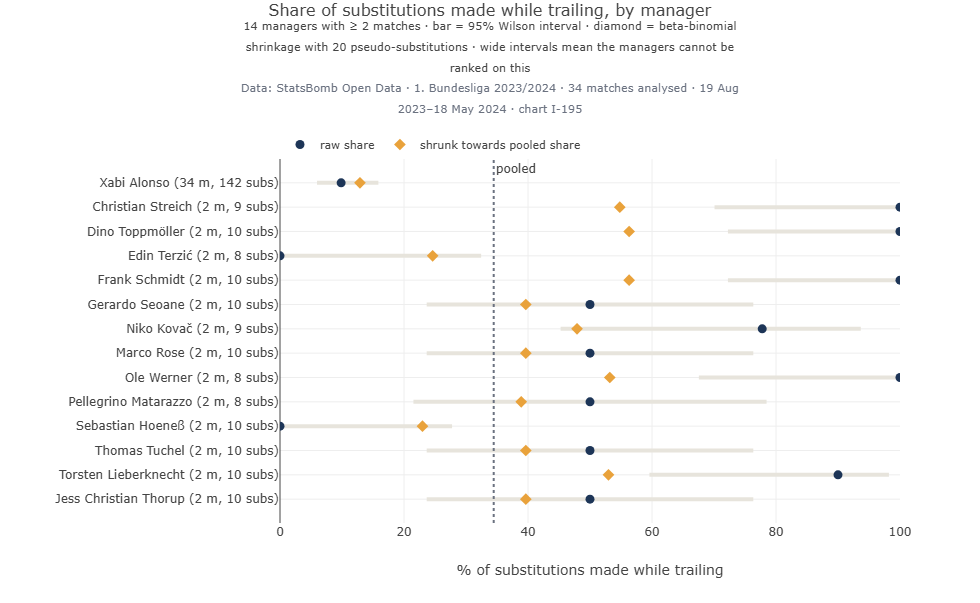

`I-195` Manager pattern uncertainty intervals · *Method:* Wilson intervals and beta-binomial shrinkage. · *Caveat:* Small samples cannot be ranked.

**Interpretation.** 21 of 22 managers have fewer than 10 matches. Their Wilson intervals span most of the scale and shrinkage pulls them to the pooled value — they cannot be ranked or compared with Xabi Alonso as peers.

In [43]:
show("I-192", ws)
show("I-193", ws)
show("I-195", ws)
small = prof[prof.matches < B.config.min_manager_matches]
interpret(f"{len(small)} of {len(prof)} managers have fewer than {B.config.min_manager_matches} matches. Their Wilson intervals "
          f"span most of the scale and shrinkage pulls them to the pooled value — they cannot be ranked or compared "
          f"with {mgr} as peers.")

## Evidence cards

Each card states the finding, the metric and value behind it, the scope, the supporting chart, why it may
matter and what the evidence cannot tell us. The text is assembled from computed values.

In [44]:
from src.reporting import insight_cards
cards = insight_cards.build_cards(ws)
display(Markdown(insight_cards.cards_markdown(cards)))

### 1. Results against chance quality

- **Finding.** Results ran ahead of shot-based expectation by 15.2 points.
- **Evidence.** 90 points vs 74.8 expected points; 89 goals from 72.7 xG (xG difference +1.32 per match).
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `L-262`
- **Managerial relevance.** Anchor performance reviews on chances created and conceded rather than on results alone.
- **What the evidence cannot tell us.** Expected points are a simulation from StatsBomb xG; they ignore game state and assume shots are independent.
- **Suggested next investigation.** Recompute over further seasons to see how much of the gap persists.

### 2. Concentration of chance creation

- **Finding.** Three players account for 40% of the squad's xG + xA.
- **Evidence.** Top three: Victor Boniface, Florian Wirtz, Álex Grimaldo; Gini coefficient of xG + xA across 22 contributors = 0.52.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `B-029`
- **Managerial relevance.** Cover and minutes management for the main creators matter more than for other roles.
- **What the evidence cannot tell us.** xA credits the passer of a shot assist only; off-ball contribution is not in event data.
- **Suggested next investigation.** Check how output changes in matches the top creators did not start.

### 3. Structure of the passing game

- **Finding.** Granit Xhaka is both the main hub and the main bridge of the pass network.
- **Evidence.** Mean PageRank 0.140 (Granit Xhaka); mean betweenness 0.211 (Granit Xhaka); averaged over 32 match networks.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `F-139`
- **Managerial relevance.** A build-up plan that depends on one link is exposed when he is pressed or unavailable.
- **What the evidence cannot tell us.** Networks use completed passes before the first substitution; centrality describes the recorded graph, not player quality.
- **Suggested next investigation.** Compare the network in matches where the hub was marked or absent.

### 4. Selection continuity

- **Finding.** A stable core with rotation at the margins: 7 players started at least three quarters of the matches.
- **Evidence.** Mean 2.2 starting-XI changes between consecutive analysed matches (median 2); 22 players started at least once.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `D-106`
- **Managerial relevance.** Decision support adds most in the two or three slots that actually rotate.
- **What the evidence cannot tell us.** Cup and European fixtures between league matches are not in the data, so rotation across all competitions is understated.
- **Suggested next investigation.** Add the other competitions' lineups to measure true rotation.

### 5. Substitution timing and score state

- **Finding.** Changes are made late and mostly from in front: median minute 79, 79% while leading.
- **Evidence.** 142 substitutions, 4.18 per match; 77% like-for-like by role.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `H-171`
- **Managerial relevance.** Pre-planned, role-compatible replacement pairs fit the observed pattern.
- **What the evidence cannot tell us.** Score state is driven by team strength: a team that usually leads makes most changes while leading whatever its intent.
- **Suggested next investigation.** Compare with matches of similar score state from other teams once more data are loaded.

### 6. Home and away performance

- **Finding.** A home edge in xG difference is suggestive but not established in this sample.
- **Evidence.** Home minus away xG difference +0.56 (95% CI -0.18 to +1.23); Cliff's δ 0.34 (medium); Mann–Whitney p = 0.098; n = 17 vs 17.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `J-211`
- **Managerial relevance.** Not strong enough to justify a different game model by venue.
- **What the evidence cannot tell us.** 17 matches per venue; opponents differ between the home and away sets.
- **Suggested next investigation.** Re-test with additional seasons.

### 7. What moves with goal difference

- **Finding.** 0 of 11 match variables remain associated with goal difference after false-discovery control; the strongest is xg against.
- **Evidence.** Spearman ρ = -0.43 (95% CI -0.72 to -0.05), q = 0.093; n = 34 matches.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `J-202`
- **Managerial relevance.** Chance quality for and against is the most informative match-level lens available here.
- **What the evidence cannot tell us.** One team-season: low power, and an association is not a causal effect.
- **Suggested next investigation.** Pool several seasons to raise power before drawing tactical conclusions.

### 8. Player profiles form a continuum

- **Finding.** Statistical profiles do not separate into distinct player types.
- **Evidence.** Best silhouette 0.32 at k = 2; the mixture-model BIC prefers k = 9; DBSCAN finds 1 dense group(s) with 3 outlying players; n = 70.
- **Scope.** 70 outfield players above the minutes threshold in the dataset
- **Supporting chart.** `K-240`
- **Managerial relevance.** Use role-specific metric profiles for squad planning rather than cluster labels.
- **What the evidence cannot tell us.** Opponent players are observed only in their matches against the focus team.
- **Suggested next investigation.** Repeat on full-league data, where every team has a full season of evidence.

### 9. How predictable is selection

- **Finding.** Past selection explains most starts; models add little over the simple rule.
- **Evidence.** Time-ordered cross-validation F1: Logistic regression 0.811 vs 0.775 for 'started the previous match'; hold-out ROC-AUC 0.775; 660 rows from 33 matches.
- **Scope.** Bayer Leverkusen, 34 matches, 1. Bundesliga 2023/2024 (19 Aug 2023 – 18 May 2024)
- **Supporting chart.** `K-221`
- **Managerial relevance.** Selection follows continuity; rotation decisions hinge on information the data lack.
- **What the evidence cannot tell us.** No fitness, injury, training or opponent-specific information exists in the source.
- **Suggested next investigation.** Add availability data before attempting to model rotation.


## J · Answers to the research questions and hypotheses

In [45]:
from src.analytics import descriptive as desc
from src.reporting.report_builder import results_snapshot
snap = results_snapshot(ws)
corr = ws.correlations().set_index("variable")
xg_side = corr.loc[["xg", "xg_against"], "spearman_rho"].abs().max()
answers = pd.DataFrame([
    ("H1 chance quality vs possession", f"|ρ| up to {xg_side:.2f} for xG for/against vs {abs(corr.loc['possession_proxy_pct', 'spearman_rho']):.2f} for possession proxy; "
     f"{snap['corr_significant_after_fdr']} of {len(corr)} variables significant after FDR", "direction supported; significance undecided at n = 34"),
    ("H2 results vs expectation", f"{snap['points']:.0f} points vs {snap['xpts']} expected points", "supported (model-based reference)"),
    ("H3 concentration of chance creation", f"top three = {snap['top3_chance_share']:.0%} of xG + xA", "supported"),
    ("H4 hub players", f"highest PageRank: {snap['hub_pagerank']}; highest betweenness: {snap['hub_betweenness']}", "supported (descriptive)"),
    ("H5 selection follows past selection", f"CV F1 {snap['cv_f1'][snap['best_model']]:.3f} vs {snap['cv_f1']['Baseline: started previous match']:.3f} baseline"
     if snap.get("model_fitted") else "model gate not met", "supported: small gain over the rule" if snap.get("model_fitted") else "not testable"),
    ("H6 substitution timing by score state", f"shortlist top-3 contains the actual substitute in {snap['sub_top3_share']:.0%} of cases", "descriptive only; confounded by team strength"),
], columns=["hypothesis", "evidence from this run", "verdict"])
display(answers)

,hypothesis,evidence from this run,verdict
0,H1 chance quality vs possession,|ρ| up to 0.43 for xG for/against vs 0.12 for ...,direction supported; significance undecided at...
1,H2 results vs expectation,90 points vs 74.8 expected points,supported (model-based reference)
2,H3 concentration of chance creation,top three = 40% of xG + xA,supported
3,H4 hub players,highest PageRank: Granit Xhaka; highest betwee...,supported (descriptive)
4,H5 selection follows past selection,CV F1 0.811 vs 0.775 baseline,supported: small gain over the rule
5,H6 substitution timing by score state,shortlist top-3 contains the actual substitute...,descriptive only; confounded by team strength


## Conclusions, limitations and next steps

**What the evidence supports.** The focus team's results rest on a large and consistent advantage in chance
volume; the points total ran ahead of shot-based expectation; chance creation and build-up are concentrated in
a few players; selection is dominated by a stable core; substitutions are late and mostly made from in front.

**What it does not support.** Any causal claim; any statement about the league or other teams' seasons; any
ranking of managers; any conclusion about fitness, injuries or fatigue.

**Limitations.** One team-season of league matches; opponents seen twice; no injury, fitness, tracking,
age or market data; xG, expected points and Expected Threat are model outputs; heuristic scores are valid only
under their stated weights.

**Next steps.** (1) Add several complete league seasons for benchmarks independent of one club. (2) Add the
other competitions the team played to measure real rotation. (3) Obtain availability data from an authorised
source before modelling rotation. (4) Use tracking or 360 data for off-ball questions. (5) Re-test the venue and
correlation findings with more matches.

In [46]:
# Machine-readable results of this run (the same numbers the reports are built from)
import json
print(json.dumps({k: v for k, v in snap.items() if k != "chart_status"}, indent=1, default=str, ensure_ascii=False))
display(timings().sort_values("seconds", ascending=False).head(10))

{
 "generated_utc": "2026-11-11 11:42 UTC",
 "focus_team": "Bayer Leverkusen",
 "synthetic": false,
 "matches": 34,
 "events": 137765,
 "players_in_squads": 460,
 "teams": 18,
 "raw_files": 70,
 "raw_mb": 120.05,
 "quality_checks": "16/16",
 "wins": 28,
 "draws": 6,
 "losses": 0,
 "points": 90.0,
 "xpts": 74.8,
 "goals_for": 89,
 "goals_against": 24,
 "xg_for": 72.7,
 "xg_against": 27.8,
 "top3_chance_share": 0.401,
 "hub_pagerank": "Granit Xhaka",
 "hub_betweenness": "Granit Xhaka",
 "corr_significant_after_fdr": 0,
 "corr_top": {
  "variable": "xg_against",
  "rho": -0.428,
  "ci": [
   -0.722,
   -0.054
  ],
  "q": 0.093,
  "n": 34
 },
 "venue": {
  "delta": 0.336,
  "p": 0.098,
  "mean_diff": 0.56
 },
 "xt": {
  "grid": "16x12",
  "moves": 71583,
  "shots": 916,
  "iterations": 79,
  "converged": true,
  "max_value": 0.293
 },
 "pca": {
  "pc1": 0.346,
  "pc2": 0.168,
  "components_for_80pct": 6,
  "players": 70
 },
 "clustering": {
  "k_best": 2,
  "silhouette": 0.318,
  "k_bic": 

,step,seconds
59,substitution backtest,31.610
50,XI backtest,10.070
72,model comparison,5.520
30,chart D-102,2.750
77,chart K-228,2.740
6,chart A-006,2.670
0,load workspace,2.550
52,chart H-171,2.490
29,chart D-079,2.470
80,chart I-192,2.470
